# CityLearn RLMPC (Gnu‑RL style) — Offline Imitation (January) + Online SAC (February)

This notebook implements a **practical** Gnu‑RL style pipeline in **CityLearn**:

- **Offline (January):** train a *differentiable, RC‑based MPC* policy by **imitation learning** on `january_pi_dataset.npz`.
- **Online (February):** refine performance using **SAC** via a **residual RL** design:

\[
u_t = \mathrm{clip}(u^{\mathrm{MPC}}_t + \Delta u^{\mathrm{RL}}_t)
\]

Why residual SAC?
- It is **stable** and **SB3‑friendly**.
- MPC keeps comfort/physics structure; SAC learns what MPC misses (unmodeled gains, occupancy, forecast errors).

> If you later want “pure” differentiable MPC-as-policy (SAC updating MPC parameters directly), you can extend the same `DiffMPC` module here and plug it into a custom SB3 policy class. This notebook gets you a **working end‑to‑end pipeline first**.


In [46]:
#KEEP
# ---- 0) Imports & project paths (adapt to your repo layout) ----
import os, sys, math, json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

# CityLearn imports (your repo-in-notebook pattern)
NOTEBOOK_DIR = Path(os.getcwd())
REPO_DIR = NOTEBOOK_DIR.parent
sys.path.insert(0, str(REPO_DIR))

import citylearn
from citylearn.citylearn import CityLearnEnv
from citylearn.wrappers import NormalizedObservationWrapper, StableBaselines3Wrapper

# SB3 / gym
import gymnasium as gym
from stable_baselines3 import SAC
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.callbacks import EvalCallback

print("✅ citylearn:", citylearn.__file__)
print("✅ repo:", REPO_DIR)

# ---- 1) Dataset paths (Annex96 Vermont) ----
CLIMATE = "VT"
DATASET_DIR = REPO_DIR / "data" / "datasets" / f"annex96_ce1_{CLIMATE.lower()}_neighborhood"
SCHEMA_PATH = DATASET_DIR / "schema.json"

with open(SCHEMA_PATH, "r") as f:
    schema = json.load(f)

# Use your building selection or hard-code one
BUILDING_NAME = "resstock-amy2018-2021-release-1-247942"
BUILDINGS = [BUILDING_NAME]

print("Dataset:", DATASET_DIR, "exists:", DATASET_DIR.exists())
print("Schema:", SCHEMA_PATH, "exists:", SCHEMA_PATH.exists())
print("Building:", BUILDING_NAME)


✅ citylearn: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/__init__.py
✅ repo: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1
Dataset: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/data/datasets/annex96_ce1_vt_neighborhood exists: True
Schema: /home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/data/datasets/annex96_ce1_vt_neighborhood/schema.json exists: True
Building: resstock-amy2018-2021-release-1-247942


In [47]:
#KEEP
import importlib, helpers
importlib.reload(helpers)
from helpers import select_buildings, select_simulation_period, get_kpis, plot_building_kpis, plot_district_kpis, plot_building_load_profiles, plot_district_load_profiles, plot_battery_soc_profiles, plot_comfort, plot_comfort_with_lstm_1step, make_env, run_env





In [48]:
device = 'cuda' if torch.cuda.is_available else 'cpu'
print(device)

cuda


In [49]:

# ---- 2) Build CityLearn env: HVAC-only (heating_device) ----
CENTRAL_AGENT = True
GLOBAL_EXPERIMENT_SEED = 49

def make_env(sim_start: int, sim_end: int, **kwargs) -> CityLearnEnv:
    base_kwargs = dict(
        schema=str(SCHEMA_PATH),
        root_directory=str(DATASET_DIR),
        central_agent=CENTRAL_AGENT,
        buildings=BUILDINGS,
        simulation_start_time_step=sim_start,
        simulation_end_time_step=sim_end,
        random_seed=GLOBAL_EXPERIMENT_SEED,
        active_actions=["heating_device"],  # adjust if you use cooling or combined
    )
    base_kwargs.update(kwargs)
    env = CityLearnEnv(**base_kwargs)
    env = NormalizedObservationWrapper(env)
    env = StableBaselines3Wrapper(env)
    return env

# ---- 3) Define January & February windows (hours) ----
JAN_START, JAN_END = 0, 743  # 31 days * 24h

# February: default 28 days right after January
FEB_START = JAN_END + 1
FEB_END   = FEB_START + 28*24 - 1

print("January:", JAN_START, JAN_END, "hours:", JAN_END - JAN_START + 1)
print("February:", FEB_START, FEB_END, "hours:", FEB_END - FEB_START + 1)

env_jan = make_env(JAN_START, JAN_END)
env_feb = make_env(FEB_START, FEB_END)

print("✅ env_jan obs/action:", env_jan.observation_space, env_jan.action_space)


January: 0 743 hours: 744
February: 744 1415 hours: 672


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

✅ env_jan obs/action: Box(0.0, 1.0, (30,), float32) Box(0.0, 1.0, (1,), float32)


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [50]:

# ---- 4) Load your offline dataset: january_pi_dataset.npz ----
DATA_PATH = NOTEBOOK_DIR / "january_pi_dataset.npz"  # change if stored elsewhere
data = np.load(DATA_PATH)

states      = data["states"].astype(np.float32)
actions_exp = data["actions"].astype(np.float32)
rewards     = data["rewards"].astype(np.float32)
next_states = data["next_states"].astype(np.float32)
dones       = data["dones"].astype(np.float32)

print("states:", states.shape, "actions:", actions_exp.shape)

# Convenience: flatten action if needed
if actions_exp.ndim == 3 and actions_exp.shape[1] == 1:
    actions_exp = actions_exp[:, 0, :]

obs_names = env_jan.unwrapped.observation_names
act_names = env_jan.unwrapped.action_names

print("Observation names (wrapped order):")
for i, n in enumerate(obs_names):
    print(i, n)
print("\nAction names:", act_names)


states: (743, 1, 28) actions: (743, 1, 1)
Observation names (wrapped order):
0 ['month', 'hour', 'outdoor_dry_bulb_temperature', 'direct_solar_irradiance', 'outdoor_dry_bulb_temperature_predicted_1', 'outdoor_dry_bulb_temperature_predicted_2', 'outdoor_dry_bulb_temperature_predicted_3', 'direct_solar_irradiance_predicted_1', 'direct_solar_irradiance_predicted_2', 'direct_solar_irradiance_predicted_3', 'indoor_dry_bulb_temperature', 'non_shiftable_load', 'dhw_demand', 'cooling_demand', 'heating_demand', 'solar_generation', 'indoor_dry_bulb_temperature_cooling_set_point', 'indoor_dry_bulb_temperature_heating_set_point', 'comfort_band', 'indoor_dry_bulb_temperature_cooling_delta', 'indoor_dry_bulb_temperature_heating_delta', 'hvac_mode', 'electrical_storage_soc', 'net_electricity_consumption', 'cooling_electricity_consumption', 'heating_electricity_consumption', 'dhw_electricity_consumption', 'electrical_storage_electricity_consumption']

Action names: [['heating_device']]


In [51]:
# Rebuild flattened observation name list
obs_names = env_jan.unwrapped.observation_names

if isinstance(obs_names[0], list):
    flat_obs_names = [n for sub in obs_names for n in sub]
else:
    flat_obs_names = obs_names

print("Total observations:", len(flat_obs_names))
print()

for i, n in enumerate(flat_obs_names):
    print(i, n)

Total observations: 28

0 month
1 hour
2 outdoor_dry_bulb_temperature
3 direct_solar_irradiance
4 outdoor_dry_bulb_temperature_predicted_1
5 outdoor_dry_bulb_temperature_predicted_2
6 outdoor_dry_bulb_temperature_predicted_3
7 direct_solar_irradiance_predicted_1
8 direct_solar_irradiance_predicted_2
9 direct_solar_irradiance_predicted_3
10 indoor_dry_bulb_temperature
11 non_shiftable_load
12 dhw_demand
13 cooling_demand
14 heating_demand
15 solar_generation
16 indoor_dry_bulb_temperature_cooling_set_point
17 indoor_dry_bulb_temperature_heating_set_point
18 comfort_band
19 indoor_dry_bulb_temperature_cooling_delta
20 indoor_dry_bulb_temperature_heating_delta
21 hvac_mode
22 electrical_storage_soc
23 net_electricity_consumption
24 cooling_electricity_consumption
25 heating_electricity_consumption
26 dhw_electricity_consumption
27 electrical_storage_electricity_consumption


In [52]:
print("\nIDX heating_demand:",
      flat_obs_names.index("heating_demand") if "heating_demand" in flat_obs_names else "NOT FOUND")

print("IDX heating_electricity_consumption:",
      flat_obs_names.index("heating_electricity_consumption") if "heating_electricity_consumption" in flat_obs_names else "NOT FOUND")

print("Has heating_device_efficiency?:",
      "heating_device_efficiency" in flat_obs_names)


IDX heating_demand: 14
IDX heating_electricity_consumption: 25
Has heating_device_efficiency?: False


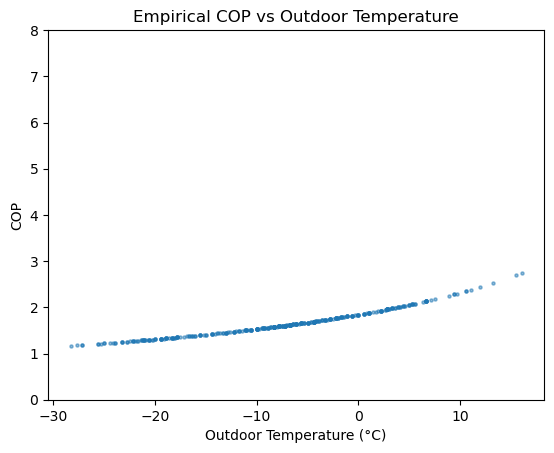

COP range: 1.1676267 2.7401364


In [53]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Reload dataset ----
data = np.load("january_pi_dataset.npz")

states_np = data["states"][:, 0, :].astype(np.float32)

# ---- Rebuild flat_obs_names from env ----
obs_names = env_jan.unwrapped.observation_names
if isinstance(obs_names[0], list):
    flat_obs_names = [n for sub in obs_names for n in sub]
else:
    flat_obs_names = obs_names

# ---- Get indices ----
IDX_T_IN   = flat_obs_names.index("indoor_dry_bulb_temperature")
IDX_T_OUT  = flat_obs_names.index("outdoor_dry_bulb_temperature")
IDX_Q      = flat_obs_names.index("heating_demand")
IDX_P      = flat_obs_names.index("heating_electricity_consumption")

# ---- Extract signals ----
Tin  = states_np[:, IDX_T_IN]
Tout = states_np[:, IDX_T_OUT]
Q    = states_np[:, IDX_Q]
P    = states_np[:, IDX_P]

# ---- Filter valid heating periods ----
mask = P > 0.1   # avoid division noise
COP = Q[mask] / P[mask]
Tout_valid = Tout[mask]

# ---- Plot ----
plt.scatter(Tout_valid, COP, s=5, alpha=0.5)
plt.xlabel("Outdoor Temperature (°C)")
plt.ylabel("COP")
plt.title("Empirical COP vs Outdoor Temperature")
plt.ylim(0, 8)
plt.show()

print("COP range:", COP.min(), COP.max())

## 5) Map observation vector → RC states / disturbances

Set indices for:
- `IDX_T_IN` (indoor temperature)
- `IDX_T_OUT` (outdoor temperature)
- optionally `IDX_T_SP` (setpoint)

Run the helper search first, then set the indices and re-run the cell.


In [54]:
# ---- Flatten observation names (CityLearn central agent) ----

if isinstance(obs_names[0], list):
    flat_obs_names = [n for sub in obs_names for n in sub]
else:
    flat_obs_names = obs_names


IDX_T_IN  = None
IDX_T_OUT = None
IDX_T_SP  = None  # optional


def find_idx(substr: str):
    return [(i, n) for i, n in enumerate(flat_obs_names) if substr.lower() in n.lower()]


print("Candidates for indoor temp:", find_idx("indoor"))
print("Candidates for outdoor temp:", find_idx("outdoor"))
print("Candidates for setpoint:", find_idx("setpoint"))


Candidates for indoor temp: [(10, 'indoor_dry_bulb_temperature'), (16, 'indoor_dry_bulb_temperature_cooling_set_point'), (17, 'indoor_dry_bulb_temperature_heating_set_point'), (19, 'indoor_dry_bulb_temperature_cooling_delta'), (20, 'indoor_dry_bulb_temperature_heating_delta')]
Candidates for outdoor temp: [(2, 'outdoor_dry_bulb_temperature'), (4, 'outdoor_dry_bulb_temperature_predicted_1'), (5, 'outdoor_dry_bulb_temperature_predicted_2'), (6, 'outdoor_dry_bulb_temperature_predicted_3')]
Candidates for setpoint: []


In [55]:
# ---- Final fixed indices for Annex-96 VT ----

IDX_T_IN  = 10   # indoor_dry_bulb_temperature
IDX_T_OUT = 2    # outdoor_dry_bulb_temperature
IDX_T_SP  = 17   # heating setpoint (same as cooling in this dataset)

print("Using IDX_T_IN :", IDX_T_IN,  flat_obs_names[IDX_T_IN])
print("Using IDX_T_OUT:", IDX_T_OUT, flat_obs_names[IDX_T_OUT])
print("Using IDX_T_SP :", IDX_T_SP,  flat_obs_names[IDX_T_SP])


Using IDX_T_IN : 10 indoor_dry_bulb_temperature
Using IDX_T_OUT: 2 outdoor_dry_bulb_temperature
Using IDX_T_SP : 17 indoor_dry_bulb_temperature_heating_set_point


## 6) 1R1C model + differentiable “unrolled MPC”

We use a 2‑state model:

- `x[0] = T_in` (indoor)
- `x[1] = T_env` (envelope / mass, latent)

The MPC is differentiable by **unrolling** a few gradient steps on the action sequence in PyTorch.


In [56]:
import numpy as np

data = np.load("january_pi_dataset.npz")

print("Keys in dataset:", list(data.keys()))
print()

for k in data.keys():
    arr = data[k]
    print(f"{k}:")
    print("  shape:", arr.shape)
    print("  dtype:", arr.dtype)
    print()


Keys in dataset: ['states', 'actions', 'rewards', 'next_states', 'dones']

states:
  shape: (743, 1, 28)
  dtype: float32

actions:
  shape: (743, 1, 1)
  dtype: float32

rewards:
  shape: (743, 1)
  dtype: float32

next_states:
  shape: (743, 1, 28)
  dtype: float32

dones:
  shape: (743,)
  dtype: float32



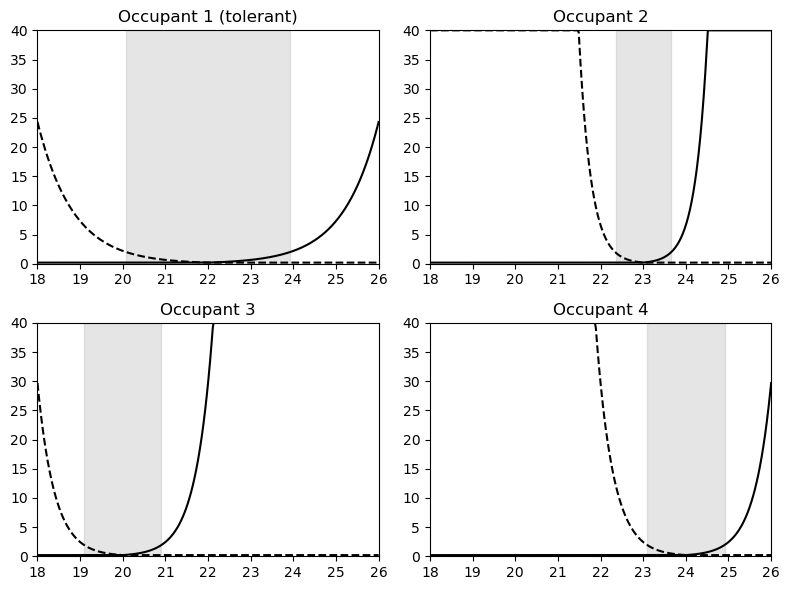

In [57]:
# here malaka
import numpy as np
import matplotlib.pyplot as plt

T = np.linspace(18, 26, 400)

occupant_profiles = [
    {"name": "Occupant 1 (tolerant)", "comfort": 22, "b": 1.2},
    {"name": "Occupant 2", "comfort": 23, "b": 3.5},
    {"name": "Occupant 3", "comfort": 20, "b": 2.5},
    {"name": "Occupant 4", "comfort": 24, "b": 2.5},
]

def prob_increase(T, T_comf, b):
    delta = np.maximum(0, T_comf - T)
    p = 0.002 * np.exp(b * delta)
    return np.clip(p, 0, 0.40)

def prob_decrease(T, T_comf, b):
    delta = np.maximum(0, T - T_comf)
    p = 0.002 * np.exp(b * delta)
    return np.clip(p, 0, 0.40)

fig, axs = plt.subplots(2,2, figsize=(8,6))

for ax, occ in zip(axs.flatten(), occupant_profiles):

    p_inc = prob_increase(T, occ["comfort"], occ["b"])
    p_dec = prob_decrease(T, occ["comfort"], occ["b"])

    ax.plot(T, p_dec*100, label="Decrease", color="black")
    ax.plot(T, p_inc*100, "--", label="Increase", color="black")

    # comfort zone condition
    comfort = (p_inc < 0.02) & (p_dec < 0.02)

    ax.fill_between(T, 0, 40, where=comfort, color="grey", alpha=0.2)

    ax.set_title(occ["name"])
    ax.set_xlim(18,26)
    ax.set_ylim(0,40)

plt.tight_layout()
plt.show()

In [58]:
from citylearn.citylearn import CityLearnEnv
from citylearn.reward_function import ComfortReward
def make_env_raw(
    sim_start,
    sim_end,
    reward_function=None,
    **kwargs
):
    base_kwargs = dict(
        schema=str(SCHEMA_PATH),
        root_directory=str(DATASET_DIR),
        central_agent=CENTRAL_AGENT,   # 🔥 FIX HERE
        buildings=BUILDINGS,
        simulation_start_time_step=sim_start,
        simulation_end_time_step=sim_end,
        random_seed=GLOBAL_EXPERIMENT_SEED,
        active_actions=["heating_device"],
    )

    if reward_function is not None:
        base_kwargs["reward_function"] = reward_function

    base_kwargs.update(kwargs)
    return CityLearnEnv(**base_kwargs)


In [59]:
# =========================
# OCCUPANT-AWARE REWARD
# =========================

class OccupantComfortReward(ComfortReward):

    def calculate(self, observations):

        reward_list = []

        for o in observations:

            # 🔥 If override exists, replace setpoint
            if 'override_setpoint' in o:
                o['indoor_dry_bulb_temperature_heating_set_point'] = o['override_setpoint']

            # run original logic
            r = super().calculate([o])[0]
            reward_list.append(r)

        if self.central_agent:
            return [sum(reward_list)]
        else:
            return reward_list

In [60]:
# from collections import deque
# from citylearn.reward_function import RewardFunction

# class OccupantFeedbackReward(RewardFunction):

#     def __init__(self, env_metadata, beta=0.75, epsilon=0.05, feedback_horizon=4):
#         super().__init__(env_metadata)
#         self.beta = beta
#         self.epsilon = epsilon
#         self.feedback_horizon = feedback_horizon
#         self.feedback_buffers = []
#         self.energy_scales = []

#         if self.env_metadata is not None and self.env_metadata.get('buildings') is not None:
#             self.reset()

#     def reset(self):
#         n_buildings = 0 if self.env_metadata is None else len(self.env_metadata['buildings'])
#         self.feedback_buffers = [
#             deque([0.0] * self.feedback_horizon, maxlen=self.feedback_horizon)
#             for _ in range(n_buildings)
#         ]
#         self.energy_scales = []

#         for i in range(n_buildings):
#             building_metadata = self.env_metadata['buildings'][i]
#             nominal_power = float(building_metadata.get('heating_device', {}).get('nominal_power', 0.0) or 0.0)
#             self.energy_scales.append(max(nominal_power, 1.0))

#     def _discomfort_from_buffer(self, feedback_buffer):
#         discomfort = 0.0

#         for lag, feedback in enumerate(reversed(feedback_buffer)):
#             weight = np.e - np.exp((lag + 1) / self.feedback_horizon)
#             discomfort += weight * abs(feedback)

#         return discomfort

#     def calculate(self, observations):
#         if len(self.feedback_buffers) != len(observations):
#             self.reset()

#         reward_list = []

#         for i, o in enumerate(observations):
#             feedback = float(o.get('occupant_feedback_signal', 0.0))
#             occupied = float(o.get('occupant_count', 0.0)) > 0.0

#             if occupied and abs(feedback) > 0.0:
#                 discomfort_cost = self._discomfort_from_buffer(self.feedback_buffers[i])
#             elif occupied:
#                 discomfort_cost = -self.epsilon
#             else:
#                 discomfort_cost = 0.0

#             self.feedback_buffers[i].append(feedback)

#             hvac_electricity = max(
#                 float(o.get('heating_electricity_consumption', o.get('net_electricity_consumption', 0.0))),
#                 0.0,
#             )
#             energy_scale = self.energy_scales[i] if i < len(self.energy_scales) else 1.0
#             energy_cost = hvac_electricity / max(energy_scale, 1.0)

#             total_cost = self.beta * discomfort_cost + (1.0 - self.beta) * energy_cost
#             reward_list.append(-total_cost)

#         if self.central_agent:
#             return [sum(reward_list)]
#         else:
#             return reward_list


In [61]:
from collections import deque
import numpy as np
from citylearn.reward_function import RewardFunction


class OccupantFeedbackReward(RewardFunction):
    """
    Paper-aligned reward:

        C_t^total = beta * C_t^discomfort + (1 - beta) * C_t^energy
        r_t = - C_t^total

    Discomfort cost:
        - if occupied and current feedback != 0:
              weighted sum of recent |feedback| values
        - if occupied and current feedback == 0:
              -epsilon
        - if unoccupied:
              0

    Notes:
    - The current feedback is appended BEFORE computing discomfort,
      so a fresh override is penalized immediately.
    - Energy cost is implemented using HVAC electricity consumption,
      normalized by nominal power, since that is what is directly
      available in CityLearn observations.
    """

    def __init__(
        self,
        env_metadata,
        beta=0.75,
        epsilon=0.05,
        feedback_horizon=4,
    ):
        super().__init__(env_metadata)
        self.beta = float(beta)
        self.epsilon = float(epsilon)
        self.feedback_horizon = int(feedback_horizon)

        self.feedback_buffers = []
        self.energy_scales = []

        if self.env_metadata is not None and self.env_metadata.get('buildings') is not None:
            self.reset()

    def reset(self):
        n_buildings = 0 if self.env_metadata is None else len(self.env_metadata['buildings'])

        self.feedback_buffers = [
            deque([0.0] * self.feedback_horizon, maxlen=self.feedback_horizon)
            for _ in range(n_buildings)
        ]

        self.energy_scales = []
        for i in range(n_buildings):
            building_metadata = self.env_metadata['buildings'][i]
            nominal_power = float(
                building_metadata.get('heating_device', {}).get('nominal_power', 0.0) or 0.0
            )
            self.energy_scales.append(max(nominal_power, 1.0))

    def _discomfort_from_buffer(self, feedback_buffer):
        """
        Paper weighting:
            w_i = e - exp(i / h_f)

        We apply it from most recent to oldest.
        If h_f = H and the buffer contains:
            [oldest, ..., newest]
        then newest gets lag = 0, next lag = 1, etc.
        """
        discomfort = 0.0
        H = max(1, self.feedback_horizon)

        for lag, feedback in enumerate(reversed(feedback_buffer)):
            weight = np.e - np.exp((lag + 1) / H)
            discomfort += weight * abs(float(feedback))

        return float(discomfort)

    def calculate(self, observations):
        if len(self.feedback_buffers) != len(observations):
            self.reset()

        reward_list = []

        for i, o in enumerate(observations):
            feedback = float(o.get('occupant_feedback_signal', 0.0))
            occupied = float(o.get('occupant_count', 0.0)) > 0.0

            # Append first so current override is penalized immediately.
            self.feedback_buffers[i].append(feedback)

            if occupied and abs(feedback) > 0.0:
                discomfort_cost = self._discomfort_from_buffer(self.feedback_buffers[i])
            elif occupied:
                discomfort_cost = -self.epsilon
            else:
                discomfort_cost = 0.0

            hvac_electricity = max(
                float(
                    o.get(
                        'heating_electricity_consumption',
                        o.get('net_electricity_consumption', 0.0)
                    )
                ),
                0.0,
            )

            energy_scale = self.energy_scales[i] if i < len(self.energy_scales) else 1.0
            energy_cost = hvac_electricity / max(energy_scale, 1.0)

            total_cost = self.beta * discomfort_cost + (1.0 - self.beta) * energy_cost
            reward_list.append(-total_cost)

        if self.central_agent:
            return [sum(reward_list)]

        return reward_list

In [62]:
IDX_TOUT_P1 = flat_obs_names.index("outdoor_dry_bulb_temperature_predicted_1")
IDX_TOUT_P2 = flat_obs_names.index("outdoor_dry_bulb_temperature_predicted_2")
IDX_TOUT_P3 = flat_obs_names.index("outdoor_dry_bulb_temperature_predicted_3")

IDX_SOL_P1  = flat_obs_names.index("direct_solar_irradiance_predicted_1")
IDX_SOL_P2  = flat_obs_names.index("direct_solar_irradiance_predicted_2")
IDX_SOL_P3  = flat_obs_names.index("direct_solar_irradiance_predicted_3")

In [63]:
class DiffMPCPolicyRaw:

    def __init__(self, mpc, x_mean, x_std, norm_d):

        self.mpc = mpc
        self.x_mean = x_mean
        self.x_std = x_std
        self.norm_d = norm_d

        self.w = 0.0
        self.gamma = 0.2
        self.last_history_bias = 0.0

        self.prev_x = None
        self.prev_u = None
        self.prev_d = None

    def reset(self):

        self.w = 0.0
        self.prev_x = None
        self.prev_u = None
        self.prev_d = None
        self.last_history_bias = 0.0

    @torch.no_grad()
    def predict(self, obs):

        o = np.asarray(obs, dtype=np.float32).reshape(-1)

        Tin = float(o[IDX_T_IN])
        Tsp = float(o[IDX_T_SP])

        x = (Tin - self.x_mean.item()) / self.x_std.item()

        d_phys = torch.tensor([[o[IDX_T_OUT], o[IDX_SOLAR]]], device=device)
        d0 = self.norm_d(d_phys)

        if self.prev_x is not None:

            C = float(self.mpc._pos(self.mpc.C_raw))
            Rm = float(self.mpc._pos(self.mpc.Rm_raw))
            Rout = float(self.mpc._pos(self.mpc.Rout_raw))
            Aeff = float(self.mpc._pos(self.mpc.Aeff_raw))
            Pnom = float(self.mpc._pos(self.mpc.Pnom_raw))

            Ac = -(1/(Rm*C) + 1/(Rout*C))
            A = np.exp(Ac * self.mpc.dt)

            phi = (A - 1.0) / Ac if abs(Ac) > 1e-8 else self.mpc.dt

            tout_prev = float(self.prev_d[0, 0])
            isol_prev = float(self.prev_d[0, 1])

            cop = float(self.mpc.cop_a + self.mpc.cop_b * tout_prev)
            cop = np.clip(cop, self.mpc.cop_min, self.mpc.cop_max)

            Bu = phi * (cop * Pnom / C)
            Bd0 = phi * (1/(Rm*C))
            Bd1 = phi * (1/(Rout*C))
            Bd2 = phi * (Aeff/C)

            x_pred = (
                A * self.prev_x
                + Bu * self.prev_u
                + Bd0 * float(self.mpc.Tm.item())
                + Bd1 * tout_prev
                + Bd2 * isol_prev
                + self.w
            )

            err = x - x_pred
            self.w += self.gamma * err

        x_t = torch.tensor([[x]], dtype=torch.float32, device=device)

        tout = [o[IDX_T_OUT], o[IDX_TOUT_P1], o[IDX_TOUT_P2], o[IDX_TOUT_P3]]
        sol = [o[IDX_SOLAR], o[IDX_SOL_P1], o[IDX_SOL_P2], o[IDX_SOL_P3]]

        tout_h = [tout[min(i, 3)] for i in range(self.mpc.T)]
        sol_h = [sol[min(i, 3)] for i in range(self.mpc.T)]

        d_phys = torch.tensor(
            np.stack([tout_h, sol_h], axis=1),
            dtype=torch.float32,
            device=device,
        )

        d_seq = self.norm_d(d_phys).view(1, self.mpc.T, 2)

        sp_now = (Tsp - self.x_mean.item()) / self.x_std.item()
        sp_seq = torch.full(
            (1, self.mpc.T, 1),
            sp_now,
            dtype=torch.float32,
            device=device,
        )
        self.last_history_bias = 0.0

        w_seq = torch.full(
            (1, self.mpc.T, 1),
            float(self.w),
            dtype=torch.float32,
            device=device,
        )

        u0, _, _ = self.mpc(x_t, d_seq, sp_seq, w_seq)

        u = float(u0.item())

        self.prev_x = x
        self.prev_u = u
        self.prev_d = d0

        return [np.array([u], dtype=np.float32)]


In [64]:
ETA = 10
U_MIN = 0.0
U_MAX = 1.0

In [65]:
# ---- Indices from your active obs list (single building, flattened) ----
IDX_T_IN   = 10   # indoor_dry_bulb_temperature
IDX_T_SP   = 17   # indoor_dry_bulb_temperature_heating_set_point
IDX_T_OUT  = 2    # outdoor_dry_bulb_temperature
IDX_SOLAR  = 3    # direct_solar_irradiance

class PaperDiffMPC(nn.Module):

    def __init__(
        self,
        T=24,
        eta=10.0,
        rho_u=1.0,
        dt=1.0,
        u_min=0.0,
        u_max=1.0,
        cop_min=0.5,
        cop_max=6.0,
        q_reg=1e-4,
        qp_max_iter=200,
        qp_eps=1e-6,
        device=None
    ):
        super().__init__()

        self.T = int(T)
        self.eta = float(eta)
        self.rho_u = float(rho_u)
        self.dt = float(dt)
        self.u_min = float(u_min)
        self.u_max = float(u_max)
        self.cop_min = float(cop_min)
        self.cop_max = float(cop_max)
        self.q_reg = float(q_reg)

        self.nz = 2 * self.T
        self.qp = QPFunction(verbose=False, eps=qp_eps, maxIter=qp_max_iter)

        self.softplus = nn.Softplus()

        # learnable physical parameters
        self.C_raw    = nn.Parameter(torch.tensor(1.0))
        self.Rm_raw   = nn.Parameter(torch.tensor(1.0))
        self.Rout_raw = nn.Parameter(torch.tensor(1.0))
        self.Aeff_raw = nn.Parameter(torch.tensor(0.1))
        self.Pnom_raw = nn.Parameter(torch.tensor(1.0))

        self.Tm = nn.Parameter(torch.tensor(0.0))
        self.cop_a = nn.Parameter(torch.tensor(1.5))
        self.cop_b = nn.Parameter(torch.tensor(0.03))

        eta_init = torch.tensor(max(float(eta), 1e-4), dtype=torch.float32)
        rho_u_init = torch.tensor(max(float(rho_u), 1e-4), dtype=torch.float32)
        self.q_track_raw = nn.Parameter(torch.log(torch.expm1(eta_init)))
        self.r_u_raw = nn.Parameter(torch.log(torch.expm1(rho_u_init)))
        self.sp_bias_raw = nn.Parameter(torch.tensor(0.0, dtype=torch.float32))
        self.sp_bias_max = 2.0

        if device is not None:
            self.to(device)

    def _pos(self, x):
        return self.softplus(x) + 1e-6

    def q_track(self):
        return self.softplus(self.q_track_raw) + 1e-4

    def r_u(self):
        return self.softplus(self.r_u_raw) + 1e-4

    def sp_bias(self):
        return self.sp_bias_max * torch.tanh(self.sp_bias_raw)

    def _cop(self, tout):
        cop = self.cop_a + self.cop_b * tout
        return torch.clamp(cop, self.cop_min, self.cop_max)

    def _zoh(self, Ac, dt):
        A = torch.exp(Ac * dt)
        eps = 1e-8
        phi = torch.where(
            torch.abs(Ac) > eps,
            (A - 1.0) / Ac,
            torch.full_like(Ac, dt)
        )
        return A, phi

    def _build_qp(self, x0, d_seq, sp_seq, w_seq):
        dev = x0.device
        dtype = x0.dtype

        B = x0.shape[0]
        T = self.T
        nz = self.nz

        C = self._pos(self.C_raw)
        Rm = self._pos(self.Rm_raw)
        Rout = self._pos(self.Rout_raw)
        Aeff = self._pos(self.Aeff_raw)
        Pnom = self._pos(self.Pnom_raw)

        Ac = -(1.0 / (Rm * C) + 1.0 / (Rout * C))
        A, phi = self._zoh(Ac, self.dt)

        Tout = d_seq[:, :, 0]
        Isol = d_seq[:, :, 1]
        Tm = self.Tm.view(1, 1).repeat(B, T)

        Bd0 = phi * (1.0 / (Rm * C))
        Bd1 = phi * (1.0 / (Rout * C))
        Bd2 = phi * (Aeff / C)

        cop = self._cop(Tout)
        Bu = phi * (cop * Pnom / C)

        rhs = Bd0 * Tm + Bd1 * Tout + Bd2 * Isol + w_seq.squeeze(-1)

        q = self.q_track()
        r = self.r_u()
        sp_biased = sp_seq.squeeze(-1) + self.sp_bias()

        Q = torch.zeros(B, nz, nz, device=dev, dtype=dtype)
        Q[:, 0:T, 0:T] = torch.eye(T, device=dev, dtype=dtype) * q
        Q[:, T:2*T, T:2*T] = torch.eye(T, device=dev, dtype=dtype) * r
        Q = Q + self.q_reg * torch.eye(nz, device=dev, dtype=dtype).unsqueeze(0)

        p = torch.zeros(B, nz, device=dev, dtype=dtype)
        p[:, 0:T] = -q * sp_biased

        Aeq = torch.zeros(B, T, nz, device=dev, dtype=dtype)
        beq = torch.zeros(B, T, device=dev, dtype=dtype)

        for t in range(T):
            Aeq[:, t, t] = 1.0
            Aeq[:, t, T + t] = -Bu[:, t]

            if t == 0:
                beq[:, t] = A * x0.squeeze(-1) + rhs[:, t]
            else:
                Aeq[:, t, t - 1] = -A
                beq[:, t] = rhs[:, t]

        G = torch.zeros(B, 2 * T, nz, device=dev, dtype=dtype)
        h = torch.zeros(B, 2 * T, device=dev, dtype=dtype)

        for t in range(T):
            G[:, t, T + t] = 1.0
            h[:, t] = self.u_max

            G[:, T + t, T + t] = -1.0
            h[:, T + t] = -self.u_min

        return Q, p, G, h, Aeq, beq

    def forward(self, x0, d_seq, sp_seq, w_seq=None):
        if x0.ndim == 1:
            x0 = x0.view(1, 1)

        B = x0.shape[0]
        dev = x0.device
        dtype = x0.dtype

        if d_seq.ndim == 2:
            d_seq = d_seq.unsqueeze(0).repeat(B, 1, 1)

        if sp_seq.ndim == 2:
            sp_seq = sp_seq.unsqueeze(0).repeat(B, 1, 1)

        if w_seq is None:
            w_seq = torch.zeros(B, self.T, 1, device=dev, dtype=dtype)

        Q, p, G, h, Aeq, beq = self._build_qp(x0, d_seq, sp_seq, w_seq)
        z = self.qp(Q, p, G, h, Aeq, beq)

        x_seq = z[:, :self.T].unsqueeze(-1)
        u_seq = z[:, self.T:].unsqueeze(-1)
        u0 = torch.clamp(u_seq[:, 0, :], self.u_min, self.u_max)

        return u0, u_seq, x_seq

def freeze_dynamics_parameters(mpc):
    for p in [
        mpc.C_raw, mpc.Rm_raw, mpc.Rout_raw, mpc.Aeff_raw,
        mpc.Pnom_raw, mpc.Tm, mpc.cop_a, mpc.cop_b,
    ]:
        p.requires_grad = False

    mpc.q_track_raw.requires_grad = True
    mpc.r_u_raw.requires_grad = True
    mpc.sp_bias_raw.requires_grad = True
    return mpc

# ============================================================
# 2) LOAD DATA
# ============================================================

data = np.load("january_pi_dataset.npz")

states_np      = data["states"][:, 0, :].astype(np.float32)
actions_np     = data["actions"][:, 0, :].astype(np.float32)
next_states_np = data["next_states"][:, 0, :].astype(np.float32)

states      = torch.tensor(states_np, device=device)
actions     = torch.tensor(actions_np, device=device)
next_states = torch.tensor(next_states_np, device=device)

N = states.shape[0]
print("Training samples:", N)

split = int(0.8 * N)
train_ids = np.arange(0, split)
val_ids   = np.arange(split, N)

# normalization
x_mean = states[train_ids, IDX_T_IN].mean()
x_std  = states[train_ids, IDX_T_IN].std() + 1e-6

d1_mean = states[train_ids, IDX_T_OUT].mean()
d1_std  = states[train_ids, IDX_T_OUT].std() + 1e-6

d2_mean = states[train_ids, IDX_SOLAR].mean()
d2_std  = states[train_ids, IDX_SOLAR].std() + 1e-6

def norm_x(x):
    return (x - x_mean) / x_std

def norm_sp(sp):
    return (sp - x_mean) / x_std

def norm_d(d):
    d_out = (d[..., 0:1] - d1_mean) / d1_std
    d_sol = (d[..., 1:2] - d2_mean) / d2_std
    return torch.cat([d_out, d_sol], dim=-1)

def d_forecast_from_dataset(t, T):
    end = min(t + T, N)
    d = torch.stack([states[t:end, IDX_T_OUT], states[t:end, IDX_SOLAR]], dim=1)
    if d.shape[0] < T:
        d = torch.cat([d, d[-1:].repeat(T - d.shape[0], 1)], dim=0)
    return d

def sp_forecast_from_dataset(t, T):
    end = min(t + T, N)
    sp = states[t:end, IDX_T_SP].view(-1, 1)
    if sp.shape[0] < T:
        sp = torch.cat([sp, sp[-1:].repeat(T - sp.shape[0], 1)], dim=0)
    return sp

Training samples: 743


In [66]:
import numpy as np
import torch
import torch.nn as nn
from qpth.qp import QPFunction
from copy import deepcopy

# ============================================================
# 1) OFFSET-FREE-READY PaperDiffMPC
#    - offline training uses w_seq = 0 automatically
#    - rollout can later pass nonzero w_seq for offset correction
# ============================================================




# ============================================================
# 3) BUILD MPC
# ============================================================

HORIZON   = 6
EPOCHS    = 200
LR        = 1e-2
LAMBDA    = 4.0
BATCH_TS  = 32
PATIENCE  = 7

mpc = PaperDiffMPC(
    T=HORIZON,
    eta=ETA,
    rho_u=1.0,
    dt=1.0,
    u_min=U_MIN,
    u_max=U_MAX,
    q_reg=1e-4,
    qp_max_iter=200,
    qp_eps=1e-6,
).to(device)

opt = torch.optim.Adam(mpc.parameters(), lr=LR)


# ============================================================
# 4) ONE-STEP PREDICTION FOR OFFLINE LOSS
#    (offline uses zero disturbance estimate)
# ============================================================

def one_step_pred(mpc, x_t, u_t, d_seq):
    C    = mpc._pos(mpc.C_raw)
    Rm   = mpc._pos(mpc.Rm_raw)
    Rout = mpc._pos(mpc.Rout_raw)
    Aeff = mpc._pos(mpc.Aeff_raw)
    Pnom = mpc._pos(mpc.Pnom_raw)

    Ac = -(1.0/(Rm*C) + 1.0/(Rout*C))
    A_disc = torch.exp(Ac * mpc.dt)

    eps = 1e-8
    phi = torch.where(
        torch.abs(Ac) > eps,
        (A_disc - 1.0) / Ac,
        torch.full_like(Ac, mpc.dt)
    )

    Tout0 = d_seq[:, 0, 0]
    Isol0 = d_seq[:, 0, 1]
    Tm0   = mpc.Tm

    cop0 = torch.clamp(
        mpc.cop_a + mpc.cop_b * Tout0,
        mpc.cop_min,
        mpc.cop_max
    )

    Bu0 = phi * (cop0 * Pnom / C)

    Bd0 = phi * (1.0/(Rm*C))
    Bd1 = phi * (1.0/(Rout*C))
    Bd2 = phi * (Aeff/C)

    x_next_pred = (
        A_disc * x_t.squeeze()
        + Bu0 * u_t.squeeze()
        + Bd0 * Tm0
        + Bd1 * Tout0
        + Bd2 * Isol0
    ).view(1,1)

    return x_next_pred


# ============================================================
# 5) EVAL LOSS
# ============================================================

@torch.no_grad()
def eval_loss(ids):
    mpc.eval()
    losses = []

    for t in ids:
        x_t         = norm_x(states[t, IDX_T_IN]).view(1,1)
        x_next_true = norm_x(next_states[t, IDX_T_IN]).view(1,1)
        u_t         = actions[t].view(1,1)

        d_seq  = norm_d(d_forecast_from_dataset(t, mpc.T)).view(1, mpc.T, 2)
        sp_seq = norm_sp(sp_forecast_from_dataset(t, mpc.T)).view(1, mpc.T, 1)

        u_mpc, _, _ = mpc(x_t, d_seq, sp_seq)
        x_next_pred = one_step_pred(mpc, x_t, u_t, d_seq)

        loss = LAMBDA * (x_next_true - x_next_pred).pow(2).mean() + (u_t - u_mpc).pow(2).mean()
        losses.append(float(loss.item()))

    return float(np.mean(losses))


# ============================================================
# 6) TRAIN LOOP
# ============================================================

best_val = float("inf")
best_sd = None
pat = 0

rng = np.random.default_rng(0)

for epoch in range(EPOCHS):
    mpc.train()
    rng.shuffle(train_ids)

    batch_losses = []

    for start in range(0, len(train_ids), BATCH_TS):
        batch = train_ids[start:start+BATCH_TS]

        opt.zero_grad()
        loss_batch = 0.0

        for t in batch:
            x_t         = norm_x(states[t, IDX_T_IN]).view(1,1)
            x_next_true = norm_x(next_states[t, IDX_T_IN]).view(1,1)
            u_t         = actions[t].view(1,1)

            d_seq  = norm_d(d_forecast_from_dataset(t, mpc.T)).view(1, mpc.T, 2)
            sp_seq = norm_sp(sp_forecast_from_dataset(t, mpc.T)).view(1, mpc.T, 1)

            u_mpc, _, _ = mpc(x_t, d_seq, sp_seq)
            x_next_pred = one_step_pred(mpc, x_t, u_t, d_seq)

            loss = LAMBDA * (x_next_true - x_next_pred).pow(2).mean() + (u_t - u_mpc).pow(2).mean()
            loss_batch = loss_batch + loss

        loss_batch = loss_batch / max(1, len(batch))
        loss_batch.backward()
        torch.nn.utils.clip_grad_norm_(mpc.parameters(), 1.0)
        opt.step()

        batch_losses.append(float(loss_batch.item()))

    val = eval_loss(val_ids)
    tr = float(np.mean(batch_losses))

    with torch.no_grad():
        C    = float(mpc._pos(mpc.C_raw).item())
        Rm   = float(mpc._pos(mpc.Rm_raw).item())
        Rout = float(mpc._pos(mpc.Rout_raw).item())
        Tm   = float(mpc.Tm.item())
        Aeff = float(mpc._pos(mpc.Aeff_raw).item())
        Pnom = float(mpc._pos(mpc.Pnom_raw).item())
        cop_a= float(mpc.cop_a.item())
        cop_b= float(mpc.cop_b.item())

    print(
        f"Epoch {epoch:03d} | Train {tr:.6f} | Val {val:.6f} | "
        f"C={C:.3g} Rm={Rm:.3g} Rout={Rout:.3g} Tm={Tm:+.3f} "
        f"Aeff={Aeff:.3g} Pnom={Pnom:.3g} cop_a={cop_a:.3g} cop_b={cop_b:.3g}"
    )

    if val < best_val - 1e-6:
        best_val = val
        best_sd = deepcopy(mpc.state_dict())
        pat = 0
    else:
        pat += 1
        if pat >= PATIENCE:
            print("Early stopping.")
            break

mpc.load_state_dict(best_sd)
print("Best val:", best_val)

torch.save(best_sd, "ibex_offline_pretrained.pt")
print("Saved: ibex_offline_pretrained.pt")

/home/kostas/anaconda3/lib/python3.12/site-packages/qpth/qp.py:24: SyntaxWarning: invalid escape sequence '\h'
  """Solve a batch of QPs.


KeyboardInterrupt: 

In [67]:
#here malaka
mpc = PaperDiffMPC(
    T=6,
    eta=10,
    rho_u=1.0,
    dt=1.0,
    u_min=0,
    u_max=1
).to(device)

mpc.load_state_dict(torch.load("ibex_offline_pretrained.pt", map_location=device), strict=False)
mpc.eval()

/tmp/ipykernel_16557/3070086159.py:11: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  mpc.load_state_dict(torch.load("ibex_offline_pretrained.pt", map_location=device), stric

PaperDiffMPC(
  (softplus): Softplus(beta=1.0, threshold=20.0)
)

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

January reward (RAW) pretrained Diff-MPC: -2639.749613046646


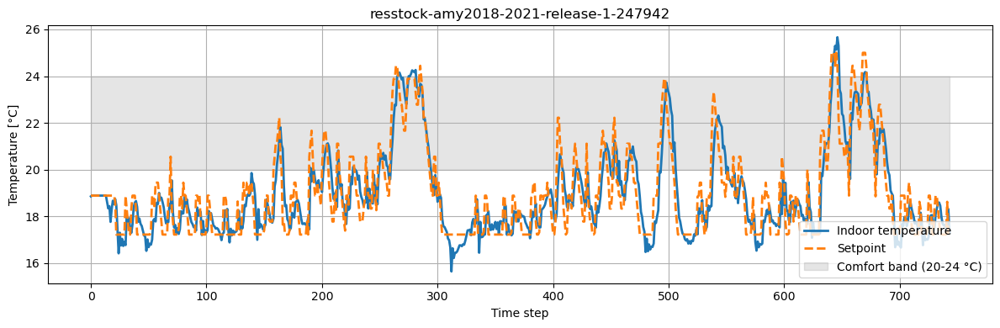

In [68]:
#here malaka
env_raw = make_env_raw(sim_start=JAN_START, sim_end=JAN_END)
flat_obs_names = env_raw.buildings[0].active_observations

def idx(name):
    return flat_obs_names.index(name)

IDX_T_IN  = idx("indoor_dry_bulb_temperature")
IDX_T_OUT = idx("outdoor_dry_bulb_temperature")
IDX_SOLAR = idx("direct_solar_irradiance")
IDX_T_SP  = idx("indoor_dry_bulb_temperature_heating_set_point")

IDX_TOUT_P1 = idx("outdoor_dry_bulb_temperature_predicted_1")
IDX_TOUT_P2 = idx("outdoor_dry_bulb_temperature_predicted_2")
IDX_TOUT_P3 = idx("outdoor_dry_bulb_temperature_predicted_3")

IDX_SOL_P1 = idx("direct_solar_irradiance_predicted_1")
IDX_SOL_P2 = idx("direct_solar_irradiance_predicted_2")
IDX_SOL_P3 = idx("direct_solar_irradiance_predicted_3")

policy_raw = DiffMPCPolicyRaw(
    mpc,
    x_mean,
    x_std,
    norm_d
)

obs, _ = env_raw.reset()
terminated = truncated = False
reward_sum = 0.0

while not (terminated or truncated):
    action = policy_raw.predict(obs)
    obs, reward, terminated, truncated, _ = env_raw.step(action)
    reward_sum += float(reward[0])


print("January reward (RAW) pretrained Diff-MPC:", reward_sum)
plot_comfort(env_raw)

In [69]:
print(env_raw.unwrapped.evaluate())

                                    cost_function     value  \
0                           all_time_peak_average  1.029295   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  0.987389   
5                              daily_peak_average  1.000831   
6                   discomfort_cold_delta_average  0.350097   
7                   discomfort_cold_delta_maximum  3.278305   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.029289   
10                   discomfort_hot_delta_average  0.354109   
11                   discomfort_hot_delta_maximum  3.249838   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.009763   
14                          discomfort_proportion  0.03

 # Mallon Online

In [70]:
SIGMA = 0.10
CLIP_EPS = 0.2
PPO_EPOCHS = 1
MINIBATCH = 64
LR_PPO = 5e-3
GAMMA = 0.995


In [71]:
# ---- Baseline feature builder ----

def build_baseline_features(obs, policy_state=None):
    o = np.asarray(obs, dtype=np.float32).reshape(-1)

    Tin = o[IDX_T_IN]
    Tsp = o[IDX_T_SP]
    Tout = o[IDX_T_OUT]
    Sol = o[IDX_SOLAR]
    hour = o[flat_obs_names.index("hour")]

    base_dim = len(flat_obs_names)
    if o.shape[0] >= base_dim + 5:
        occupied_now, feedback_now, feedback_ema, override_rate_ema, steps_since_override = o[base_dim:base_dim + 5]
    else:
        occupied_now = 0.0
        feedback_now = 0.0
        feedback_ema = 0.0
        override_rate_ema = 0.0
        steps_since_override = 24.0

    policy_state = {} if policy_state is None else dict(policy_state)

    history_bias_fn = globals().get('predictive_setpoint_bias_from_history')
    if 'history_bias' in policy_state:
        history_bias = float(policy_state['history_bias'])
    elif callable(history_bias_fn):
        history_bias = float(history_bias_fn(o))
    else:
        recent_signal = 0.75 * float(feedback_now) + 0.75 * float(feedback_ema)
        magnitude = 1.0 + 1.00 * float(override_rate_ema)
        decay = np.exp(-min(float(steps_since_override), 24.0) / 6.0)
        history_bias = float(np.clip(float(occupied_now) * recent_signal * magnitude * decay, -1.5, 1.5))

    w_est = float(policy_state.get('decision_w_est', policy_state.get('w_est', 0.0)))
    prev_u_raw = policy_state.get('prev_u', None)
    prev_u = 0.0 if prev_u_raw is None else float(prev_u_raw)
    has_prev_u = 0.0 if prev_u_raw is None else 1.0

    sin_h = np.sin(2*np.pi*hour/24.0)
    cos_h = np.cos(2*np.pi*hour/24.0)
    steps_since_override_norm = min(float(steps_since_override), 24.0) / 24.0

    return np.array([
        Tin,
        Tsp,
        Tout,
        Sol,
        sin_h,
        cos_h,
        float(occupied_now),
        float(feedback_now),
        float(feedback_ema),
        float(override_rate_ema),
        steps_since_override_norm,
        float(history_bias),
        float(w_est),
        float(prev_u),
        float(has_prev_u),
    ], dtype=np.float32)


In [72]:
# --------------------------------------------------
# OFFLINE BASELINE TRAINING (January PI data)
# --------------------------------------------------

GAMMA = 0.99

# build baseline feature matrix from January states
Z = []
for t in range(N):
    Z.append(build_baseline_features(states_np[t]))
Z = np.vstack(Z)

# compute discounted returns (full episode)
rewards_jan = data["rewards"][:, 0]

returns = np.zeros_like(rewards_jan)
running = 0.0
for t in reversed(range(N)):
    running = rewards_jan[t] + GAMMA * running
    returns[t] = running

# Fit ridge regression baseline
from sklearn.linear_model import Ridge

baseline_model = Ridge(alpha=1e-3)
baseline_model.fit(Z, returns)

print("Baseline V_pi0 trained.")

Baseline V_pi0 trained.


/home/kostas/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=2.19033e-11): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


In [73]:
# --------------------------------------------------
# ADVANTAGE COMPUTATION (Option A)
# --------------------------------------------------

def compute_advantages(trajectory, gamma=0.99):

    # trajectory: list of dicts
    T = len(trajectory)

    # extract rewards
    rewards = np.array([step["reward"] for step in trajectory])

    # compute discounted returns
    returns = np.zeros(T)
    running = 0.0
    for t in reversed(range(T)):
        running = rewards[t] + gamma * running
        returns[t] = running

    # compute baseline values
    values = np.zeros(T)
    for t, step in enumerate(trajectory):
        z = build_baseline_features(step["obs"], step.get("baseline_state", step.get("policy_state")))
        values[t] = baseline_model.predict(z.reshape(1,-1))[0]

    # advantage
    advantages = returns - values

    # normalize (important for PPO stability)
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    return advantages, returns

In [74]:
trajectory = []

obs, _ = env_raw.reset()
terminated = truncated = False

while not (terminated or truncated):

    action = policy_raw.predict(obs)

    next_obs, reward, terminated, truncated, _ = env_raw.step(action)

    trajectory.append({
        "obs": obs,
        "reward": float(reward[0])
    })

    obs = next_obs

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [75]:
from torch.distributions import Normal

In [76]:
advantages, returns = compute_advantages(trajectory)

print("Adv mean:", advantages.mean())
print("Adv std :", advantages.std())
print("Adv min/max:", advantages.min(), advantages.max())

Adv mean: 2.2951582312573896e-16
Adv std : 0.9999999998926757
Adv min/max: -1.5358559513907608 3.2176637772876884


In [77]:
env_feb_raw = make_env_raw(
    sim_start=FEB_START,
    sim_end=FEB_END,
    reward_function=OccupantFeedbackReward
)

print("February env with ComfortReward ready.")

February env with ComfortReward ready.


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

In [78]:
def _idx_or_none(name):
    try:
        return flat_obs_names.index(name)
    except ValueError:
        return None

IDX_HOUR = _idx_or_none("hour")

IDX_TOUT_P1 = _idx_or_none("outdoor_dry_bulb_temperature_predicted_1")
IDX_TOUT_P2 = _idx_or_none("outdoor_dry_bulb_temperature_predicted_2")
IDX_TOUT_P3 = _idx_or_none("outdoor_dry_bulb_temperature_predicted_3")

IDX_SOL_P1  = _idx_or_none("direct_solar_irradiance_predicted_1")
IDX_SOL_P2  = _idx_or_none("direct_solar_irradiance_predicted_2")
IDX_SOL_P3  = _idx_or_none("direct_solar_irradiance_predicted_3")

In [79]:
def d_forecast_from_obs(obs, T, device=device):
    o = np.asarray(obs, dtype=np.float32).reshape(-1)

    tout0 = o[IDX_T_OUT]
    sol0  = o[IDX_SOLAR]

    tout_preds = [tout0]
    sol_preds  = [sol0]

    # append predicted 1..3 if present
    for idx in [IDX_TOUT_P1, IDX_TOUT_P2, IDX_TOUT_P3]:
        if idx is not None: tout_preds.append(o[idx])
    for idx in [IDX_SOL_P1, IDX_SOL_P2, IDX_SOL_P3]:
        if idx is not None: sol_preds.append(o[idx])

    # build horizon by holding last available forecast
    tout_h, sol_h = [], []
    for k in range(T):
        tout_h.append(tout_preds[k] if k < len(tout_preds) else tout_preds[-1])
        sol_h.append(sol_preds[k]  if k < len(sol_preds)  else sol_preds[-1])

    d = np.stack([tout_h, sol_h], axis=1)  # (T,2) physical units
    return torch.tensor(d, dtype=torch.float32, device=device)

In [80]:
import math
import torch
from torch.distributions import Normal

class StochasticDiffMPCPolicy:

    def __init__(self, mpc, sigma=0.05):

        self.mpc = mpc
        self.sigma = float(sigma)

        # disturbance estimator
        self.w_est = 0.0
        self.gamma = 0.2

        self.prev_T = None
        self.prev_u = None
        self.prev_Tout = None
        self.prev_Isol = None


    def snapshot_state(self):

        return {
            "w_est": float(self.w_est),
            "prev_T": None if self.prev_T is None else float(self.prev_T),
            "prev_u": None if self.prev_u is None else float(self.prev_u),
            "prev_Tout": None if self.prev_Tout is None else float(self.prev_Tout),
            "prev_Isol": None if self.prev_Isol is None else float(self.prev_Isol),
        }


    def restore_state(self, state):

        self.w_est = float(state["w_est"])
        self.prev_T = state["prev_T"]
        self.prev_u = state["prev_u"]
        self.prev_Tout = state["prev_Tout"]
        self.prev_Isol = state["prev_Isol"]


    def _updated_offset_state(self, Tin, Tout, Isol, state):

        local_state = {
            "w_est": float(state["w_est"]),
            "prev_T": state["prev_T"],
            "prev_u": state["prev_u"],
            "prev_Tout": state["prev_Tout"],
            "prev_Isol": state["prev_Isol"],
        }

        if local_state["prev_T"] is None:
            return local_state

        cop = float(self.mpc.cop_a + self.mpc.cop_b * local_state["prev_Tout"])
        cop = np.clip(cop, self.mpc.cop_min, self.mpc.cop_max)

        C = float(self.mpc._pos(self.mpc.C_raw))
        Rm = float(self.mpc._pos(self.mpc.Rm_raw))
        Rout = float(self.mpc._pos(self.mpc.Rout_raw))
        Aeff = float(self.mpc._pos(self.mpc.Aeff_raw))
        Pnom = float(self.mpc._pos(self.mpc.Pnom_raw))

        Ac = -(1 / (Rm * C) + 1 / (Rout * C))
        A = np.exp(Ac)
        phi = (A - 1) / Ac if abs(Ac) > 1e-6 else 1.0

        Bu = phi * (cop * Pnom / C)
        Bd0 = phi * (1 / (Rm * C))
        Bd1 = phi * (1 / (Rout * C))
        Bd2 = phi * (Aeff / C)

        T_pred = (
            A * local_state["prev_T"]
            + Bu * local_state["prev_u"]
            + Bd0 * self.mpc.Tm.item()
            + Bd1 * local_state["prev_Tout"]
            + Bd2 * local_state["prev_Isol"]
            + local_state["w_est"]
        )

        err = Tin - T_pred
        local_state["w_est"] = float(local_state["w_est"] + self.gamma * err)
        return local_state


    def _mpc_mean_action(self, obs, policy_state=None, update_internal=True):

        o = np.asarray(obs, dtype=np.float32).reshape(-1)

        Tin = float(o[IDX_T_IN])
        Tsp = float(o[IDX_T_SP])
        Tout = float(o[IDX_T_OUT])
        Isol = float(o[IDX_SOLAR])

        state_in = self.snapshot_state() if policy_state is None else policy_state
        state_work = self._updated_offset_state(Tin, Tout, Isol, state_in)

        x_t = torch.tensor(
            [[(Tin - x_mean.item()) / x_std.item()]],
            dtype=torch.float32,
            device=device
        )

        d_phys = d_forecast_from_obs(o, self.mpc.T, device=device)
        d_seq = norm_d(d_phys).view(1, self.mpc.T, 2)

        sp_now = (Tsp - x_mean.item()) / x_std.item()

        sp_seq = torch.full(
            (1, self.mpc.T, 1),
            sp_now,
            dtype=torch.float32,
            device=device
        )

        w_seq = torch.full(
            (1, self.mpc.T, 1),
            float(state_work["w_est"]),
            dtype=torch.float32,
            device=device
        )

        u0, _, _ = self.mpc(x_t, d_seq, sp_seq, w_seq)
        mu = torch.clamp(u0.squeeze(), 0.0, 1.0)

        next_state = {
            "w_est": float(state_work["w_est"]),
            "prev_T": Tin,
            "prev_u": float(mu.item()),
            "prev_Tout": Tout,
            "prev_Isol": Isol,
        }

        if update_internal:
            self.restore_state(next_state)

        return mu, next_state


    def act(self, obs):

        policy_state = self.snapshot_state()
        mu, next_state = self._mpc_mean_action(obs, policy_state=policy_state, update_internal=False)
        self.restore_state(next_state)

        dist = Normal(mu, self.sigma)
        a_sample = dist.sample()
        logp = dist.log_prob(a_sample)

        a_env = torch.clamp(a_sample, 0.0, 1.0)
        action_env = [np.array([float(a_env.item())], dtype=np.float32)]

        return action_env, float(logp.item()), float(a_sample.item()), float(mu.item()), policy_state


    def log_prob(self, obs, a_sample_tensor, policy_state=None):

        mu, _ = self._mpc_mean_action(obs, policy_state=policy_state, update_internal=False)
        dist = Normal(mu, self.sigma)
        return dist.log_prob(a_sample_tensor), mu


    def reset(self):

        self.restore_state({
            "w_est": 0.0,
            "prev_T": None,
            "prev_u": None,
            "prev_Tout": None,
            "prev_Isol": None,
        })




In [81]:
class StochasticDiffMPCPolicy:

    def __init__(self, mpc, sigma=0.05):

        self.mpc = mpc
        self.sigma = float(sigma)

        # disturbance estimator
        self.w_est = 0.0
        self.gamma = 0.2

        self.prev_T = None
        self.prev_u = None
        self.prev_Tout = None
        self.prev_Isol = None


    def snapshot_state(self):

        return {
            "w_est": float(self.w_est),
            "prev_T": None if self.prev_T is None else float(self.prev_T),
            "prev_u": None if self.prev_u is None else float(self.prev_u),
            "prev_Tout": None if self.prev_Tout is None else float(self.prev_Tout),
            "prev_Isol": None if self.prev_Isol is None else float(self.prev_Isol),
        }


    def restore_state(self, state):

        self.w_est = float(state["w_est"])
        self.prev_T = state["prev_T"]
        self.prev_u = state["prev_u"]
        self.prev_Tout = state["prev_Tout"]
        self.prev_Isol = state["prev_Isol"]


    def _updated_offset_state(self, Tin, Tout, Isol, state):

        local_state = {
            "w_est": float(state["w_est"]),
            "prev_T": state["prev_T"],
            "prev_u": state["prev_u"],
            "prev_Tout": state["prev_Tout"],
            "prev_Isol": state["prev_Isol"],
        }

        if local_state["prev_T"] is None:
            return local_state

        cop = float(self.mpc.cop_a + self.mpc.cop_b * local_state["prev_Tout"])
        cop = np.clip(cop, self.mpc.cop_min, self.mpc.cop_max)

        C = float(self.mpc._pos(self.mpc.C_raw))
        Rm = float(self.mpc._pos(self.mpc.Rm_raw))
        Rout = float(self.mpc._pos(self.mpc.Rout_raw))
        Aeff = float(self.mpc._pos(self.mpc.Aeff_raw))
        Pnom = float(self.mpc._pos(self.mpc.Pnom_raw))

        Ac = -(1 / (Rm * C) + 1 / (Rout * C))
        A = np.exp(Ac)
        phi = (A - 1) / Ac if abs(Ac) > 1e-6 else 1.0

        Bu = phi * (cop * Pnom / C)
        Bd0 = phi * (1 / (Rm * C))
        Bd1 = phi * (1 / (Rout * C))
        Bd2 = phi * (Aeff / C)

        T_pred = (
            A * local_state["prev_T"]
            + Bu * local_state["prev_u"]
            + Bd0 * self.mpc.Tm.item()
            + Bd1 * local_state["prev_Tout"]
            + Bd2 * local_state["prev_Isol"]
            + local_state["w_est"]
        )

        err = Tin - T_pred
        local_state["w_est"] = float(local_state["w_est"] + self.gamma * err)
        return local_state


    def _mpc_mean_action(self, obs, policy_state=None, update_internal=True):

        o = np.asarray(obs, dtype=np.float32).reshape(-1)

        Tin = float(o[IDX_T_IN])
        Tsp = float(o[IDX_T_SP])
        Tout = float(o[IDX_T_OUT])
        Isol = float(o[IDX_SOLAR])

        state_in = self.snapshot_state() if policy_state is None else policy_state
        state_work = self._updated_offset_state(Tin, Tout, Isol, state_in)

        x_t = torch.tensor(
            [[(Tin - x_mean.item()) / x_std.item()]],
            dtype=torch.float32,
            device=device
        )

        d_phys = d_forecast_from_obs(o, self.mpc.T, device=device)
        d_seq = norm_d(d_phys).view(1, self.mpc.T, 2)

        sp_now = (Tsp - x_mean.item()) / x_std.item()

        sp_seq = torch.full(
            (1, self.mpc.T, 1),
            sp_now,
            dtype=torch.float32,
            device=device
        )

        w_seq = torch.full(
            (1, self.mpc.T, 1),
            float(state_work["w_est"]),
            dtype=torch.float32,
            device=device
        )

        u0, _, _ = self.mpc(x_t, d_seq, sp_seq, w_seq)
        mu = torch.clamp(u0.squeeze(), 0.0, 1.0)

        next_state = {
            "w_est": float(state_work["w_est"]),
            "prev_T": Tin,
            "prev_u": float(mu.item()),
            "prev_Tout": Tout,
            "prev_Isol": Isol,
        }

        if update_internal:
            self.restore_state(next_state)

        return mu, next_state


    def act(self, obs):

        policy_state = self.snapshot_state()
        mu, next_state = self._mpc_mean_action(obs, policy_state=policy_state, update_internal=False)
        self.restore_state(next_state)

        dist = Normal(mu, self.sigma)
        a_sample = dist.sample()
        logp = dist.log_prob(a_sample)

        a_env = torch.clamp(a_sample, 0.0, 1.0)
        action_env = [np.array([float(a_env.item())], dtype=np.float32)]

        return action_env, float(logp.item()), float(a_sample.item()), float(mu.item()), policy_state


    def log_prob(self, obs, a_sample_tensor, policy_state=None):

        mu, _ = self._mpc_mean_action(obs, policy_state=policy_state, update_internal=False)
        dist = Normal(mu, self.sigma)
        return dist.log_prob(a_sample_tensor), mu


    def reset(self):

        self.restore_state({
            "w_est": 0.0,
            "prev_T": None,
            "prev_u": None,
            "prev_Tout": None,
            "prev_Isol": None,
        })



In [82]:
def collect_rollout(env, policy, max_steps=None, seed=None):
    import random
    traj = []
    seed = int(GLOBAL_EXPERIMENT_SEED if seed is None else seed)
    np.random.seed(seed)
    random.seed(seed)
    try:
        obs, _ = env.reset(seed=seed)
    except TypeError:
        obs, _ = env.reset()
    if hasattr(policy, "reset"):
        policy.reset()
    terminated = truncated = False
    t = 0

    while not (terminated or truncated):
        action_env, logp, a_sample, mu, policy_state = policy.act(obs)
        baseline_state = {
            "decision_w_est": float(getattr(policy, "w_est", 0.0)),
            "prev_u": None if getattr(policy, "prev_u", None) is None else float(getattr(policy, "prev_u")),
            "history_bias": float(getattr(policy, "last_history_bias", 0.0)),
        }
        next_obs, reward, terminated, truncated, _ = env.step(action_env)

        traj.append({
            "obs": obs,
            "policy_state": policy_state,
            "baseline_state": baseline_state,
            "a_sample": a_sample,
            "logp_old": logp,
            "reward": float(reward[0]),
        })

        obs = next_obs
        t += 1
        if max_steps is not None and t >= max_steps:
            break

    return traj


In [83]:
def ppo_update_mpc(
    mpc,
    trajectory,
    advantages,
    clip_eps=0.2,
    ppo_epochs=10,
    minibatch_size=16,
    lr=3e-4,
    max_grad_norm=1.0,
):
    """
    PPO update for the cost-only GNU-RL version.
    Only q_track_raw, r_u_raw, and sp_bias_raw are optimized online.
    """
    mpc.train()
    freeze_dynamics_parameters(mpc)
    opt = torch.optim.Adam([mpc.q_track_raw, mpc.r_u_raw, mpc.sp_bias_raw], lr=lr)

    N = len(trajectory)
    idxs = np.arange(N)

    logp_old = torch.tensor([step["logp_old"] for step in trajectory], dtype=torch.float32, device=device)
    a_sample = torch.tensor([step["a_sample"] for step in trajectory], dtype=torch.float32, device=device)
    adv = torch.tensor(advantages, dtype=torch.float32, device=device)

    policy = StochasticDiffMPCPolicy(mpc, sigma=SIGMA)

    for ep in range(ppo_epochs):
        np.random.shuffle(idxs)
        ep_losses = []

        for start in range(0, N, minibatch_size):
            mb = idxs[start:start + minibatch_size]
            loss = 0.0

            for j in mb:
                obs_j = trajectory[j]["obs"]
                policy_state_j = trajectory[j]["policy_state"]
                a_j = a_sample[j]
                logp_old_j = logp_old[j]
                adv_j = adv[j]

                logp_new_j, _mu = policy.log_prob(obs_j, a_j, policy_state=policy_state_j)
                ratio = torch.exp(logp_new_j - logp_old_j)

                unclipped = ratio * adv_j
                clipped = torch.clamp(ratio, 1.0 - clip_eps, 1.0 + clip_eps) * adv_j
                loss_j = -torch.min(unclipped, clipped)
                loss = loss + loss_j

            loss = loss / max(1, len(mb))

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_([mpc.q_track_raw, mpc.r_u_raw, mpc.sp_bias_raw], max_grad_norm)
            opt.step()
            ep_losses.append(float(loss.item()))

        print(
            f"PPO epoch {ep+1:02d}/{ppo_epochs} | loss {np.mean(ep_losses):.6f} | "
            f"q_track={float(mpc.q_track().item()):.4f} "
            f"r_u={float(mpc.r_u().item()):.4f} "
            f"sp_bias={float(mpc.sp_bias().item()):.4f}"
        )

    mpc.eval()


In [84]:
# env_feb_raw should be your February environment with ComfortReward enabled
policy_stoch = StochasticDiffMPCPolicy(mpc, sigma=SIGMA)

traj_feb = collect_rollout(env_feb_raw, policy_stoch)
print("Collected steps:", len(traj_feb))

advantages, returns = compute_advantages(traj_feb)  # your Option A baseline advantage
print("Adv mean:", advantages.mean())
print("Adv std :", advantages.std())
print("Adv min/max:", advantages.min(), advantages.max())

ppo_update_mpc(
    mpc,
    traj_feb,
    advantages,
    clip_eps=CLIP_EPS,
    ppo_epochs=PPO_EPOCHS,
    minibatch_size=MINIBATCH,
    lr=LR_PPO,
    max_grad_norm=1.0,
)

# evaluate updated policy deterministically (sigma=0, or just use DiffMPCPolicyRaw)
policy_eval = DiffMPCPolicyRaw(
    mpc,
    x_mean,
    x_std,
    norm_d
)


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

February reward after PPO: -28.836795367256894


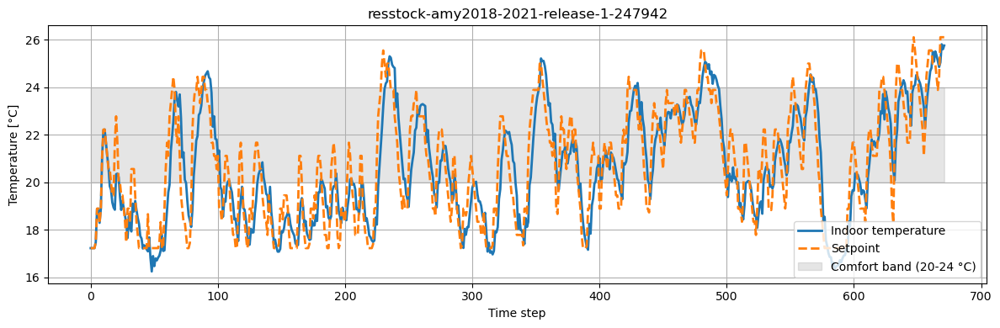

In [85]:
policy_eval = DiffMPCPolicyRaw(
    mpc,
    x_mean,
    x_std,
    norm_d
)

obs, _ = env_feb_raw.reset()
terminated = truncated = False
reward_sum = 0.0

while not (terminated or truncated):
    action = policy_eval.predict(obs)
    obs, reward, terminated, truncated, _ = env_feb_raw.step(action)
    reward_sum += float(reward[0])

print("February reward after PPO:", reward_sum)
plot_comfort(env_feb_raw)

In [86]:
print(env_feb_raw.unwrapped.evaluate())

                                    cost_function     value  \
0                           all_time_peak_average  0.960844   
1         annual_normalized_unserved_energy_total  0.000000   
2                          carbon_emissions_total       NaN   
3                                      cost_total       NaN   
4             daily_one_minus_load_factor_average  0.994419   
5                              daily_peak_average  1.008882   
6                   discomfort_cold_delta_average  0.524007   
7                   discomfort_cold_delta_maximum  3.389194   
8                   discomfort_cold_delta_minimum  0.000000   
9                      discomfort_cold_proportion  0.077863   
10                   discomfort_hot_delta_average  0.452462   
11                   discomfort_hot_delta_maximum  3.267817   
12                   discomfort_hot_delta_minimum  0.000000   
13                      discomfort_hot_proportion  0.032061   
14                          discomfort_proportion  0.10

# Occupant booiiiiiiiiiiiii

In [87]:
SIGMA = 0.10
CLIP_EPS = 0.2
PPO_EPOCHS = 1
MINIBATCH = 64
LR_PPO = 5e-3
GAMMA = 0.995


In [88]:
class Occupant1:

    def __init__(self):
        self.T_pref = 22.0
        self.b = 1.2
        self.max_prob = 0.4

        self.override_timer = 0
        self.override_setpoint = None
        self.last_override_started = False
        self.duration = 3  # 3 hours

    def prob_increase(self, Tin):
        delta = max(0, self.T_pref - Tin)
        p = 0.002 * np.exp(self.b * delta)
        return min(p, self.max_prob)

    def prob_decrease(self, Tin):
        delta = max(0, Tin - self.T_pref)
        p = 0.002 * np.exp(self.b * delta)
        return min(p, self.max_prob)

    def override_delta(self, p_override):
        if p_override < 0.2:
            return 0.5
        if p_override < 0.4:
            return 1.0
        return 2.0

    def clear_override(self):
        self.override_timer = 0
        self.override_setpoint = None
        self.last_override_started = False

    def step(self, Tin, scheduled_Tsp, occupied=True):

        self.last_override_started = False

        if not occupied:
            self.clear_override()
            return scheduled_Tsp

        # active override
        if self.override_timer > 0:
            self.override_timer -= 1
            return self.override_setpoint

        p_inc = self.prob_increase(Tin)
        p_dec = self.prob_decrease(Tin)

        r = np.random.rand()

        if r < p_inc:
            new_sp = scheduled_Tsp + self.override_delta(p_inc)
        elif r < p_inc + p_dec:
            new_sp = scheduled_Tsp - self.override_delta(p_dec)
        else:
            self.override_setpoint = None
            return scheduled_Tsp

        self.override_setpoint = new_sp
        self.override_timer = max(self.duration - 1, 0)
        self.last_override_started = True

        return new_sp

In [89]:
class OccupantWrapper(gym.Wrapper):

    HISTORY_EMA_ALPHA = 0.85
    HISTORY_TAU_MAX = 24.0

    def __init__(self, env, occupant):
        super().__init__(env)
        self.occupant = occupant
        self.history_feature_names = [
            "occupied_now",
            "feedback_now",
            "feedback_ema",
            "override_rate_ema",
            "steps_since_override",
        ]
        if hasattr(env, 'observation_names'):
            try:
                if isinstance(env.observation_names, list) and len(env.observation_names) == 1 and isinstance(env.observation_names[0], list):
                    self.observation_names = [list(env.observation_names[0]) + self.history_feature_names]
                else:
                    self.observation_names = env.observation_names
            except Exception:
                self.observation_names = getattr(env, 'observation_names', None)

    def _reset_history(self):
        self.occupied_now = 0.0
        self.feedback_now = 0.0
        self.feedback_ema = 0.0
        self.override_rate_ema = 0.0
        self.steps_since_override = self.HISTORY_TAU_MAX

    def _update_history_from_env(self, b):
        current_ix = b.time_step
        self.feedback_now = float(b.energy_simulation.occupant_feedback_signal[current_ix])
        self.occupied_now = 1.0 if float(b.energy_simulation.occupant_count[current_ix]) > 0.0 else 0.0
        override_event = 1.0 if abs(self.feedback_now) > 0.0 else 0.0

        alpha = self.HISTORY_EMA_ALPHA
        self.feedback_ema = alpha * self.feedback_ema + (1.0 - alpha) * self.feedback_now
        self.override_rate_ema = alpha * self.override_rate_ema + (1.0 - alpha) * override_event

        if override_event > 0.0:
            self.steps_since_override = 0.0
        else:
            self.steps_since_override = min(self.HISTORY_TAU_MAX, self.steps_since_override + 1.0)

    def _augment_obs(self, obs):
        hist = np.array([
            self.occupied_now,
            self.feedback_now,
            self.feedback_ema,
            self.override_rate_ema,
            self.steps_since_override,
        ], dtype=np.float32)

        if isinstance(obs, (list, tuple)):
            if len(obs) == 1:
                base = np.asarray(obs[0], dtype=np.float32).reshape(-1)
                return [np.concatenate([base, hist], axis=0)]
            augmented = []
            for i, ob in enumerate(obs):
                base = np.asarray(ob, dtype=np.float32).reshape(-1)
                augmented.append(np.concatenate([base, hist], axis=0) if i == 0 else base)
            return augmented

        base = np.asarray(obs, dtype=np.float32)
        if base.ndim == 2 and base.shape[0] == 1:
            return [np.concatenate([base[0].reshape(-1), hist], axis=0)]
        return np.concatenate([base.reshape(-1), hist], axis=0)

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self.occupant.override_timer = 0
        self.occupant.override_setpoint = None
        self.occupant.last_override_started = False
        self.override_count = 0
        b = self.env.unwrapped.buildings[0]
        n_steps = len(b.energy_simulation._indoor_dry_bulb_temperature_heating_set_point)
        b.energy_simulation.occupant_feedback_signal = np.zeros(n_steps, dtype=np.float32)
        self.effective_setpoints = [float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[b.time_step])]
        self.baseline_setpoints = [float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[b.time_step])]
        self._reset_history()
        self._update_history_from_env(b)
        return self._augment_obs(obs), info

    def step(self, action):
        b = self.env.unwrapped.buildings[0]
        current_ix = b.time_step

        Tin = float(b.energy_simulation.indoor_dry_bulb_temperature[current_ix])
        next_ix = min(current_ix + 1, len(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point) - 1)
        occupied_next = float(b.energy_simulation.occupant_count[next_ix]) > 0.0
        scheduled_next_Tsp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[next_ix]
        )

        if occupied_next:
            new_Tsp = self.occupant.step(Tin, scheduled_next_Tsp, occupied=True)
        else:
            new_Tsp = self.occupant.step(Tin, scheduled_next_Tsp, occupied=False)

        feedback_signal = 0.0
        if self.occupant.last_override_started:
            self.override_count += 1
            if new_Tsp > scheduled_next_Tsp:
                feedback_signal = 1.0
            elif new_Tsp < scheduled_next_Tsp:
                feedback_signal = -1.0
        b.energy_simulation.occupant_feedback_signal[next_ix] = feedback_signal

        b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[next_ix] = new_Tsp

        obs, reward, terminated, truncated, info = self.env.step(action)

        current_effective_sp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[b.time_step]
        )
        current_baseline_sp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[b.time_step]
        )
        self.effective_setpoints.append(current_effective_sp)
        self.baseline_setpoints.append(current_baseline_sp)
        self._update_history_from_env(b)

        return self._augment_obs(obs), reward, terminated, truncated, info



/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

✅ February env with Occupant 1 ready

--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------




/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

🔥 February reward WITH OCCUPANT: -65.26113761734076


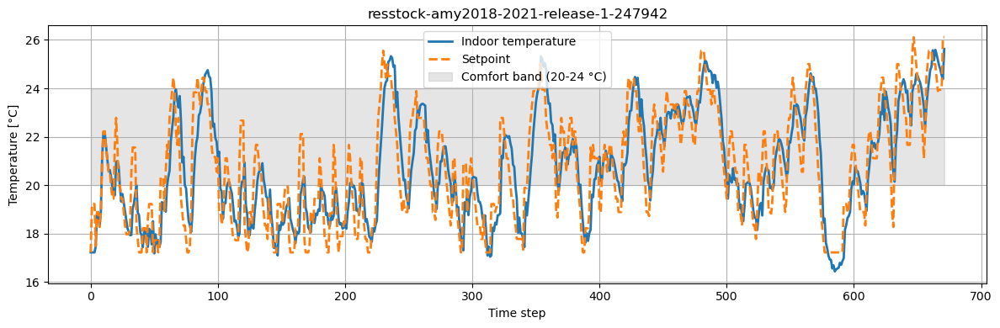

In [90]:
# ===== NEW EXPERIMENT: FEB WITH OCCUPANT =====

# build raw env
env_feb_occ = make_env_raw(
    sim_start=FEB_START,
    sim_end=FEB_END,
    reward_function=OccupantFeedbackReward
)

# attach occupant
occupant1 = Occupant1()
env_feb_occ = OccupantWrapper(env_feb_occ, occupant1)

print("✅ February env with Occupant 1 ready")

# stochastic policy
policy_stoch = StochasticDiffMPCPolicy(mpc, sigma=SIGMA)

# collect rollout
traj_feb_occ = collect_rollout(env_feb_occ, policy_stoch)
print("Collected steps (occupant):", len(traj_feb_occ))

# compute advantages
advantages, returns = compute_advantages(traj_feb_occ)

print("Adv mean:", advantages.mean())
print("Adv std :", advantages.std())

# PPO update
ppo_update_mpc(
    mpc,
    traj_feb_occ,
    advantages,
    clip_eps=CLIP_EPS,
    ppo_epochs=PPO_EPOCHS,
    minibatch_size=MINIBATCH,
    lr=LR_PPO,
)

# evaluate deterministic policy
policy_eval = DiffMPCPolicyRaw(mpc, x_mean, x_std, norm_d)

obs, _ = env_feb_occ.reset()
terminated = truncated = False
reward_sum = 0.0

while not (terminated or truncated):
    action = policy_eval.predict(obs)
    obs, reward, terminated, truncated, _ = env_feb_occ.step(action)
    reward_sum += float(reward[0])

print("🔥 February reward WITH OCCUPANT:", reward_sum)

plot_comfort(env_feb_occ)

In [91]:
# =========================
# OCCUPANT + WRAPPER
# =========================

import numpy as np
import gymnasium as gym

class Occupant:

    def __init__(self, T_pref, b, max_prob=0.4, duration=3):
        self.T_pref = T_pref
        self.b = b
        self.max_prob = max_prob
        self.duration = duration

        self.override_timer = 0
        self.override_setpoint = None
        self.last_override_started = False

    def prob_increase(self, Tin):
        d = max(0, self.T_pref - Tin)
        return min(0.002 * np.exp(self.b * d), self.max_prob)

    def prob_decrease(self, Tin):
        d = max(0, Tin - self.T_pref)
        return min(0.002 * np.exp(self.b * d), self.max_prob)

    def override_delta(self, p_override):
        if p_override < 0.2:
            return 0.5
        if p_override < 0.4:
            return 1.0
        return 2.0

    def clear_override(self):
        self.override_timer = 0
        self.override_setpoint = None
        self.last_override_started = False

    def step(self, Tin, scheduled_Tsp, occupied=True):

        self.last_override_started = False

        if not occupied:
            self.clear_override()
            return scheduled_Tsp

        if self.override_timer > 0:
            self.override_timer -= 1
            return self.override_setpoint

        p_inc = self.prob_increase(Tin)
        p_dec = self.prob_decrease(Tin)

        r = np.random.rand()

        if r < p_inc:
            new_sp = scheduled_Tsp + self.override_delta(p_inc)
        elif r < p_inc + p_dec:
            new_sp = scheduled_Tsp - self.override_delta(p_dec)
        else:
            self.override_setpoint = None
            return scheduled_Tsp

        self.override_setpoint = new_sp
        self.override_timer = max(self.duration - 1, 0)
        self.last_override_started = True

        return new_sp


class OccupantWrapper(gym.Wrapper):

    HISTORY_EMA_ALPHA = 0.85
    HISTORY_TAU_MAX = 24.0

    def __init__(self, env, occupant):
        super().__init__(env)
        self.occupant = occupant
        self.history_feature_names = [
            "occupied_now",
            "feedback_now",
            "feedback_ema",
            "override_rate_ema",
            "steps_since_override",
        ]
        if hasattr(env, 'observation_names'):
            try:
                if isinstance(env.observation_names, list) and len(env.observation_names) == 1 and isinstance(env.observation_names[0], list):
                    self.observation_names = [list(env.observation_names[0]) + self.history_feature_names]
                else:
                    self.observation_names = env.observation_names
            except Exception:
                self.observation_names = getattr(env, 'observation_names', None)

    def _reset_history(self):
        self.occupied_now = 0.0
        self.feedback_now = 0.0
        self.feedback_ema = 0.0
        self.override_rate_ema = 0.0
        self.steps_since_override = self.HISTORY_TAU_MAX

    def _update_history_from_env(self, b):
        current_ix = b.time_step
        self.feedback_now = float(b.energy_simulation.occupant_feedback_signal[current_ix])
        self.occupied_now = 1.0 if float(b.energy_simulation.occupant_count[current_ix]) > 0.0 else 0.0
        override_event = 1.0 if abs(self.feedback_now) > 0.0 else 0.0

        alpha = self.HISTORY_EMA_ALPHA
        self.feedback_ema = alpha * self.feedback_ema + (1.0 - alpha) * self.feedback_now
        self.override_rate_ema = alpha * self.override_rate_ema + (1.0 - alpha) * override_event

        if override_event > 0.0:
            self.steps_since_override = 0.0
        else:
            self.steps_since_override = min(self.HISTORY_TAU_MAX, self.steps_since_override + 1.0)

    def _augment_obs(self, obs):
        hist = np.array([
            self.occupied_now,
            self.feedback_now,
            self.feedback_ema,
            self.override_rate_ema,
            self.steps_since_override,
        ], dtype=np.float32)

        if isinstance(obs, (list, tuple)):
            if len(obs) == 1:
                base = np.asarray(obs[0], dtype=np.float32).reshape(-1)
                return [np.concatenate([base, hist], axis=0)]
            augmented = []
            for i, ob in enumerate(obs):
                base = np.asarray(ob, dtype=np.float32).reshape(-1)
                augmented.append(np.concatenate([base, hist], axis=0) if i == 0 else base)
            return augmented

        base = np.asarray(obs, dtype=np.float32)
        if base.ndim == 2 and base.shape[0] == 1:
            return [np.concatenate([base[0].reshape(-1), hist], axis=0)]
        return np.concatenate([base.reshape(-1), hist], axis=0)

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self.occupant.override_timer = 0
        self.occupant.override_setpoint = None
        self.occupant.last_override_started = False
        self.override_count = 0
        b = self.env.unwrapped.buildings[0]
        n_steps = len(b.energy_simulation._indoor_dry_bulb_temperature_heating_set_point)
        b.energy_simulation.occupant_feedback_signal = np.zeros(n_steps, dtype=np.float32)
        self.effective_setpoints = [float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[b.time_step])]
        self.baseline_setpoints = [float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[b.time_step])]
        self._reset_history()
        self._update_history_from_env(b)
        return self._augment_obs(obs), info

    def step(self, action):
        b = self.env.unwrapped.buildings[0]
        current_ix = b.time_step

        Tin = float(b.energy_simulation.indoor_dry_bulb_temperature[current_ix])
        next_ix = min(current_ix + 1, len(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point) - 1)
        occupied_next = float(b.energy_simulation.occupant_count[next_ix]) > 0.0
        scheduled_next_Tsp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[next_ix]
        )

        if occupied_next:
            new_Tsp = self.occupant.step(Tin, scheduled_next_Tsp, occupied=True)
        else:
            new_Tsp = self.occupant.step(Tin, scheduled_next_Tsp, occupied=False)

        feedback_signal = 0.0
        if self.occupant.last_override_started:
            self.override_count += 1
            if new_Tsp > scheduled_next_Tsp:
                feedback_signal = 1.0
            elif new_Tsp < scheduled_next_Tsp:
                feedback_signal = -1.0
        b.energy_simulation.occupant_feedback_signal[next_ix] = feedback_signal

        b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[next_ix] = new_Tsp

        obs, reward, terminated, truncated, info = self.env.step(action)

        current_effective_sp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[b.time_step]
        )
        current_baseline_sp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[b.time_step]
        )
        self.effective_setpoints.append(current_effective_sp)
        self.baseline_setpoints.append(current_baseline_sp)
        self._update_history_from_env(b)

        return self._augment_obs(obs), reward, terminated, truncated, info




In [92]:
def plot_comfort(
    env: CityLearnEnv,
    building_idx: int = 0,
    T_low: float = 20.0,
    T_high: float = 24.0,
    title: str = None
):
    b = env.unwrapped.buildings[building_idx]

    # Indoor temperature
    T_in = np.asarray(b.indoor_dry_bulb_temperature, dtype=np.float32).reshape(-1)

    # Setpoint traces
    if hasattr(env, "effective_setpoints") and len(env.effective_setpoints) > 0:
        T_sp = np.asarray(env.effective_setpoints, dtype=np.float32).reshape(-1)
    else:
        T_sp = np.asarray(b.indoor_dry_bulb_temperature_heating_set_point, dtype=np.float32).reshape(-1)

    if hasattr(env, "baseline_setpoints") and len(env.baseline_setpoints) > 0:
        T_sp_base = np.asarray(env.baseline_setpoints, dtype=np.float32).reshape(-1)
    else:
        T_sp_base = np.asarray(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control,
            dtype=np.float32,
        ).reshape(-1)

    n = min(len(T_in), len(T_sp), len(T_sp_base))
    if n == 0:
        raise ValueError('plot_comfort received an empty temperature/setpoint trace.')

    T_in = T_in[:n]
    T_sp = T_sp[:n]
    T_sp_base = T_sp_base[:n]
    timesteps = np.arange(n)

    plt.figure(figsize=(12, 4))

    plt.plot(timesteps, T_in, label='Indoor temperature', linewidth=2)
    plt.plot(timesteps, T_sp_base, ':', label='Baseline schedule', linewidth=1.8, color='gray')
    plt.plot(timesteps, T_sp, '--', label='Effective setpoint', linewidth=2)

    plt.fill_between(
        timesteps,
        T_low,
        T_high,
        color='gray',
        alpha=0.2,
        label=f'Comfort band ({T_low:.0f}-{T_high:.0f} °C)'
    )

    plt.xlabel('Time step')
    plt.ylabel('Temperature [°C]')
    plt.title(title or b.name)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [93]:
# =========================
# OCCUPANTS
# =========================

occupants = {
    "occ1_tolerant": Occupant(T_pref=22, b=1.2, max_prob=0.4),
    "occ2_sensitive": Occupant(T_pref=23, b=3.5, max_prob=0.4),
    "occ3_cold": Occupant(T_pref=20, b=2.5, max_prob=0.4),
    "occ4_hot": Occupant(T_pref=24, b=2.5, max_prob=0.4),
}

In [94]:
# =========================
# OCCUPANT-AWARE REWARD
# =========================

class OccupantComfortReward(ComfortReward):

    def calculate(self, observations):

        reward_list = []

        for o in observations:

            # 🔥 If override exists, replace setpoint
            if 'override_setpoint' in o:
                o['indoor_dry_bulb_temperature_heating_set_point'] = o['override_setpoint']

            # run original logic
            r = super().calculate([o])[0]
            reward_list.append(r)

        if self.central_agent:
            return [sum(reward_list)]
        else:
            return reward_list

In [95]:
from collections import deque
from citylearn.reward_function import RewardFunction

class OccupantFeedbackReward(RewardFunction):

    def __init__(self, env_metadata, beta=0.75, epsilon=0.05, feedback_horizon=4):
        super().__init__(env_metadata)
        self.beta = beta
        self.epsilon = epsilon
        self.feedback_horizon = feedback_horizon
        self.feedback_buffers = []
        self.energy_scales = []

        if self.env_metadata is not None and self.env_metadata.get('buildings') is not None:
            self.reset()

    def reset(self):
        n_buildings = 0 if self.env_metadata is None else len(self.env_metadata['buildings'])
        self.feedback_buffers = [
            deque([0.0] * self.feedback_horizon, maxlen=self.feedback_horizon)
            for _ in range(n_buildings)
        ]
        self.energy_scales = []

        for i in range(n_buildings):
            building_metadata = self.env_metadata['buildings'][i]
            nominal_power = float(building_metadata.get('heating_device', {}).get('nominal_power', 0.0) or 0.0)
            self.energy_scales.append(max(nominal_power, 1.0))

    def _discomfort_from_buffer(self, feedback_buffer):
        discomfort = 0.0

        for lag, feedback in enumerate(reversed(feedback_buffer)):
            weight = np.e - np.exp((lag + 1) / self.feedback_horizon)
            discomfort += weight * abs(feedback)

        return discomfort

    def calculate(self, observations):
        if len(self.feedback_buffers) != len(observations):
            self.reset()

        reward_list = []

        for i, o in enumerate(observations):
            feedback = float(o.get('occupant_feedback_signal', 0.0))
            occupied = float(o.get('occupant_count', 0.0)) > 0.0

            if occupied and abs(feedback) > 0.0:
                discomfort_cost = self._discomfort_from_buffer(self.feedback_buffers[i])
            elif occupied:
                discomfort_cost = -self.epsilon
            else:
                discomfort_cost = 0.0

            self.feedback_buffers[i].append(feedback)

            hvac_electricity = max(
                float(o.get('heating_electricity_consumption', o.get('net_electricity_consumption', 0.0))),
                0.0,
            )
            energy_scale = self.energy_scales[i] if i < len(self.energy_scales) else 1.0
            energy_cost = hvac_electricity / max(energy_scale, 1.0)

            total_cost = self.beta * discomfort_cost + (1.0 - self.beta) * energy_cost
            reward_list.append(-total_cost)

        if self.central_agent:
            return [sum(reward_list)]
        else:
            return reward_list


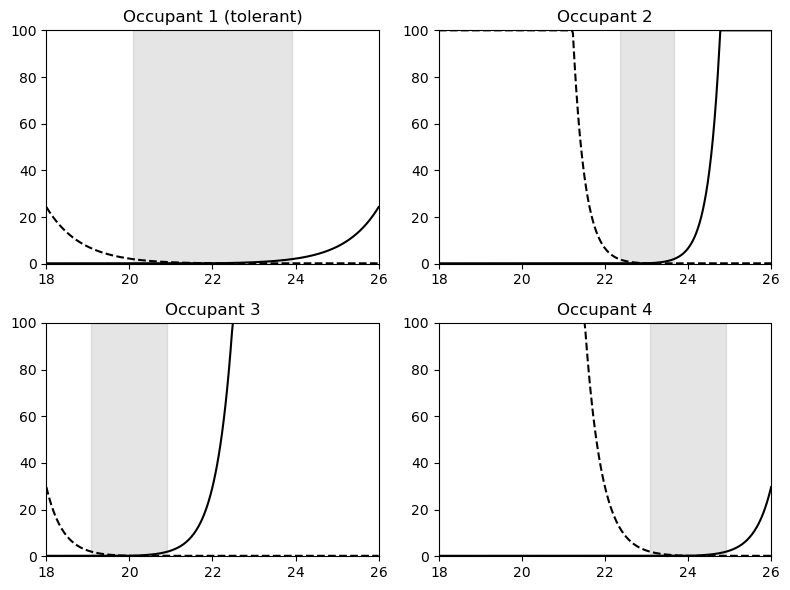

In [96]:
# here malaka
import numpy as np
import matplotlib.pyplot as plt

T = np.linspace(18, 26, 400)

occupant_profiles = [
    {"name": "Occupant 1 (tolerant)", "comfort": 22, "b": 1.2},
    {"name": "Occupant 2", "comfort": 23, "b": 3.5},
    {"name": "Occupant 3", "comfort": 20, "b": 2.5},
    {"name": "Occupant 4", "comfort": 24, "b": 2.5},
]

def prob_increase(T, T_comf, b):
    delta = np.maximum(0, T_comf - T)
    p = 0.002 * np.exp(b * delta)
    return np.clip(p, 0, 1)

def prob_decrease(T, T_comf, b):
    delta = np.maximum(0, T - T_comf)
    p = 0.002 * np.exp(b * delta)
    return np.clip(p, 0, 1)

fig, axs = plt.subplots(2,2, figsize=(8,6))

for ax, occ in zip(axs.flatten(), occupant_profiles):

    p_inc = prob_increase(T, occ["comfort"], occ["b"])
    p_dec = prob_decrease(T, occ["comfort"], occ["b"])

    ax.plot(T, p_dec*100, label="Decrease", color="black")
    ax.plot(T, p_inc*100, "--", label="Increase", color="black")

    # comfort zone condition
    comfort = (p_inc < 0.02) & (p_dec < 0.02)

    ax.fill_between(T, 0, 100, where=comfort, color="grey", alpha=0.2)

    ax.set_title(occ["name"])
    ax.set_xlim(18,26)
    ax.set_ylim(0,100)

plt.tight_layout()
plt.show()

In [97]:
SIGMA = 0.10
CLIP_EPS = 0.2
PPO_EPOCHS = 1
MINIBATCH = 64
LR_PPO = 5e-3
GAMMA = 0.995


Online adaptation window: 744-1415 | days=28

🔥 baseline
Offline init: q_track=10.0001 r_u=1.0001 sp_bias=0.0000


/tmp/ipykernel_31653/3267341890.py:69: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  mpc_case.load_state_dict(torch.load("ibex_offline_pretrained.pt", map_location=device), 


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

...


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------

Reward: -28.52797771826185
Overrides: 0


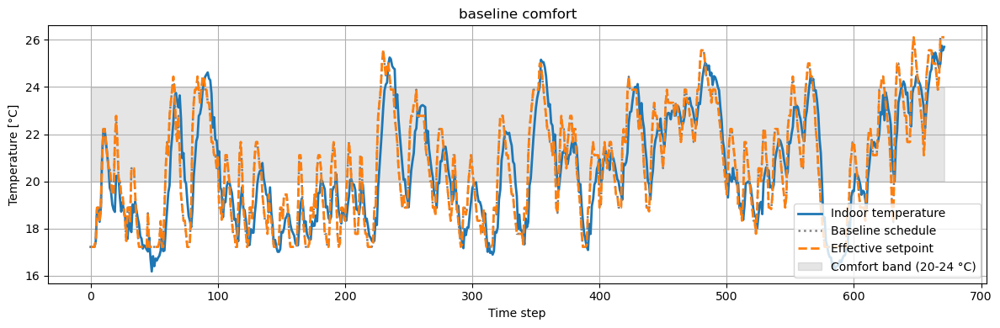


🔥 occ1_tolerant
Offline init: q_track=10.0001 r_u=1.0001 sp_bias=0.0000


/tmp/ipykernel_31653/3267341890.py:69: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  mpc_case.load_state_dict(torch.load("ibex_offline_pretrained.pt", map_location=device), 


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

...


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Reward: -32.856465645892094
Overrides: 31


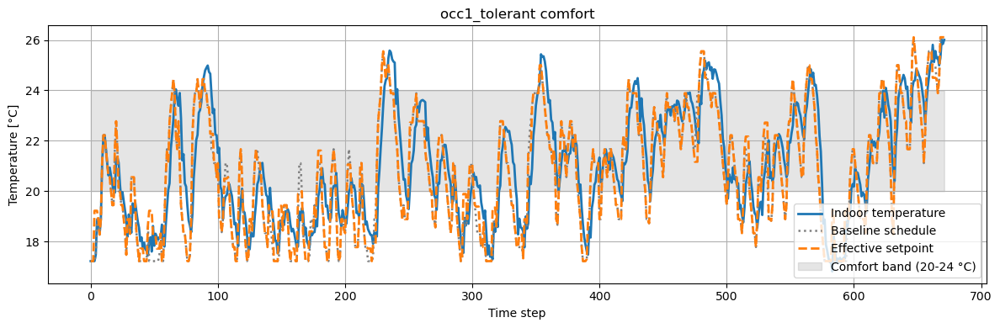


🔥 occ2_sensitive
Offline init: q_track=10.0001 r_u=1.0001 sp_bias=0.0000


/tmp/ipykernel_31653/3267341890.py:69: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  mpc_case.load_state_dict(torch.load("ibex_offline_pretrained.pt", map_location=device), 


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

...


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Reward: -52.12531520080101
Overrides: 108


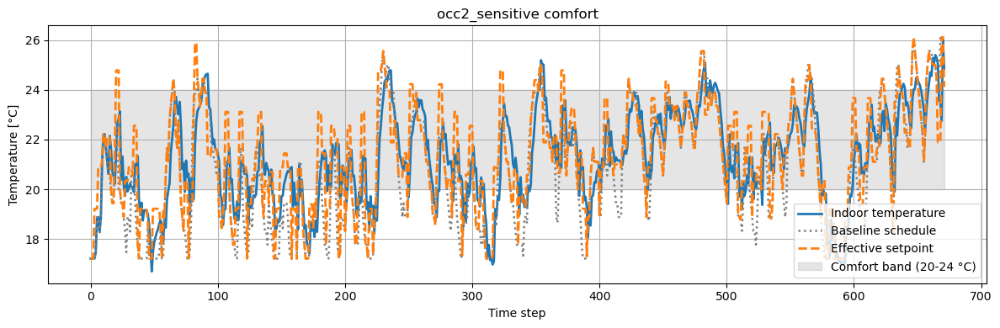


🔥 occ3_cold
Offline init: q_track=10.0001 r_u=1.0001 sp_bias=0.0000


/tmp/ipykernel_31653/3267341890.py:69: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  mpc_case.load_state_dict(torch.load("ibex_offline_pretrained.pt", map_location=device), 


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

...


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------

Reward: -38.8677885553929
Overrides: 72


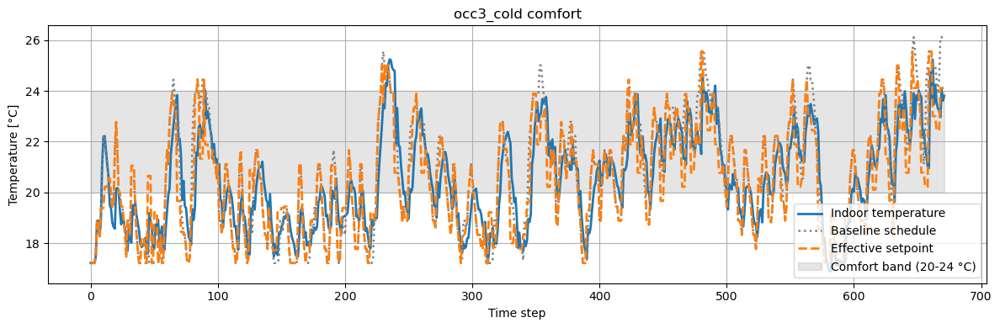


🔥 occ4_hot
Offline init: q_track=10.0001 r_u=1.0001 sp_bias=0.0000


/tmp/ipykernel_31653/3267341890.py:69: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  mpc_case.load_state_dict(torch.load("ibex_offline_pretrained.pt", map_location=device), 


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

...


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Reward: -55.9971598468255
Overrides: 114


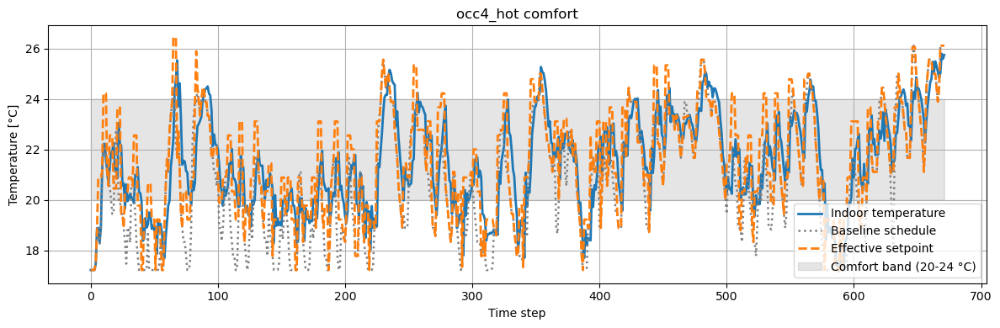

,occupant,override_count,reward,electricity_consumption_total,discomfort_proportion,discomfort_cold_proportion,discomfort_hot_proportion,daily_peak_average
0,baseline,0,-28.527978,0.998420,0.109924,0.082443,0.027481,1.007583
1,occ1_tolerant,31,-32.856466,1.020656,0.105344,0.044275,0.061069,1.011373
2,occ2_sensitive,108,-52.125315,1.028197,0.248855,0.091603,0.158779,1.021684
3,occ3_cold,72,-38.867789,0.988876,0.080916,0.065649,0.015267,1.000430
4,occ4_hot,114,-55.997160,1.037875,0.285496,0.088550,0.196947,1.021940


In [53]:
# =========================
# FULL FEBRUARY GNU-RL EXPERIMENT
# =========================

import numpy as np
import pandas as pd
import random
from copy import deepcopy
from IPython.display import display

WEEK_HOURS = 7 * 24
ONLINE_SIM_END = FEB_END
print(f"Online adaptation window: {FEB_START}-{ONLINE_SIM_END} | days={(ONLINE_SIM_END - FEB_START + 1)/24:.0f}")

results = {}
summary_rows = []

def diffmpc_param_snapshot(mpc_case):
    with torch.no_grad():
        return {
            'q_track': float(mpc_case.q_track().item()),
            'r_u': float(mpc_case.r_u().item()),
            'sp_bias': float(mpc_case.sp_bias().item()),
        }

def print_diffmpc_params(tag, mpc_case):
    p = diffmpc_param_snapshot(mpc_case)
    print(
        f"{tag}: "
        f"q_track={p['q_track']:.4f} "
        f"r_u={p['r_u']:.4f} "
        f"sp_bias={p['sp_bias']:.4f}"
    )

def summarize_district_kpis(label, district_kpis, reward_sum, override_count):
    def get_kpi(cost_name):
        rows = district_kpis[district_kpis['cost_function'] == cost_name]['value']
        return float(rows.iloc[0]) if len(rows) > 0 else np.nan

    return {
        'occupant': label,
        'override_count': int(override_count),
        'reward': float(reward_sum),
        'electricity_consumption_total': get_kpi('electricity_consumption_total'),
        'discomfort_proportion': get_kpi('discomfort_proportion'),
        'discomfort_cold_proportion': get_kpi('discomfort_cold_proportion'),
        'discomfort_hot_proportion': get_kpi('discomfort_hot_proportion'),
        'daily_peak_average': get_kpi('daily_peak_average'),
    }

def run_gnu_rl_case(label, occupant=None, seed=None):
    print(f"\n🔥 {label}")
    seed = int(GLOBAL_EXPERIMENT_SEED if seed is None else seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    mpc_case = PaperDiffMPC(
        T=6,
        eta=ETA,
        rho_u=1.0,
        dt=1.0,
        u_min=U_MIN,
        u_max=U_MAX,
    ).to(device)

    mpc_case.load_state_dict(torch.load("ibex_offline_pretrained.pt", map_location=device), strict=False)
    freeze_dynamics_parameters(mpc_case)
    mpc_case.eval()

    param_history = []
    weekly_training = []

    print_diffmpc_params('Offline init', mpc_case)
    param_history.append({
        'stage': 'offline_init',
        'week': 0,
        **diffmpc_param_snapshot(mpc_case),
    })

    n_weeks = int(np.ceil((ONLINE_SIM_END - FEB_START + 1) / WEEK_HOURS))

    for week_idx in range(n_weeks):
        week_start = FEB_START + week_idx * WEEK_HOURS
        week_end = min(week_start + WEEK_HOURS - 1, ONLINE_SIM_END)
        week_seed = int(seed + week_idx)

        env_train = make_env_raw(
            sim_start=week_start,
            sim_end=week_end,
            reward_function=OccupantFeedbackReward,
            random_seed=week_seed,
        )
        if occupant is not None:
            env_train = OccupantWrapper(env_train, deepcopy(occupant))

        policy_stoch = StochasticDiffMPCPolicy(mpc_case, sigma=SIGMA)
        traj = collect_rollout(env_train, policy_stoch, seed=week_seed)
        advantages, _ = compute_advantages(traj)

        week_reward = float(np.sum([step['reward'] for step in traj]))
        week_overrides = int(getattr(env_train, 'override_count', 0))
        print(
            f"Week {week_idx + 1} train window {week_start}-{week_end} | "
            f"reward={week_reward:.3f} | overrides={week_overrides}"
        )

        ppo_update_mpc(
            mpc_case,
            traj,
            advantages,
            clip_eps=CLIP_EPS,
            ppo_epochs=PPO_EPOCHS,
            minibatch_size=MINIBATCH,
            lr=LR_PPO,
        )
        mpc_case.eval()

        print_diffmpc_params(f'After week {week_idx + 1}', mpc_case)
        weekly_training.append({
            'week': week_idx + 1,
            'sim_start': week_start,
            'sim_end': week_end,
            'train_reward': week_reward,
            'train_override_count': week_overrides,
        })
        param_history.append({
            'stage': f'week_{week_idx + 1}',
            'week': week_idx + 1,
            'sim_start': week_start,
            'sim_end': week_end,
            **diffmpc_param_snapshot(mpc_case),
        })

    eval_seed = int(seed + 10_000)
    env_eval = make_env_raw(
        sim_start=FEB_START,
        sim_end=ONLINE_SIM_END,
        reward_function=OccupantFeedbackReward,
        random_seed=eval_seed,
    )
    if occupant is not None:
        env_eval = OccupantWrapper(env_eval, deepcopy(occupant))

    policy_eval = DiffMPCPolicyRaw(mpc_case, x_mean, x_std, norm_d)

    np.random.seed(eval_seed)
    random.seed(eval_seed)
    torch.manual_seed(eval_seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(eval_seed)
    obs, _ = env_eval.reset(seed=eval_seed)
    terminated = truncated = False
    reward_sum = 0.0

    while not (terminated or truncated):
        action = policy_eval.predict(obs)
        obs, reward, terminated, truncated, _ = env_eval.step(action)
        reward_sum += float(reward[0])

    override_count = int(getattr(env_eval, 'override_count', 0))
    district_kpis = env_eval.unwrapped.evaluate().copy()
    district_kpis = district_kpis[district_kpis['level'] == 'district'].copy()

    print("Reward:", reward_sum)
    print("Overrides:", override_count)
    plot_comfort(env_eval, title=f"{label} comfort")

    results[label] = {
        'reward': reward_sum,
        'override_count': override_count,
        'district_kpis': district_kpis,
        'param_history': pd.DataFrame(param_history),
        'weekly_training': pd.DataFrame(weekly_training),
    }
    summary_rows.append(summarize_district_kpis(label, district_kpis, reward_sum, override_count))

experiment_occupants = occupants if isinstance(occupants, dict) else {
    "occ1_tolerant": Occupant(T_pref=22, b=1.2, max_prob=0.4),
    "occ2_sensitive": Occupant(T_pref=23, b=3.5, max_prob=0.4),
    "occ3_cold": Occupant(T_pref=20, b=2.5, max_prob=0.4),
    "occ4_hot": Occupant(T_pref=24, b=2.5, max_prob=0.4),
}

run_gnu_rl_case('baseline', occupant=None, seed=GLOBAL_EXPERIMENT_SEED)

for occ_idx, (name, occ) in enumerate(experiment_occupants.items(), start=1):
    run_gnu_rl_case(name, occupant=occ, seed=GLOBAL_EXPERIMENT_SEED + occ_idx)

occupant_summary = pd.DataFrame(summary_rows)
display(occupant_summary)

## Occupant-Specific January Offline + February Online GNU-RL

These cells train four separate January DiffMPC models from the new occupant-specific PI datasets and then run four matching February online-learning experiments.


In [98]:
# =========================
# OCCUPANT-SPECIFIC GNU-RL HELPERS
# =========================
from copy import deepcopy
from pathlib import Path
from sklearn.linear_model import Ridge
from torch.distributions import Normal

OCCUPANT_EXPERIMENTS = occupants if isinstance(occupants, dict) else {
    'occ1_tolerant': Occupant(T_pref=22, b=1.2, max_prob=0.4),
    'occ2_sensitive': Occupant(T_pref=23, b=3.5, max_prob=0.4),
    'occ3_cold': Occupant(T_pref=20, b=2.5, max_prob=0.4),
    'occ4_hot': Occupant(T_pref=24, b=2.5, max_prob=0.4),
}

OCCUPANT_JANUARY_SPECS = {
    'occ1_tolerant': {
        'dataset_path': NOTEBOOK_DIR / 'january_pi_dataset_occ1.npz',
        'checkpoint_path': NOTEBOOK_DIR / 'ibex_offline_pretrained_occ1.pt',
    },
    'occ2_sensitive': {
        'dataset_path': NOTEBOOK_DIR / 'january_pi_dataset_occ2.npz',
        'checkpoint_path': NOTEBOOK_DIR / 'ibex_offline_pretrained_occ2.pt',
    },
    'occ3_cold': {
        'dataset_path': NOTEBOOK_DIR / 'january_pi_dataset_occ3.npz',
        'checkpoint_path': NOTEBOOK_DIR / 'ibex_offline_pretrained_occ3.pt',
    },
    'occ4_hot': {
        'dataset_path': NOTEBOOK_DIR / 'january_pi_dataset_occ4.npz',
        'checkpoint_path': NOTEBOOK_DIR / 'ibex_offline_pretrained_occ4.pt',
    },
}

OFFLINE_HORIZON = globals().get('HORIZON', 6)
OFFLINE_EPOCHS = globals().get('EPOCHS', 200)
OFFLINE_LR = globals().get('LR', 1e-2)
OFFLINE_LAMBDA = globals().get('LAMBDA', 4.0)
OFFLINE_BATCH_TS = globals().get('BATCH_TS', 32)
OFFLINE_PATIENCE = globals().get('PATIENCE', 7)
BASELINE_GAMMA = globals().get('GAMMA', 0.99)
ONLINE_SIGMA = globals().get('SIGMA', 0.05)
ONLINE_CLIP_EPS = globals().get('CLIP_EPS', 0.2)
ONLINE_PPO_EPOCHS = globals().get('PPO_EPOCHS', 10)
ONLINE_MINIBATCH = globals().get('MINIBATCH', 16)
ONLINE_LR_PPO = globals().get('LR_PPO', 3e-4)
DIFFMPC_ETA = globals().get('ETA', 10.0)
DIFFMPC_U_MIN = globals().get('U_MIN', 0.0)
DIFFMPC_U_MAX = globals().get('U_MAX', 1.0)

HISTORY_FEATURE_DIM = 5
HISTORY_TAU_MAX = 24.0
HISTORY_BIAS_FEEDBACK_GAIN = 0.75
HISTORY_BIAS_DIR_GAIN = 0.75
HISTORY_BIAS_COUNT_GAIN = 1.00
HISTORY_BIAS_MAX = 1.50
HISTORY_TAU_DECAY = 6.0
HISTORY_HORIZON_DECAY = 0.85

def extract_occupant_history_features(obs):
    o = np.asarray(obs, dtype=np.float32).reshape(-1)
    base_dim = len(flat_obs_names)

    if o.shape[0] >= base_dim + HISTORY_FEATURE_DIM:
        occupied_now, feedback_now, feedback_ema, override_rate_ema, steps_since_override = o[base_dim:base_dim + HISTORY_FEATURE_DIM]
    else:
        occupied_now = 0.0
        feedback_now = 0.0
        feedback_ema = 0.0
        override_rate_ema = 0.0
        steps_since_override = HISTORY_TAU_MAX

    return {
        'occupied_now': float(occupied_now),
        'feedback_now': float(feedback_now),
        'feedback_ema': float(feedback_ema),
        'override_rate_ema': float(override_rate_ema),
        'steps_since_override': float(steps_since_override),
    }

def predictive_setpoint_bias_from_history(obs):
    hist = extract_occupant_history_features(obs)

    if hist['occupied_now'] < 0.5:
        return 0.0

    recent_signal = (
        HISTORY_BIAS_FEEDBACK_GAIN * hist['feedback_now']
        + HISTORY_BIAS_DIR_GAIN * hist['feedback_ema']
    )
    magnitude = 1.0 + HISTORY_BIAS_COUNT_GAIN * hist['override_rate_ema']
    decay = np.exp(-hist['steps_since_override'] / HISTORY_TAU_DECAY)

    bias = recent_signal * magnitude * decay
    return float(np.clip(bias, -HISTORY_BIAS_MAX, HISTORY_BIAS_MAX))

def predictive_setpoint_sequence_from_history(current_sp, obs, horizon):
    bias = predictive_setpoint_bias_from_history(obs)
    decay = np.power(HISTORY_HORIZON_DECAY, np.arange(horizon, dtype=np.float32))
    sp_seq = current_sp + bias * decay
    return sp_seq.astype(np.float32), float(bias)

def diffmpc_param_snapshot_local(mpc_case):
    with torch.no_grad():
        return {
            'q_track': float(mpc_case.q_track().item()),
            'r_u': float(mpc_case.r_u().item()),
            'sp_bias': float(mpc_case.sp_bias().item()),
        }

def print_diffmpc_params_local(tag, mpc_case):
    p = diffmpc_param_snapshot_local(mpc_case)
    print(
        f"{tag}: "
        f"q_track={p['q_track']:.4f} "
        f"r_u={p['r_u']:.4f} "
        f"sp_bias={p['sp_bias']:.4f}"
    )

def summarize_district_kpis_local(label, district_kpis, reward_sum, override_count):
    def get_kpi(cost_name):
        rows = district_kpis[district_kpis['cost_function'] == cost_name]['value']
        return float(rows.iloc[0]) if len(rows) > 0 else np.nan

    return {
        'occupant': label,
        'override_count': int(override_count),
        'reward': float(reward_sum),
        'electricity_consumption_total': get_kpi('electricity_consumption_total'),
        'discomfort_proportion': get_kpi('discomfort_proportion'),
        'discomfort_cold_proportion': get_kpi('discomfort_cold_proportion'),
        'discomfort_hot_proportion': get_kpi('discomfort_hot_proportion'),
        'daily_peak_average': get_kpi('daily_peak_average'),
    }

def load_offline_bundle(dataset_path):
    dataset_path = Path(dataset_path)
    if not dataset_path.exists():
        raise FileNotFoundError(f"Missing dataset: {dataset_path}")

    data_local = np.load(dataset_path)
    states_np_local = np.asarray(data_local['states'], dtype=np.float32)[:, 0, :]
    actions_np_local = np.asarray(data_local['actions'], dtype=np.float32)[:, 0, :]
    next_states_np_local = np.asarray(data_local['next_states'], dtype=np.float32)[:, 0, :]
    rewards_np_local = np.asarray(data_local['rewards'], dtype=np.float32).reshape(-1)

    states_local = torch.tensor(states_np_local, device=device)
    actions_local = torch.tensor(actions_np_local, device=device)
    next_states_local = torch.tensor(next_states_np_local, device=device)

    N_local = states_local.shape[0]
    split_local = int(0.8 * N_local)
    train_ids_local = np.arange(0, split_local)
    val_ids_local = np.arange(split_local, N_local)

    x_mean_local = states_local[train_ids_local, IDX_T_IN].mean()
    x_std_local = states_local[train_ids_local, IDX_T_IN].std() + 1e-6
    d1_mean_local = states_local[train_ids_local, IDX_T_OUT].mean()
    d1_std_local = states_local[train_ids_local, IDX_T_OUT].std() + 1e-6
    d2_mean_local = states_local[train_ids_local, IDX_SOLAR].mean()
    d2_std_local = states_local[train_ids_local, IDX_SOLAR].std() + 1e-6

    def norm_x_local(x):
        return (x - x_mean_local) / x_std_local

    def norm_sp_local(sp):
        return (sp - x_mean_local) / x_std_local

    def norm_d_local(d):
        d_out = (d[..., 0:1] - d1_mean_local) / d1_std_local
        d_sol = (d[..., 1:2] - d2_mean_local) / d2_std_local
        return torch.cat([d_out, d_sol], dim=-1)

    def d_forecast_from_dataset_local(t, T):
        end = min(t + T, N_local)
        d = torch.stack(
            [states_local[t:end, IDX_T_OUT], states_local[t:end, IDX_SOLAR]],
            dim=1,
        )
        if d.shape[0] < T:
            d = torch.cat([d, d[-1:].repeat(T - d.shape[0], 1)], dim=0)
        return d

    def sp_forecast_from_dataset_local(t, T):
        end = min(t + T, N_local)
        sp = states_local[t:end, IDX_T_SP].view(-1, 1)
        if sp.shape[0] < T:
            sp = torch.cat([sp, sp[-1:].repeat(T - sp.shape[0], 1)], dim=0)
        return sp

    Z_local = np.vstack([build_baseline_features(states_np_local[t], None) for t in range(N_local)])
    returns_local = np.zeros_like(rewards_np_local)
    running_local = 0.0
    for t in reversed(range(N_local)):
        running_local = rewards_np_local[t] + BASELINE_GAMMA * running_local
        returns_local[t] = running_local

    baseline_model_local = Ridge(alpha=1e-3)
    baseline_model_local.fit(Z_local, returns_local)

    return {
        'dataset_path': dataset_path,
        'states_np': states_np_local,
        'actions_np': actions_np_local,
        'next_states_np': next_states_np_local,
        'rewards_np': rewards_np_local,
        'states': states_local,
        'actions': actions_local,
        'next_states': next_states_local,
        'N': N_local,
        'train_ids': train_ids_local,
        'val_ids': val_ids_local,
        'x_mean': x_mean_local,
        'x_std': x_std_local,
        'norm_x': norm_x_local,
        'norm_sp': norm_sp_local,
        'norm_d': norm_d_local,
        'd_forecast_from_dataset': d_forecast_from_dataset_local,
        'sp_forecast_from_dataset': sp_forecast_from_dataset_local,
        'baseline_model': baseline_model_local,
    }

def train_diffmpc_from_bundle(label, bundle, checkpoint_path):
    checkpoint_path = Path(checkpoint_path)
    mpc_local = PaperDiffMPC(
        T=OFFLINE_HORIZON,
        eta=DIFFMPC_ETA,
        rho_u=1.0,
        dt=1.0,
        u_min=DIFFMPC_U_MIN,
        u_max=DIFFMPC_U_MAX,
        q_reg=1e-4,
        qp_max_iter=200,
        qp_eps=1e-6,
    ).to(device)
    opt_local = torch.optim.Adam(mpc_local.parameters(), lr=OFFLINE_LR)

    @torch.no_grad()
    def eval_loss_local(ids):
        mpc_local.eval()
        losses_local = []
        for t in ids:
            x_t = bundle['norm_x'](bundle['states'][t, IDX_T_IN]).view(1, 1)
            x_next_true = bundle['norm_x'](bundle['next_states'][t, IDX_T_IN]).view(1, 1)
            u_t = bundle['actions'][t].view(1, 1)

            d_seq = bundle['norm_d'](bundle['d_forecast_from_dataset'](t, mpc_local.T)).view(1, mpc_local.T, 2)
            sp_seq = bundle['norm_sp'](bundle['sp_forecast_from_dataset'](t, mpc_local.T)).view(1, mpc_local.T, 1)

            u_mpc, _, _ = mpc_local(x_t, d_seq, sp_seq)
            x_next_pred = one_step_pred(mpc_local, x_t, u_t, d_seq)

            loss_local = OFFLINE_LAMBDA * (x_next_true - x_next_pred).pow(2).mean() + (u_t - u_mpc).pow(2).mean()
            losses_local.append(float(loss_local.item()))

        return float(np.mean(losses_local))

    best_val_local = float('inf')
    best_sd_local = None
    pat_local = 0
    history_rows_local = []
    rng_local = np.random.default_rng(0)
    train_ids_local = bundle['train_ids'].copy()

    for epoch in range(OFFLINE_EPOCHS):
        mpc_local.train()
        rng_local.shuffle(train_ids_local)
        batch_losses_local = []

        for start in range(0, len(train_ids_local), OFFLINE_BATCH_TS):
            batch = train_ids_local[start:start + OFFLINE_BATCH_TS]
            opt_local.zero_grad()
            loss_batch_local = 0.0

            for t in batch:
                x_t = bundle['norm_x'](bundle['states'][t, IDX_T_IN]).view(1, 1)
                x_next_true = bundle['norm_x'](bundle['next_states'][t, IDX_T_IN]).view(1, 1)
                u_t = bundle['actions'][t].view(1, 1)

                d_seq = bundle['norm_d'](bundle['d_forecast_from_dataset'](t, mpc_local.T)).view(1, mpc_local.T, 2)
                sp_seq = bundle['norm_sp'](bundle['sp_forecast_from_dataset'](t, mpc_local.T)).view(1, mpc_local.T, 1)

                u_mpc, _, _ = mpc_local(x_t, d_seq, sp_seq)
                x_next_pred = one_step_pred(mpc_local, x_t, u_t, d_seq)

                loss_local = OFFLINE_LAMBDA * (x_next_true - x_next_pred).pow(2).mean() + (u_t - u_mpc).pow(2).mean()
                loss_batch_local = loss_batch_local + loss_local

            loss_batch_local = loss_batch_local / max(1, len(batch))
            loss_batch_local.backward()
            torch.nn.utils.clip_grad_norm_(mpc_local.parameters(), 1.0)
            opt_local.step()
            batch_losses_local.append(float(loss_batch_local.item()))

        val_local = eval_loss_local(bundle['val_ids'])
        tr_local = float(np.mean(batch_losses_local))
        params_local = diffmpc_param_snapshot_local(mpc_local)
        history_rows_local.append({
            'epoch': epoch,
            'train_loss': tr_local,
            'val_loss': val_local,
            **params_local,
        })

        print(
            f"{label} | Epoch {epoch:03d} | Train {tr_local:.6f} | Val {val_local:.6f} | "
            f"q_track={params_local['q_track']:.4f} r_u={params_local['r_u']:.4f} sp_bias={params_local['sp_bias']:.4f}"
        )

        if val_local < best_val_local - 1e-6:
            best_val_local = val_local
            best_sd_local = deepcopy(mpc_local.state_dict())
            pat_local = 0
        else:
            pat_local += 1
            if pat_local >= OFFLINE_PATIENCE:
                print(f"{label} | Early stopping.")
                break

    if best_sd_local is None:
        best_sd_local = deepcopy(mpc_local.state_dict())

    mpc_local.load_state_dict(best_sd_local)
    torch.save(best_sd_local, checkpoint_path)
    print(f"Saved occupant-specific checkpoint: {checkpoint_path}")

    return {
        'label': label,
        'mpc': mpc_local,
        'best_val': float(best_val_local),
        'checkpoint_path': checkpoint_path,
        'history': pd.DataFrame(history_rows_local),
    }

class StochasticDiffMPCPolicyWithNorms:
    def __init__(self, mpc, x_mean, x_std, norm_d_fn, sigma=0.05):
        self.mpc = mpc
        self.sigma = float(sigma)
        self.x_mean = x_mean
        self.x_std = x_std
        self.norm_d_fn = norm_d_fn

        self.w_est = 0.0
        self.gamma = 0.2
        self.prev_T = None
        self.prev_u = None
        self.prev_Tout = None
        self.prev_Isol = None
        self.last_history_bias = 0.0

    def snapshot_state(self):
        return {
            "w_est": float(self.w_est),
            "prev_T": None if self.prev_T is None else float(self.prev_T),
            "prev_u": None if self.prev_u is None else float(self.prev_u),
            "prev_Tout": None if self.prev_Tout is None else float(self.prev_Tout),
            "prev_Isol": None if self.prev_Isol is None else float(self.prev_Isol),
        }

    def restore_state(self, state):
        self.w_est = float(state["w_est"])
        self.prev_T = state["prev_T"]
        self.prev_u = state["prev_u"]
        self.prev_Tout = state["prev_Tout"]
        self.prev_Isol = state["prev_Isol"]

    def _updated_offset_state(self, Tin, Tout, Isol, state):
        local_state = {
            "w_est": float(state["w_est"]),
            "prev_T": state["prev_T"],
            "prev_u": state["prev_u"],
            "prev_Tout": state["prev_Tout"],
            "prev_Isol": state["prev_Isol"],
        }

        if local_state["prev_T"] is None:
            return local_state

        cop = float(self.mpc.cop_a + self.mpc.cop_b * local_state["prev_Tout"])
        cop = np.clip(cop, self.mpc.cop_min, self.mpc.cop_max)

        C = float(self.mpc._pos(self.mpc.C_raw))
        Rm = float(self.mpc._pos(self.mpc.Rm_raw))
        Rout = float(self.mpc._pos(self.mpc.Rout_raw))
        Aeff = float(self.mpc._pos(self.mpc.Aeff_raw))
        Pnom = float(self.mpc._pos(self.mpc.Pnom_raw))

        Ac = -(1 / (Rm * C) + 1 / (Rout * C))
        A = np.exp(Ac)
        phi = (A - 1) / Ac if abs(Ac) > 1e-6 else 1.0

        Bu = phi * (cop * Pnom / C)
        Bd0 = phi * (1 / (Rm * C))
        Bd1 = phi * (1 / (Rout * C))
        Bd2 = phi * (Aeff / C)

        T_pred = (
            A * local_state["prev_T"]
            + Bu * local_state["prev_u"]
            + Bd0 * self.mpc.Tm.item()
            + Bd1 * local_state["prev_Tout"]
            + Bd2 * local_state["prev_Isol"]
            + local_state["w_est"]
        )

        err = Tin - T_pred
        local_state["w_est"] = float(local_state["w_est"] + self.gamma * err)
        return local_state

    def _mpc_mean_action(self, obs, policy_state=None, update_internal=True):
        o = np.asarray(obs, dtype=np.float32).reshape(-1)

        Tin = float(o[IDX_T_IN])
        Tsp = float(o[IDX_T_SP])
        Tout = float(o[IDX_T_OUT])
        Isol = float(o[IDX_SOLAR])

        state_in = self.snapshot_state() if policy_state is None else policy_state
        state_work = self._updated_offset_state(Tin, Tout, Isol, state_in)

        x_t = torch.tensor(
            [[(Tin - self.x_mean.item()) / self.x_std.item()]],
            dtype=torch.float32,
            device=device,
        )

        d_phys = d_forecast_from_obs(o, self.mpc.T, device=device)
        d_seq = self.norm_d_fn(d_phys).view(1, self.mpc.T, 2)

        sp_now = (Tsp - self.x_mean.item()) / self.x_std.item()
        sp_seq = torch.full(
            (1, self.mpc.T, 1),
            sp_now,
            dtype=torch.float32,
            device=device,
        )
        self.last_history_bias = 0.0
        w_seq = torch.full(
            (1, self.mpc.T, 1),
            float(state_work["w_est"]),
            dtype=torch.float32,
            device=device,
        )

        u0, _, _ = self.mpc(x_t, d_seq, sp_seq, w_seq)
        mu = torch.clamp(u0.squeeze(), 0.0, 1.0)

        next_state = {
            "w_est": float(state_work["w_est"]),
            "prev_T": Tin,
            "prev_u": float(mu.item()),
            "prev_Tout": Tout,
            "prev_Isol": Isol,
        }

        if update_internal:
            self.restore_state(next_state)

        return mu, next_state

    def act(self, obs):
        policy_state = self.snapshot_state()
        mu, next_state = self._mpc_mean_action(obs, policy_state=policy_state, update_internal=False)
        self.restore_state(next_state)

        dist = Normal(mu, self.sigma)
        a_sample = dist.sample()
        logp = dist.log_prob(a_sample)
        a_env = torch.clamp(a_sample, 0.0, 1.0)
        action_env = [np.array([float(a_env.item())], dtype=np.float32)]
        return action_env, float(logp.item()), float(a_sample.item()), float(mu.item()), policy_state

    def log_prob(self, obs, a_sample_tensor, policy_state=None):
        mu, _ = self._mpc_mean_action(obs, policy_state=policy_state, update_internal=False)
        dist = Normal(mu, self.sigma)
        return dist.log_prob(a_sample_tensor), mu

    def reset(self):
        self.last_history_bias = 0.0
        self.restore_state({
            "w_est": 0.0,
            "prev_T": None,
            "prev_u": None,
            "prev_Tout": None,
            "prev_Isol": None,
        })

def compute_advantages_with_baseline(trajectory, baseline_model, gamma=0.99):
    T_local = len(trajectory)
    rewards_local = np.array([step['reward'] for step in trajectory])
    returns_local = np.zeros(T_local)
    running_local = 0.0
    for t in reversed(range(T_local)):
        running_local = rewards_local[t] + gamma * running_local
        returns_local[t] = running_local

    values_local = np.zeros(T_local)
    for t, step in enumerate(trajectory):
        z_local = build_baseline_features(step['obs'], step.get('baseline_state', step.get('policy_state')))
        values_local[t] = baseline_model.predict(z_local.reshape(1, -1))[0]

    advantages_local = returns_local - values_local
    advantages_local = (advantages_local - advantages_local.mean()) / (advantages_local.std() + 1e-8)
    return advantages_local, returns_local

def ppo_update_mpc_with_norms(
    mpc,
    trajectory,
    advantages,
    x_mean,
    x_std,
    norm_d_fn,
    clip_eps=0.2,
    ppo_epochs=10,
    minibatch_size=16,
    lr=3e-4,
    max_grad_norm=1.0,
    sigma=0.05,
):
    mpc.train()
    freeze_dynamics_parameters(mpc)
    opt = torch.optim.Adam([mpc.q_track_raw, mpc.r_u_raw, mpc.sp_bias_raw], lr=lr)

    N_local = len(trajectory)
    idxs_local = np.arange(N_local)
    logp_old_local = torch.tensor([step['logp_old'] for step in trajectory], dtype=torch.float32, device=device)
    a_sample_local = torch.tensor([step['a_sample'] for step in trajectory], dtype=torch.float32, device=device)
    adv_local = torch.tensor(advantages, dtype=torch.float32, device=device)

    policy_local = StochasticDiffMPCPolicyWithNorms(
        mpc,
        x_mean=x_mean,
        x_std=x_std,
        norm_d_fn=norm_d_fn,
        sigma=sigma,
    )

    for ep in range(ppo_epochs):
        np.random.shuffle(idxs_local)
        ep_losses_local = []

        for start in range(0, N_local, minibatch_size):
            mb = idxs_local[start:start + minibatch_size]
            loss_local = 0.0

            for j in mb:
                obs_j = trajectory[j]['obs']
                policy_state_j = trajectory[j]['policy_state']
                a_j = a_sample_local[j]
                logp_old_j = logp_old_local[j]
                adv_j = adv_local[j]

                logp_new_j, _ = policy_local.log_prob(obs_j, a_j, policy_state=policy_state_j)
                ratio_local = torch.exp(logp_new_j - logp_old_j)
                unclipped_local = ratio_local * adv_j
                clipped_local = torch.clamp(ratio_local, 1.0 - clip_eps, 1.0 + clip_eps) * adv_j
                loss_j = -torch.min(unclipped_local, clipped_local)
                loss_local = loss_local + loss_j

            loss_local = loss_local / max(1, len(mb))
            opt.zero_grad()
            loss_local.backward()
            torch.nn.utils.clip_grad_norm_([mpc.q_track_raw, mpc.r_u_raw, mpc.sp_bias_raw], max_grad_norm)
            opt.step()
            ep_losses_local.append(float(loss_local.item()))

        print(
            f"PPO epoch {ep + 1:02d}/{ppo_epochs} | loss {np.mean(ep_losses_local):.6f} | "
            f"q_track={float(mpc.q_track().item()):.4f} "
            f"r_u={float(mpc.r_u().item()):.4f} "
            f"sp_bias={float(mpc.sp_bias().item()):.4f}"
        )

    mpc.eval()





In [99]:
# =========================
# OCCUPANT-SPECIFIC JANUARY OFFLINE TRAINING
# =========================
occupant_specific_offline_artifacts = {}
occupant_specific_offline_summary_rows = []

for label, spec in OCCUPANT_JANUARY_SPECS.items():
    print(f"\n🔥 Offline imitation learning: {label}")
    bundle = load_offline_bundle(spec['dataset_path'])
    result = train_diffmpc_from_bundle(label, bundle, spec['checkpoint_path'])

    occupant_specific_offline_artifacts[label] = {
        **spec,
        **result,
        'bundle': bundle,
    }
    occupant_specific_offline_summary_rows.append({
        'occupant': label,
        'dataset_path': str(spec['dataset_path']),
        'checkpoint_path': str(result['checkpoint_path']),
        'samples': int(bundle['N']),
        'best_val': float(result['best_val']),
    })

occupant_specific_offline_summary = pd.DataFrame(occupant_specific_offline_summary_rows)
display(occupant_specific_offline_summary)



🔥 Offline imitation learning: occ1_tolerant


/home/kostas/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=2.18883e-11): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


occ1_tolerant | Epoch 000 | Train 2.805703 | Val 3.109209 | q_track=9.8383 r_u=1.1051 sp_bias=-0.2804
occ1_tolerant | Epoch 001 | Train 2.383252 | Val 2.663107 | q_track=9.7339 r_u=1.1747 sp_bias=-0.3754


KeyboardInterrupt: 

Occupant-specific online adaptation window: 744-1415 | days=28
Refreshing occupant-specific offline artifacts from disk...

🔥 occ1_tolerant
Offline init: q_track=10.4682 r_u=0.7018 sp_bias=-0.1476


/home/kostas/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=2.18883e-11): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/home/kostas/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=2.19007e-11): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/home/kostas/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=2.1902e-11): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/home/kostas/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=2.18958e-11): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/tmp/ipykernel_16557/298174102.py:37: Fut


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

...


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Reward: -34.06119104391805
Overrides: 48


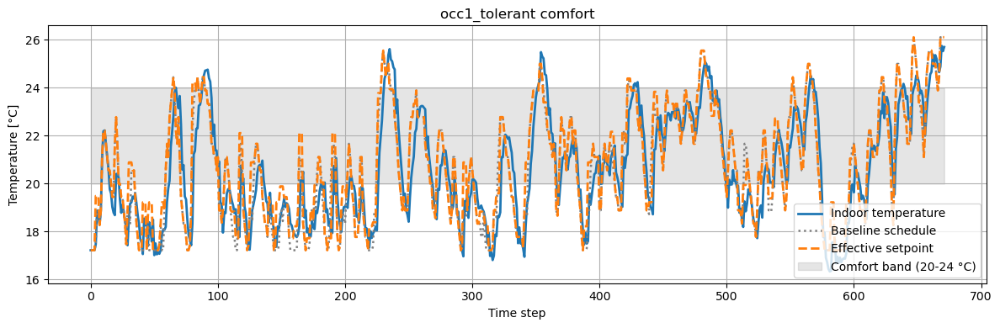


🔥 occ2_sensitive
Offline init: q_track=10.4702 r_u=0.6870 sp_bias=-0.1279


/tmp/ipykernel_16557/298174102.py:37: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  mpc_case.load_state_dict(torch.load(checkpoint_path, map_location=device), strict=False)



--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

...


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Reward: -48.66361536926059
Overrides: 107


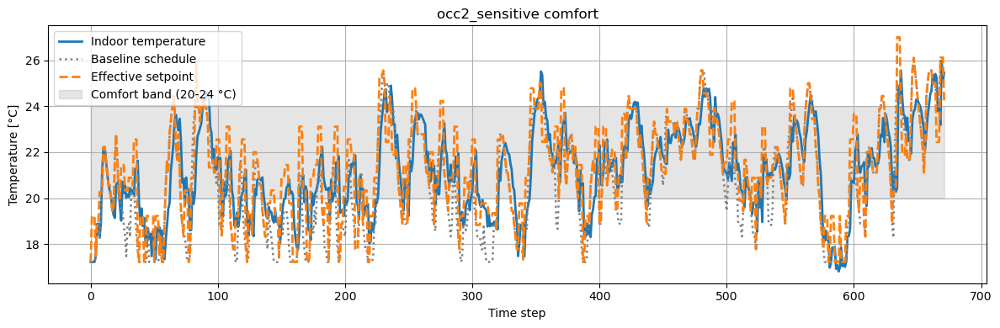


🔥 occ3_cold
Offline init: q_track=10.7932 r_u=0.5303 sp_bias=-0.1674


/tmp/ipykernel_16557/298174102.py:37: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  mpc_case.load_state_dict(torch.load(checkpoint_path, map_location=device), strict=False)



--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

KeyboardInterrupt: 

In [100]:
# =========================
# RUN OCCUPANT-SPECIFIC GNU-RL EXPERIMENTS
# =========================
WEEK_HOURS_OCC = 7 * 24
ONLINE_SIM_END_OCC = FEB_END
print(f"Occupant-specific online adaptation window: {FEB_START}-{ONLINE_SIM_END_OCC} | days={(ONLINE_SIM_END_OCC - FEB_START + 1) / 24:.0f}")

occupant_specific_results = {}
occupant_specific_summary_rows = []

print("Refreshing occupant-specific offline artifacts from disk...")
occupant_specific_offline_artifacts = {}

for label, spec in OCCUPANT_JANUARY_SPECS.items():
    checkpoint_path = Path(spec['checkpoint_path'])
    if not checkpoint_path.exists():
        raise FileNotFoundError(f"Missing occupant checkpoint for {label}: {checkpoint_path}")

    bundle = load_offline_bundle(spec['dataset_path'])
    occupant_specific_offline_artifacts[label] = {
        **spec,
        'checkpoint_path': checkpoint_path,
        'bundle': bundle,
    }

def run_gnu_rl_case_from_checkpoint(label, checkpoint_path, bundle, occupant, online_sim_end=FEB_END):
    print(f"\n🔥 {label}")

    mpc_case = PaperDiffMPC(
        T=OFFLINE_HORIZON,
        eta=DIFFMPC_ETA,
        rho_u=1.0,
        dt=1.0,
        u_min=DIFFMPC_U_MIN,
        u_max=DIFFMPC_U_MAX,
    ).to(device)
    mpc_case.load_state_dict(torch.load(checkpoint_path, map_location=device), strict=False)
    freeze_dynamics_parameters(mpc_case)
    mpc_case.eval()

    param_history_local = []
    weekly_training_local = []
    print_diffmpc_params_local('Offline init', mpc_case)
    param_history_local.append({
        'stage': 'offline_init',
        'week': 0,
        **diffmpc_param_snapshot_local(mpc_case),
    })

    n_weeks_local = int(np.ceil((online_sim_end - FEB_START + 1) / WEEK_HOURS_OCC))

    for week_idx in range(n_weeks_local):
        week_start = FEB_START + week_idx * WEEK_HOURS_OCC
        week_end = min(week_start + WEEK_HOURS_OCC - 1, online_sim_end)

        env_train = make_env_raw(
            sim_start=week_start,
            sim_end=week_end,
            reward_function=OccupantFeedbackReward,
        )
        env_train = OccupantWrapper(env_train, deepcopy(occupant))

        policy_stoch = StochasticDiffMPCPolicyWithNorms(
            mpc_case,
            x_mean=bundle['x_mean'],
            x_std=bundle['x_std'],
            norm_d_fn=bundle['norm_d'],
            sigma=ONLINE_SIGMA,
        )
        traj_local = collect_rollout(env_train, policy_stoch)
        advantages_local, _ = compute_advantages_with_baseline(
            traj_local,
            bundle['baseline_model'],
            gamma=BASELINE_GAMMA,
        )

        week_reward = float(np.sum([step['reward'] for step in traj_local]))
        week_overrides = int(getattr(env_train, 'override_count', 0))
        print(
            f"Week {week_idx + 1} train window {week_start}-{week_end} | "
            f"reward={week_reward:.3f} | overrides={week_overrides}"
        )

        ppo_update_mpc_with_norms(
            mpc_case,
            traj_local,
            advantages_local,
            x_mean=bundle['x_mean'],
            x_std=bundle['x_std'],
            norm_d_fn=bundle['norm_d'],
            clip_eps=ONLINE_CLIP_EPS,
            ppo_epochs=ONLINE_PPO_EPOCHS,
            minibatch_size=ONLINE_MINIBATCH,
            lr=ONLINE_LR_PPO,
            sigma=ONLINE_SIGMA,
        )

        print_diffmpc_params_local(f'After week {week_idx + 1}', mpc_case)
        weekly_training_local.append({
            'week': week_idx + 1,
            'sim_start': week_start,
            'sim_end': week_end,
            'train_reward': week_reward,
            'train_override_count': week_overrides,
        })
        param_history_local.append({
            'stage': f'week_{week_idx + 1}',
            'week': week_idx + 1,
            'sim_start': week_start,
            'sim_end': week_end,
            **diffmpc_param_snapshot_local(mpc_case),
        })

    env_eval = make_env_raw(
        sim_start=FEB_START,
        sim_end=online_sim_end,
        reward_function=OccupantFeedbackReward,
    )
    env_eval = OccupantWrapper(env_eval, deepcopy(occupant))
    policy_eval = DiffMPCPolicyRaw(mpc_case, bundle['x_mean'], bundle['x_std'], bundle['norm_d'])

    obs, _ = env_eval.reset()
    terminated = truncated = False
    reward_sum = 0.0
    while not (terminated or truncated):
        action = policy_eval.predict(obs)
        obs, reward, terminated, truncated, _ = env_eval.step(action)
        reward_sum += float(reward[0])

    override_count = int(getattr(env_eval, 'override_count', 0))
    district_kpis = env_eval.unwrapped.evaluate().copy()
    district_kpis = district_kpis[district_kpis['level'] == 'district'].copy()

    print('Reward:', reward_sum)
    print('Overrides:', override_count)
    plot_comfort(env_eval, title=f"{label} comfort")

    return {
        'reward': reward_sum,
        'override_count': override_count,
        'district_kpis': district_kpis,
        'param_history': pd.DataFrame(param_history_local),
        'weekly_training': pd.DataFrame(weekly_training_local),
    }

for label, occ in OCCUPANT_EXPERIMENTS.items():
    artifact = occupant_specific_offline_artifacts[label]
    result = run_gnu_rl_case_from_checkpoint(
        label,
        artifact['checkpoint_path'],
        artifact['bundle'],
        deepcopy(occ),
        online_sim_end=ONLINE_SIM_END_OCC,
    )
    occupant_specific_results[label] = result
    occupant_specific_summary_rows.append(
        summarize_district_kpis_local(
            label,
            result['district_kpis'],
            result['reward'],
            result['override_count'],
        )
    )

occupant_specific_summary = pd.DataFrame(occupant_specific_summary_rows)
display(occupant_specific_summary)




In [101]:
# ============================================================
# OFFLINE GNU-RL WITH PAPER-STYLE T_dyn REFERENCE (occupant-specific)
#
# What this does:
# 1) hard-codes the FITTED occupant parameters you provided
# 2) reconstructs a paper-style dynamic comfort reference T_dyn on January
#    from the occupant-specific January datasets
# 3) trains one offline DiffMPC per occupant using T_dyn instead of T_setpoint
#
# IMPORTANT:
# - This keeps the SAME DiffMPC, SAME loss, SAME hyperparameters
# - Only the reference sp_seq is changed:
#       old: scheduled heating setpoint
#       new: paper-style persistent T_dyn
# - T_dyn is initialized from the baseline schedule and updated only when a
#   NEW override start is detected, exactly like your working MPC logic
#
# Assumes these are already defined from your previous notebook cells:
#   - device
#   - NOTEBOOK_DIR
#   - make_env_raw   (preferred) or make_env
#   - PaperDiffMPC
#   - one_step_pred
#   - build_baseline_features
#   - IDX_T_IN, IDX_T_OUT, IDX_SOLAR, IDX_T_SP
#   - OFFLINE_HORIZON, OFFLINE_EPOCHS, OFFLINE_LR, OFFLINE_LAMBDA
#   - OFFLINE_BATCH_TS, OFFLINE_PATIENCE
#   - BASELINE_GAMMA, DIFFMPC_ETA, DIFFMPC_U_MIN, DIFFMPC_U_MAX
# ============================================================

from copy import deepcopy
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import Ridge
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 0) HARDCODED FITTED OCCUPANTS (experimental, as requested)
# ------------------------------------------------------------
FITTED_OCCUPANTS_EXPERIMENTAL = {
    "occ1_tolerant": {"T_pref": 21.861014, "b": 1.198849, "max_prob": 0.4, "duration": 3},
    "occ2_sensitive": {"T_pref": 23.035896, "b": 3.451184, "max_prob": 0.4, "duration": 3},
    "occ3_cold": {"T_pref": 19.957358, "b": 2.618482, "max_prob": 0.4, "duration": 3},
    "occ4_hot": {"T_pref": 23.909844, "b": 2.570147, "max_prob": 0.4, "duration": 3},
}

# ------------------------------------------------------------
# 1) OCCUPANT JANUARY DATASETS + NEW CHECKPOINT NAMES
# ------------------------------------------------------------
OCCUPANT_JANUARY_TDYN_SPECS = {
    "occ1_tolerant": {
        "dataset_path": NOTEBOOK_DIR / "january_pi_dataset_occ1.npz",
        "checkpoint_path": NOTEBOOK_DIR / "ibex_offline_pretrained_occ1_tdyn.pt",
    },
    "occ2_sensitive": {
        "dataset_path": NOTEBOOK_DIR / "january_pi_dataset_occ2.npz",
        "checkpoint_path": NOTEBOOK_DIR / "ibex_offline_pretrained_occ2_tdyn.pt",
    },
    "occ3_cold": {
        "dataset_path": NOTEBOOK_DIR / "january_pi_dataset_occ3.npz",
        "checkpoint_path": NOTEBOOK_DIR / "ibex_offline_pretrained_occ3_tdyn.pt",
    },
    "occ4_hot": {
        "dataset_path": NOTEBOOK_DIR / "january_pi_dataset_occ4.npz",
        "checkpoint_path": NOTEBOOK_DIR / "ibex_offline_pretrained_occ4_tdyn.pt",
    },
}

# ------------------------------------------------------------
# 2) SAME T_dyn SETTINGS AS YOUR WORKING MPC
# ------------------------------------------------------------
TDYN_INIT_MODE = "schedule"   # exactly like your MPC
TDYN_DELTA_UP = 0.5
TDYN_DELTA_DOWN = 0.5
TDYN_MIN = 18.0
TDYN_MAX = 26.0

# ------------------------------------------------------------
# 3) HELPERS
# ------------------------------------------------------------
def _get_env_builder():
    if "make_env_raw" in globals():
        return make_env_raw
    elif "make_env" in globals():
        return make_env
    else:
        raise RuntimeError("Neither make_env_raw nor make_env is defined.")

def load_occ_npz_bundle(dataset_path):
    dataset_path = Path(dataset_path)
    if not dataset_path.exists():
        raise FileNotFoundError(f"Missing dataset: {dataset_path}")

    data_local = np.load(dataset_path)

    states_np_local = np.asarray(data_local["states"], dtype=np.float32)[:, 0, :]
    actions_np_local = np.asarray(data_local["actions"], dtype=np.float32)[:, 0, :]
    next_states_np_local = np.asarray(data_local["next_states"], dtype=np.float32)[:, 0, :]
    rewards_np_local = np.asarray(data_local["rewards"], dtype=np.float32).reshape(-1)

    return {
        "dataset_path": dataset_path,
        "states_np": states_np_local,
        "actions_np": actions_np_local,
        "next_states_np": next_states_np_local,
        "rewards_np": rewards_np_local,
    }

def get_january_baseline_schedule(n_steps):
    """
    Baseline schedule for the same January window.
    This uses the environment schedule (without control), not the effective setpoint.
    """
    env_builder = _get_env_builder()

    # infer January window from the dataset length
    jan_start = 0
    jan_end = jan_start + int(n_steps) - 1

    env_jan = env_builder(
        sim_start=jan_start,
        sim_end=jan_end,
    ) if env_builder.__name__ == "make_env_raw" else env_builder(
        simulation_start_time_step=jan_start,
        simulation_end_time_step=jan_end,
    )

    b = env_jan.unwrapped.buildings[0]
    sched = np.asarray(
        b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control,
        dtype=np.float32
    ).reshape(-1)

    if len(sched) < n_steps:
        raise RuntimeError(
            f"Baseline schedule length {len(sched)} is smaller than n_steps={n_steps}."
        )

    return sched[:n_steps].copy()

def detect_override_starts_from_effective_setpoint(
    effective_tsp,
    baseline_tsp,
    duration=3,
    eps=0.25,
):
    """
    Detect NEW override starts from the observed effective setpoint sequence.

    We do not have the feedback signal in the npz, so we reconstruct starts from:
        diff[t] = effective_tsp[t] - baseline_tsp[t]

    Greedy cooldown logic:
    - if |diff[t]| > eps and we are not inside a persistence cooldown,
      treat that timestep as a NEW override start
    - sign(diff[t]) gives warmer (+1) or cooler (-1)
    - then ignore the next duration-1 steps as persistence

    This matches the wrapper logic well enough for the offline T_dyn reference.
    """
    effective_tsp = np.asarray(effective_tsp, dtype=np.float32).reshape(-1)
    baseline_tsp = np.asarray(baseline_tsp, dtype=np.float32).reshape(-1)

    n = min(len(effective_tsp), len(baseline_tsp))
    diff = effective_tsp[:n] - baseline_tsp[:n]

    starts = np.zeros(n, dtype=np.int64)
    cooldown = 0

    for t in range(n):
        if cooldown > 0:
            cooldown -= 1
            continue

        if abs(diff[t]) > eps:
            starts[t] = 1 if diff[t] > 0 else -1
            cooldown = max(int(duration) - 1, 0)

    return starts

def build_tdyn_from_override_starts(
    baseline_tsp,
    override_starts,
    T_pref=None,
    init_mode="schedule",
    delta_up=0.5,
    delta_down=0.5,
    tdyn_min=18.0,
    tdyn_max=26.0,
):
    """
    EXACTLY like your working MPC logic:
    - initialize T_dyn from schedule (or pref if requested)
    - update only when a NEW feedback/override event starts
    - otherwise keep it unchanged
    """
    baseline_tsp = np.asarray(baseline_tsp, dtype=np.float32).reshape(-1)
    override_starts = np.asarray(override_starts, dtype=np.int64).reshape(-1)

    n = min(len(baseline_tsp), len(override_starts))
    baseline_tsp = baseline_tsp[:n]
    override_starts = override_starts[:n]

    if init_mode == "schedule":
        T_dyn = float(baseline_tsp[0])
    elif init_mode == "pref":
        if T_pref is None:
            raise ValueError("T_pref must be provided if init_mode='pref'.")
        T_dyn = float(T_pref)
    else:
        raise ValueError("init_mode must be 'schedule' or 'pref'.")

    Tdyn_seq = np.zeros(n, dtype=np.float32)
    Tdyn_seq[0] = np.clip(T_dyn, tdyn_min, tdyn_max)

    for t in range(1, n):
        T_dyn = float(Tdyn_seq[t - 1])

        if override_starts[t] > 0:
            T_dyn += float(delta_up)
        elif override_starts[t] < 0:
            T_dyn -= float(delta_down)

        T_dyn = float(np.clip(T_dyn, tdyn_min, tdyn_max))
        Tdyn_seq[t] = T_dyn

    return Tdyn_seq

def build_offline_bundle_with_tdyn(label, spec, occupant_params):
    """
    Build the same offline bundle as before, except:
    - adds Tdyn_np
    - replaces sp forecast with Tdyn forecast
    """
    raw = load_occ_npz_bundle(spec["dataset_path"])

    states_np_local = raw["states_np"]
    actions_np_local = raw["actions_np"]
    next_states_np_local = raw["next_states_np"]
    rewards_np_local = raw["rewards_np"]

    N_local = states_np_local.shape[0]

    # Effective setpoint observed in dataset
    effective_tsp_np = states_np_local[:, IDX_T_SP].astype(np.float32)

    # Baseline schedule from the env for same January window
    baseline_tsp_np = get_january_baseline_schedule(N_local)

    # Reconstruct new override starts from effective-vs-baseline setpoint
    override_starts_np = detect_override_starts_from_effective_setpoint(
        effective_tsp=effective_tsp_np,
        baseline_tsp=baseline_tsp_np,
        duration=int(occupant_params["duration"]),
        eps=0.25,
    )

    # Build persistent T_dyn exactly like the working MPC
    Tdyn_np = build_tdyn_from_override_starts(
        baseline_tsp=baseline_tsp_np,
        override_starts=override_starts_np,
        T_pref=float(occupant_params["T_pref"]),
        init_mode=TDYN_INIT_MODE,
        delta_up=TDYN_DELTA_UP,
        delta_down=TDYN_DELTA_DOWN,
        tdyn_min=TDYN_MIN,
        tdyn_max=TDYN_MAX,
    )

    states_local = torch.tensor(states_np_local, device=device)
    actions_local = torch.tensor(actions_np_local, device=device)
    next_states_local = torch.tensor(next_states_np_local, device=device)
    Tdyn_local = torch.tensor(Tdyn_np, dtype=torch.float32, device=device)

    split_local = int(0.8 * N_local)
    train_ids_local = np.arange(0, split_local)
    val_ids_local = np.arange(split_local, N_local)

    x_mean_local = states_local[train_ids_local, IDX_T_IN].mean()
    x_std_local = states_local[train_ids_local, IDX_T_IN].std() + 1e-6
    d1_mean_local = states_local[train_ids_local, IDX_T_OUT].mean()
    d1_std_local = states_local[train_ids_local, IDX_T_OUT].std() + 1e-6
    d2_mean_local = states_local[train_ids_local, IDX_SOLAR].mean()
    d2_std_local = states_local[train_ids_local, IDX_SOLAR].std() + 1e-6

    def norm_x_local(x):
        return (x - x_mean_local) / x_std_local

    def norm_sp_local(sp):
        return (sp - x_mean_local) / x_std_local

    def norm_d_local(d):
        d_out = (d[..., 0:1] - d1_mean_local) / d1_std_local
        d_sol = (d[..., 1:2] - d2_mean_local) / d2_std_local
        return torch.cat([d_out, d_sol], dim=-1)

    def d_forecast_from_dataset_local(t, T):
        end = min(t + T, N_local)
        d = torch.stack(
            [states_local[t:end, IDX_T_OUT], states_local[t:end, IDX_SOLAR]],
            dim=1,
        )
        if d.shape[0] < T:
            d = torch.cat([d, d[-1:].repeat(T - d.shape[0], 1)], dim=0)
        return d

    def tdyn_forecast_from_dataset_local(t, T):
        end = min(t + T, N_local)
        sp = Tdyn_local[t:end].view(-1, 1)
        if sp.shape[0] < T:
            sp = torch.cat([sp, sp[-1:].repeat(T - sp.shape[0], 1)], dim=0)
        return sp

    # same baseline regression logic as before
    Z_local = np.vstack([build_baseline_features(states_np_local[t], None) for t in range(N_local)])
    returns_local = np.zeros_like(rewards_np_local)
    running_local = 0.0
    for t in reversed(range(N_local)):
        running_local = rewards_np_local[t] + BASELINE_GAMMA * running_local
        returns_local[t] = running_local

    baseline_model_local = Ridge(alpha=1e-3)
    baseline_model_local.fit(Z_local, returns_local)

    return {
        "label": label,
        "dataset_path": spec["dataset_path"],
        "states_np": states_np_local,
        "actions_np": actions_np_local,
        "next_states_np": next_states_np_local,
        "rewards_np": rewards_np_local,
        "Tdyn_np": Tdyn_np,
        "baseline_tsp_np": baseline_tsp_np,
        "effective_tsp_np": effective_tsp_np,
        "override_starts_np": override_starts_np,
        "states": states_local,
        "actions": actions_local,
        "next_states": next_states_local,
        "Tdyn": Tdyn_local,
        "N": N_local,
        "train_ids": train_ids_local,
        "val_ids": val_ids_local,
        "x_mean": x_mean_local,
        "x_std": x_std_local,
        "norm_x": norm_x_local,
        "norm_sp": norm_sp_local,
        "norm_d": norm_d_local,
        "d_forecast_from_dataset": d_forecast_from_dataset_local,
        "tdyn_forecast_from_dataset": tdyn_forecast_from_dataset_local,
        "baseline_model": baseline_model_local,
    }

def train_diffmpc_from_bundle_with_tdyn(label, bundle, checkpoint_path):
    """
    SAME training as your original occupant-specific GNU-RL offline stage,
    except the tracking reference is T_dyn instead of T_setpoint.
    """
    checkpoint_path = Path(checkpoint_path)

    mpc_local = PaperDiffMPC(
        T=OFFLINE_HORIZON,
        eta=DIFFMPC_ETA,
        rho_u=1.0,
        dt=1.0,
        u_min=DIFFMPC_U_MIN,
        u_max=DIFFMPC_U_MAX,
        q_reg=1e-4,
        qp_max_iter=200,
        qp_eps=1e-6,
    ).to(device)

    opt_local = torch.optim.Adam(mpc_local.parameters(), lr=OFFLINE_LR)

    @torch.no_grad()
    def eval_loss_local(ids):
        mpc_local.eval()
        losses_local = []

        for t in ids:
            x_t = bundle["norm_x"](bundle["states"][t, IDX_T_IN]).view(1, 1)
            x_next_true = bundle["norm_x"](bundle["next_states"][t, IDX_T_IN]).view(1, 1)
            u_t = bundle["actions"][t].view(1, 1)

            d_seq = bundle["norm_d"](
                bundle["d_forecast_from_dataset"](t, mpc_local.T)
            ).view(1, mpc_local.T, 2)

            # ONLY CHANGE: T_dyn forecast instead of dataset setpoint forecast
            sp_seq = bundle["norm_sp"](
                bundle["tdyn_forecast_from_dataset"](t, mpc_local.T)
            ).view(1, mpc_local.T, 1)

            u_mpc, _, _ = mpc_local(x_t, d_seq, sp_seq)
            x_next_pred = one_step_pred(mpc_local, x_t, u_t, d_seq)

            loss_local = (
                OFFLINE_LAMBDA * (x_next_true - x_next_pred).pow(2).mean()
                + (u_t - u_mpc).pow(2).mean()
            )
            losses_local.append(float(loss_local.item()))

        return float(np.mean(losses_local))

    best_val_local = float("inf")
    best_sd_local = None
    pat_local = 0
    history_rows_local = []
    rng_local = np.random.default_rng(0)
    train_ids_local = bundle["train_ids"].copy()

    for epoch in range(OFFLINE_EPOCHS):
        mpc_local.train()
        rng_local.shuffle(train_ids_local)
        batch_losses_local = []

        for start in range(0, len(train_ids_local), OFFLINE_BATCH_TS):
            batch = train_ids_local[start:start + OFFLINE_BATCH_TS]
            opt_local.zero_grad()
            loss_batch_local = 0.0

            for t in batch:
                x_t = bundle["norm_x"](bundle["states"][t, IDX_T_IN]).view(1, 1)
                x_next_true = bundle["norm_x"](bundle["next_states"][t, IDX_T_IN]).view(1, 1)
                u_t = bundle["actions"][t].view(1, 1)

                d_seq = bundle["norm_d"](
                    bundle["d_forecast_from_dataset"](t, mpc_local.T)
                ).view(1, mpc_local.T, 2)

                # ONLY CHANGE: T_dyn forecast instead of dataset setpoint forecast
                sp_seq = bundle["norm_sp"](
                    bundle["tdyn_forecast_from_dataset"](t, mpc_local.T)
                ).view(1, mpc_local.T, 1)

                u_mpc, _, _ = mpc_local(x_t, d_seq, sp_seq)
                x_next_pred = one_step_pred(mpc_local, x_t, u_t, d_seq)

                loss_local = (
                    OFFLINE_LAMBDA * (x_next_true - x_next_pred).pow(2).mean()
                    + (u_t - u_mpc).pow(2).mean()
                )
                loss_batch_local = loss_batch_local + loss_local

            loss_batch_local = loss_batch_local / max(1, len(batch))
            loss_batch_local.backward()
            torch.nn.utils.clip_grad_norm_(mpc_local.parameters(), 1.0)
            opt_local.step()
            batch_losses_local.append(float(loss_batch_local.item()))

        val_local = eval_loss_local(bundle["val_ids"])
        tr_local = float(np.mean(batch_losses_local))
        params_local = {
            "q_track": float(mpc_local.q_track().item()),
            "r_u": float(mpc_local.r_u().item()),
            "sp_bias": float(mpc_local.sp_bias().item()),
        }
        history_rows_local.append({
            "epoch": epoch,
            "train_loss": tr_local,
            "val_loss": val_local,
            **params_local,
        })

        print(
            f"{label} | Epoch {epoch:03d} | Train {tr_local:.6f} | Val {val_local:.6f} | "
            f"q_track={params_local['q_track']:.4f} "
            f"r_u={params_local['r_u']:.4f} "
            f"sp_bias={params_local['sp_bias']:.4f}"
        )

        if val_local < best_val_local - 1e-6:
            best_val_local = val_local
            best_sd_local = deepcopy(mpc_local.state_dict())
            pat_local = 0
        else:
            pat_local += 1
            if pat_local >= OFFLINE_PATIENCE:
                print(f"{label} | Early stopping.")
                break

    if best_sd_local is None:
        best_sd_local = deepcopy(mpc_local.state_dict())

    mpc_local.load_state_dict(best_sd_local)
    torch.save(best_sd_local, checkpoint_path)
    print(f"Saved T_dyn offline checkpoint: {checkpoint_path}")

    return {
        "label": label,
        "mpc": mpc_local,
        "best_val": float(best_val_local),
        "checkpoint_path": checkpoint_path,
        "history": pd.DataFrame(history_rows_local),
    }

# ------------------------------------------------------------
# 4) RUN OCCUPANT-SPECIFIC OFFLINE TRAINING WITH T_dyn COST
# ------------------------------------------------------------
occupant_specific_tdyn_offline_artifacts = {}
occupant_specific_tdyn_offline_summary_rows = []

for label, spec in OCCUPANT_JANUARY_TDYN_SPECS.items():
    print(f"\n🔥 Offline T_dyn imitation learning: {label}")

    occ_params = FITTED_OCCUPANTS_EXPERIMENTAL[label]
    bundle = build_offline_bundle_with_tdyn(label, spec, occ_params)
    result = train_diffmpc_from_bundle_with_tdyn(label, bundle, spec["checkpoint_path"])

    occupant_specific_tdyn_offline_artifacts[label] = {
        **spec,
        **result,
        "bundle": bundle,
        "fitted_occupant": occ_params,
    }

    occupant_specific_tdyn_offline_summary_rows.append({
        "occupant": label,
        "dataset_path": str(spec["dataset_path"]),
        "checkpoint_path": str(result["checkpoint_path"]),
        "samples": int(bundle["N"]),
        "best_val": float(result["best_val"]),
        "T_pref_hat": float(occ_params["T_pref"]),
        "b_hat": float(occ_params["b"]),
        "override_starts_detected": int(np.count_nonzero(bundle["override_starts_np"])),
        "Tdyn_min": float(np.min(bundle["Tdyn_np"])),
        "Tdyn_max": float(np.max(bundle["Tdyn_np"])),
    })

occupant_specific_tdyn_offline_summary = pd.DataFrame(occupant_specific_tdyn_offline_summary_rows)
display(occupant_specific_tdyn_offline_summary)

# ------------------------------------------------------------
# 5) OPTIONAL SANITY PLOTS
# ------------------------------------------------------------
for label, artifact in occupant_specific_tdyn_offline_artifacts.items():
    bundle = artifact["bundle"]

    plt.figure(figsize=(12, 3.5))
    plt.plot(bundle["baseline_tsp_np"], label="baseline schedule", linestyle=":")
    plt.plot(bundle["effective_tsp_np"], label="effective dataset setpoint", alpha=0.8)
    plt.plot(bundle["Tdyn_np"], label="T_dyn reference", linewidth=2)
    plt.title(f"{label} | January offline reference construction")
    plt.xlabel("Time step")
    plt.ylabel("Temperature [°C]")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 6) FINAL OBJECTS EXPOSED FOR NEXT CELLS
# ------------------------------------------------------------
print("\nDone. Available objects:")
print("  - FITTED_OCCUPANTS_EXPERIMENTAL")
print("  - OCCUPANT_JANUARY_TDYN_SPECS")
print("  - occupant_specific_tdyn_offline_artifacts")
print("  - occupant_specific_tdyn_offline_summary")

print("\nSaved checkpoints:")
for label, artifact in occupant_specific_tdyn_offline_artifacts.items():
    print(f"  {label}: {artifact['checkpoint_path']}")


🔥 Offline T_dyn imitation learning: occ1_tolerant


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

KeyboardInterrupt: 

Occupant-specific T_dyn online adaptation window: 744-1415 | days=28

🔥 occ1_tolerant
Offline init: q_track=10.4682 r_u=0.7018 sp_bias=-0.1476


/home/kostas/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=2.18883e-11): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/tmp/ipykernel_16557/623032609.py:603: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for a


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

...


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Reward: -32.989628130365
Overrides: 10


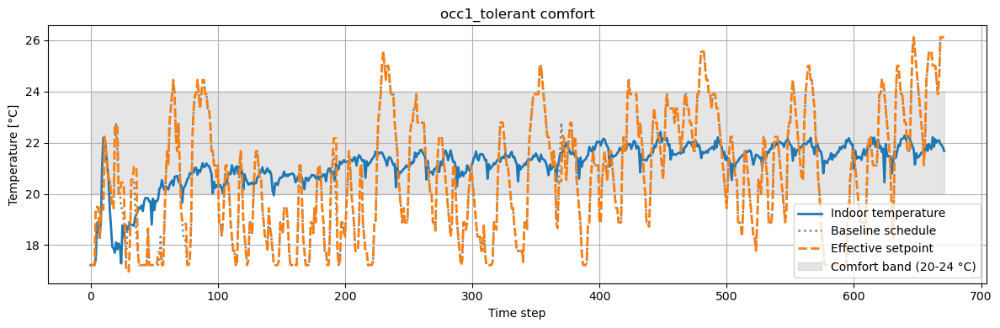

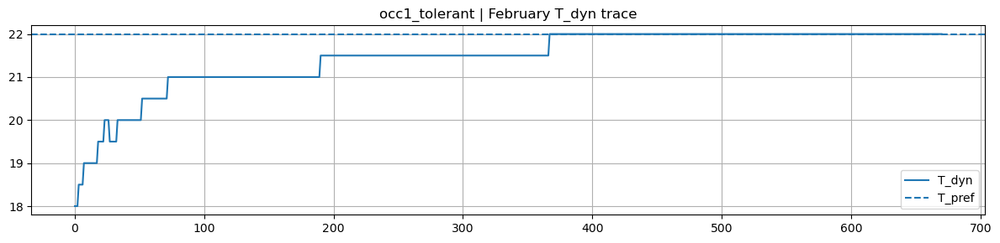

/home/kostas/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=2.19007e-11): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/tmp/ipykernel_16557/623032609.py:603: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for a


🔥 occ2_sensitive
Offline init: q_track=10.4702 r_u=0.6870 sp_bias=-0.1279


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

...


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Reward: -43.11553815163645
Overrides: 20


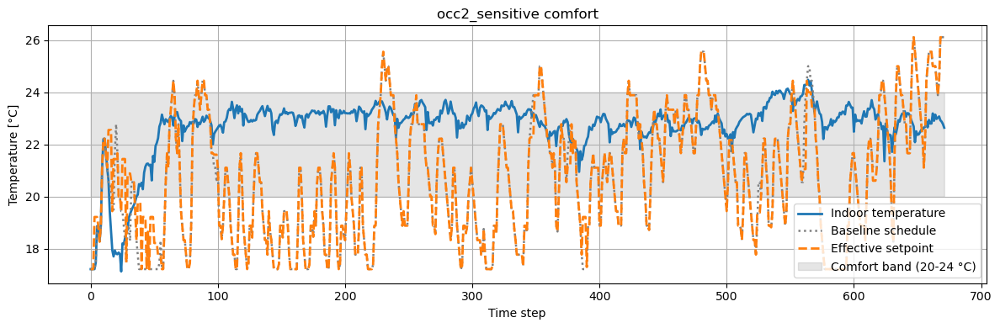

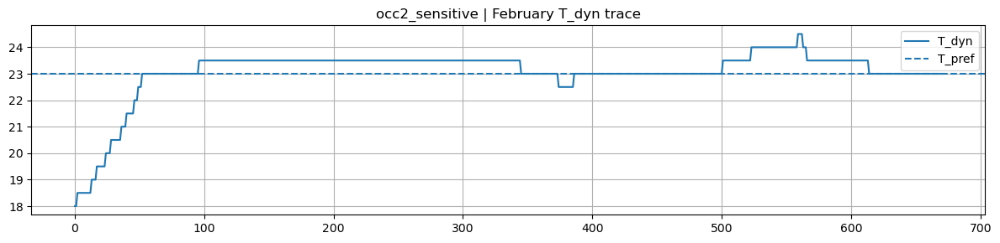

/home/kostas/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=2.1902e-11): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/tmp/ipykernel_16557/623032609.py:603: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for an


🔥 occ3_cold
Offline init: q_track=10.7932 r_u=0.5303 sp_bias=-0.1674


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

...


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Reward: -26.71449030442726
Overrides: 10


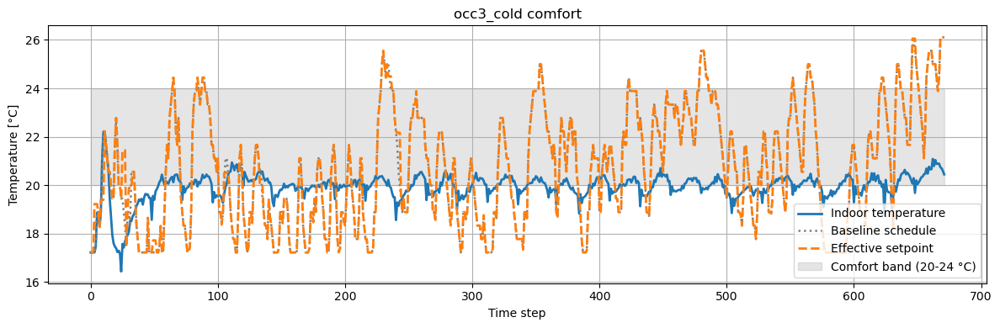

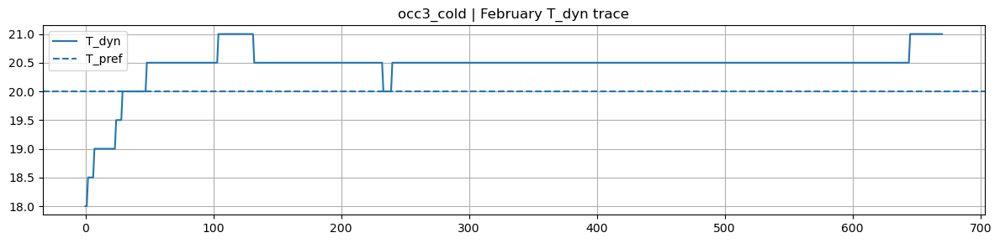

/home/kostas/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=2.18958e-11): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/tmp/ipykernel_16557/623032609.py:603: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for a


🔥 occ4_hot
Offline init: q_track=10.9502 r_u=0.4104 sp_bias=-0.1383


/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

...


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat

Reward: -46.9550827785124
Overrides: 13


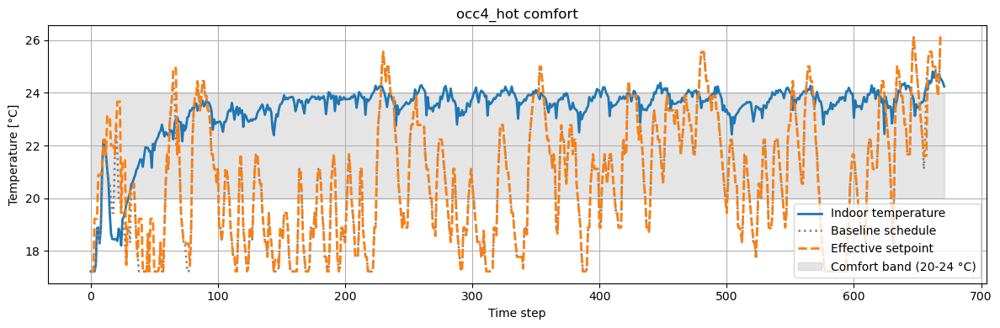

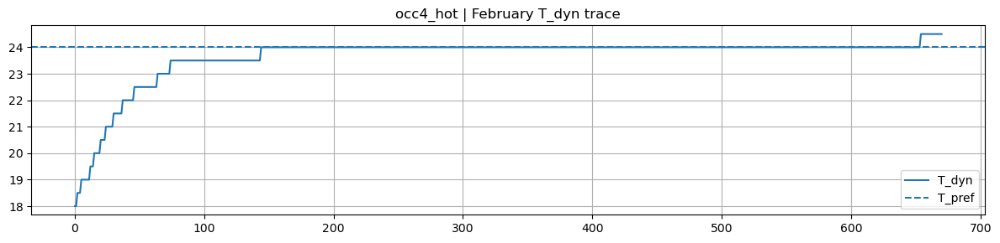

,occupant,override_count,reward,electricity_consumption_total,discomfort_proportion,discomfort_cold_proportion,discomfort_hot_proportion,daily_peak_average
0,occ1_tolerant,10,-32.989628,1.029741,0.444275,0.154198,0.290076,1.024195
1,occ2_sensitive,20,-43.115538,1.123080,0.563359,0.059542,0.503817,1.064185
2,occ3_cold,10,-26.714490,0.964853,0.471756,0.331298,0.140458,0.996227
3,occ4_hot,13,-46.955083,1.160668,0.612214,0.029008,0.583206,1.082344


In [102]:
# ============================================================
# FEBRUARY GNU-RL WITH CORRECT PAPER-STYLE T_dyn REFERENCE
# Uses the SAME T_dyn logic as the working MPC:
#   - init from schedule_without_control or occupant.T_pref
#   - update ONLY when a NEW override starts
#   - feedback direction is computed against schedule_without_control
#
# Assumes these already exist in the notebook:
#   OCCUPANT_JANUARY_SPECS
#   load_offline_bundle
#   freeze_dynamics_parameters
#   PaperDiffMPC
#   collect_rollout / or not needed
#   ppo_update_mpc_with_norms
#   compute_advantages_with_baseline
#   make_env_raw
#   Occupant
#   OccupantFeedbackReward
#   plot_comfort
#   device
#   OFFLINE_HORIZON, DIFFMPC_ETA, DIFFMPC_U_MIN, DIFFMPC_U_MAX
#   ONLINE_SIGMA, ONLINE_CLIP_EPS, ONLINE_PPO_EPOCHS, ONLINE_MINIBATCH, ONLINE_LR_PPO
#   BASELINE_GAMMA, FEB_START, FEB_END
#   diffmpc_param_snapshot_local, print_diffmpc_params_local, summarize_district_kpis_local
#   d_forecast_from_obs
#
# Occupants are taken from:
#   fitted_occupants_named
# if present, else:
#   occupants
# ============================================================

from copy import deepcopy
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import gymnasium as gym
import matplotlib.pyplot as plt
from torch.distributions import Normal

# ------------------------------------------------------------
# 0) USE EXISTING FITTED OCCUPANTS, NO HARDCODING
# ------------------------------------------------------------
if "fitted_occupants_named" in globals():
    TDYN_OCCUPANTS = {k: deepcopy(v) for k, v in fitted_occupants_named.items()}
elif "occupants" in globals():
    TDYN_OCCUPANTS = {k: deepcopy(v) for k, v in occupants.items()}
else:
    raise RuntimeError("Need fitted_occupants_named or occupants in globals().")

# ------------------------------------------------------------
# 1) SAME T_dyn SETTINGS AS WORKING MPC
# ------------------------------------------------------------
TDYN_ONLINE_CONFIG = dict(
    T_dyn_init_mode="schedule",   # "schedule" or "pref"
    delta_up=0.5,
    delta_down=0.5,
    drift_to_pref=0.0,
    T_dyn_min=18.0,
    T_dyn_max=26.0,
)

WEEK_HOURS_TDYN = 7 * 24
ONLINE_SIM_END_TDYN = FEB_END

# ------------------------------------------------------------
# 2) WRAPPER WITH last_feedback EXACTLY LIKE THE WORKING MPC
# ------------------------------------------------------------
class OccupantWrapperWithFeedback(gym.Wrapper):
    def __init__(self, env, occupant):
        super().__init__(env)
        self.occupant = occupant

        # passthrough attrs some agents/tools expect
        if hasattr(env, "observation_names"):
            self.observation_names = env.observation_names
        if hasattr(env.unwrapped, "action_names"):
            self.action_names = env.unwrapped.action_names
        self.observation_space = env.observation_space
        self.action_space = env.action_space

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)

        self.occupant.override_timer = 0
        self.occupant.override_setpoint = None
        self.occupant.last_override_started = False

        self.override_count = 0
        self.last_feedback = 0  # +1 warmer, -1 cooler, 0 none

        b = self.env.unwrapped.buildings[0]
        self.effective_setpoints = [
            float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[b.time_step])
        ]
        self.baseline_setpoints = [
            float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[b.time_step])
        ]

        return obs, info

    def step(self, action):
        b = self.env.unwrapped.buildings[0]
        current_ix = b.time_step

        Tin = float(b.energy_simulation.indoor_dry_bulb_temperature[current_ix])
        next_ix = min(
            current_ix + 1,
            len(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point) - 1
        )

        occupied_next = float(b.energy_simulation.occupant_count[next_ix]) > 0.0
        scheduled_next_Tsp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[next_ix]
        )

        if occupied_next:
            new_Tsp = self.occupant.step(Tin, scheduled_next_Tsp, occupied=True)
        else:
            new_Tsp = self.occupant.step(Tin, scheduled_next_Tsp, occupied=False)

        self.last_feedback = 0
        if self.occupant.last_override_started:
            self.override_count += 1
            if new_Tsp > scheduled_next_Tsp:
                self.last_feedback = +1
            elif new_Tsp < scheduled_next_Tsp:
                self.last_feedback = -1

        b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[next_ix] = new_Tsp

        obs, reward, terminated, truncated, info = self.env.step(action)

        current_effective_sp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[b.time_step]
        )
        current_baseline_sp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[b.time_step]
        )
        self.effective_setpoints.append(current_effective_sp)
        self.baseline_setpoints.append(current_baseline_sp)

        return obs, reward, terminated, truncated, info


# ------------------------------------------------------------
# 3) STOCHASTIC POLICY USING T_dyn AS THE MPC REFERENCE
# ------------------------------------------------------------
class StochasticDiffMPCPolicyWithNormsTDyn:
    def __init__(
        self,
        mpc,
        x_mean,
        x_std,
        norm_d_fn,
        occupant,
        sigma=0.05,
        T_dyn_init_mode="schedule",
        delta_up=0.5,
        delta_down=0.5,
        drift_to_pref=0.0,
        T_dyn_min=18.0,
        T_dyn_max=26.0,
    ):
        self.mpc = mpc
        self.sigma = float(sigma)
        self.x_mean = x_mean
        self.x_std = x_std
        self.norm_d_fn = norm_d_fn
        self.occupant = deepcopy(occupant)

        self.T_dyn_init_mode = T_dyn_init_mode
        self.delta_up = float(delta_up)
        self.delta_down = float(delta_down)
        self.drift_to_pref = float(drift_to_pref)
        self.T_dyn_min = float(T_dyn_min)
        self.T_dyn_max = float(T_dyn_max)

        self.w_est = 0.0
        self.gamma = 0.2
        self.prev_T = None
        self.prev_u = None
        self.prev_Tout = None
        self.prev_Isol = None
        self.last_history_bias = 0.0
        self.T_dyn = None

    def snapshot_state(self):
        return {
            "w_est": float(self.w_est),
            "prev_T": None if self.prev_T is None else float(self.prev_T),
            "prev_u": None if self.prev_u is None else float(self.prev_u),
            "prev_Tout": None if self.prev_Tout is None else float(self.prev_Tout),
            "prev_Isol": None if self.prev_Isol is None else float(self.prev_Isol),
            "T_dyn": None if self.T_dyn is None else float(self.T_dyn),
        }

    def restore_state(self, state):
        self.w_est = float(state["w_est"])
        self.prev_T = state["prev_T"]
        self.prev_u = state["prev_u"]
        self.prev_Tout = state["prev_Tout"]
        self.prev_Isol = state["prev_Isol"]
        self.T_dyn = state["T_dyn"]

    def initialize_tdyn_from_env(self, env):
        b = env.unwrapped.buildings[0]
        scheduled_now = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[b.time_step]
        )

        if self.T_dyn_init_mode == "schedule":
            self.T_dyn = scheduled_now
        elif self.T_dyn_init_mode == "pref":
            self.T_dyn = float(self.occupant.T_pref)
        else:
            raise ValueError("T_dyn_init_mode must be 'schedule' or 'pref'")

        self.T_dyn = float(np.clip(self.T_dyn, self.T_dyn_min, self.T_dyn_max))

    def update_tdyn_from_feedback(self, feedback):
        if self.T_dyn is None:
            return

        if self.occupant is not None and self.drift_to_pref > 0.0:
            self.T_dyn = (
                (1.0 - self.drift_to_pref) * self.T_dyn
                + self.drift_to_pref * float(self.occupant.T_pref)
            )

        if feedback > 0:
            self.T_dyn += self.delta_up
        elif feedback < 0:
            self.T_dyn -= self.delta_down

        self.T_dyn = float(np.clip(self.T_dyn, self.T_dyn_min, self.T_dyn_max))

    def _updated_offset_state(self, Tin, Tout, Isol, state):
        local_state = {
            "w_est": float(state["w_est"]),
            "prev_T": state["prev_T"],
            "prev_u": state["prev_u"],
            "prev_Tout": state["prev_Tout"],
            "prev_Isol": state["prev_Isol"],
            "T_dyn": state["T_dyn"],
        }

        if local_state["prev_T"] is None:
            return local_state

        cop = float(self.mpc.cop_a + self.mpc.cop_b * local_state["prev_Tout"])
        cop = np.clip(cop, self.mpc.cop_min, self.mpc.cop_max)

        C = float(self.mpc._pos(self.mpc.C_raw))
        Rm = float(self.mpc._pos(self.mpc.Rm_raw))
        Rout = float(self.mpc._pos(self.mpc.Rout_raw))
        Aeff = float(self.mpc._pos(self.mpc.Aeff_raw))
        Pnom = float(self.mpc._pos(self.mpc.Pnom_raw))

        Ac = -(1 / (Rm * C) + 1 / (Rout * C))
        A = np.exp(Ac)
        phi = (A - 1) / Ac if abs(Ac) > 1e-6 else 1.0

        Bu = phi * (cop * Pnom / C)
        Bd0 = phi * (1 / (Rm * C))
        Bd1 = phi * (1 / (Rout * C))
        Bd2 = phi * (Aeff / C)

        T_pred = (
            A * local_state["prev_T"]
            + Bu * local_state["prev_u"]
            + Bd0 * self.mpc.Tm.item()
            + Bd1 * local_state["prev_Tout"]
            + Bd2 * local_state["prev_Isol"]
            + local_state["w_est"]
        )

        err = Tin - T_pred
        local_state["w_est"] = float(local_state["w_est"] + self.gamma * err)
        return local_state

    def _mpc_mean_action(self, obs, policy_state=None, update_internal=True):
        o = np.asarray(obs, dtype=np.float32).reshape(-1)

        Tin = float(o[IDX_T_IN])
        Tout = float(o[IDX_T_OUT])
        Isol = float(o[IDX_SOLAR])

        state_in = self.snapshot_state() if policy_state is None else policy_state
        state_work = self._updated_offset_state(Tin, Tout, Isol, state_in)

        if state_work["T_dyn"] is None:
            raise RuntimeError("T_dyn not initialized. Call initialize_tdyn_from_env(env) after env.reset().")

        x_t = torch.tensor(
            [[(Tin - self.x_mean.item()) / self.x_std.item()]],
            dtype=torch.float32,
            device=device,
        )

        d_phys = d_forecast_from_obs(o, self.mpc.T, device=device)
        d_seq = self.norm_d_fn(d_phys).view(1, self.mpc.T, 2)

        sp_now = (float(state_work["T_dyn"]) - self.x_mean.item()) / self.x_std.item()
        sp_seq = torch.full(
            (1, self.mpc.T, 1),
            sp_now,
            dtype=torch.float32,
            device=device,
        )

        self.last_history_bias = 0.0
        w_seq = torch.full(
            (1, self.mpc.T, 1),
            float(state_work["w_est"]),
            dtype=torch.float32,
            device=device,
        )

        u0, _, _ = self.mpc(x_t, d_seq, sp_seq, w_seq)
        mu = torch.clamp(u0.squeeze(), 0.0, 1.0)

        next_state = {
            "w_est": float(state_work["w_est"]),
            "prev_T": Tin,
            "prev_u": float(mu.item()),
            "prev_Tout": Tout,
            "prev_Isol": Isol,
            "T_dyn": float(state_work["T_dyn"]),
        }

        if update_internal:
            self.restore_state(next_state)

        return mu, next_state

    def act(self, obs):
        policy_state = self.snapshot_state()
        mu, next_state = self._mpc_mean_action(obs, policy_state=policy_state, update_internal=False)
        self.restore_state(next_state)

        dist = Normal(mu, self.sigma)
        a_sample = dist.sample()
        logp = dist.log_prob(a_sample)
        a_env = torch.clamp(a_sample, 0.0, 1.0)
        action_env = [np.array([float(a_env.item())], dtype=np.float32)]
        return action_env, float(logp.item()), float(a_sample.item()), float(mu.item()), policy_state

    def log_prob(self, obs, a_sample_tensor, policy_state=None):
        mu, _ = self._mpc_mean_action(obs, policy_state=policy_state, update_internal=False)
        dist = Normal(mu, self.sigma)
        return dist.log_prob(a_sample_tensor), mu

    def reset(self):
        self.last_history_bias = 0.0
        self.restore_state({
            "w_est": 0.0,
            "prev_T": None,
            "prev_u": None,
            "prev_Tout": None,
            "prev_Isol": None,
            "T_dyn": None,
        })


# ------------------------------------------------------------
# 4) ROLLOUT COLLECTION WITH CORRECT T_dyn UPDATE
# ------------------------------------------------------------
def collect_rollout_tdyn(env, policy, max_steps=None):
    traj = []
    obs, _ = env.reset()

    if hasattr(policy, "reset"):
        policy.reset()
    if hasattr(policy, "initialize_tdyn_from_env"):
        policy.initialize_tdyn_from_env(env)

    terminated = truncated = False
    t = 0

    while not (terminated or truncated):
        action_env, logp, a_sample, mu, policy_state = policy.act(obs)

        baseline_state = {
            "decision_w_est": float(getattr(policy, "w_est", 0.0)),
            "prev_u": None if getattr(policy, "prev_u", None) is None else float(getattr(policy, "prev_u")),
            "history_bias": float(getattr(policy, "last_history_bias", 0.0)),
            "T_dyn": None if getattr(policy, "T_dyn", None) is None else float(getattr(policy, "T_dyn")),
        }

        next_obs, reward, terminated, truncated, _ = env.step(action_env)

        feedback = int(getattr(env, "last_feedback", 0))
        if hasattr(policy, "update_tdyn_from_feedback"):
            policy.update_tdyn_from_feedback(feedback)

        traj.append({
            "obs": obs,
            "policy_state": policy_state,
            "baseline_state": baseline_state,
            "a_sample": a_sample,
            "logp_old": logp,
            "reward": float(reward[0]),
            "feedback": feedback,
        })

        obs = next_obs
        t += 1
        if max_steps is not None and t >= max_steps:
            break

    return traj


# ------------------------------------------------------------
# 5) DETERMINISTIC EVAL POLICY WITH CORRECT T_dyn
# ------------------------------------------------------------
class DiffMPCPolicyRawTDyn:
    def __init__(
        self,
        mpc,
        x_mean,
        x_std,
        norm_d,
        occupant,
        T_dyn_init_mode="schedule",
        delta_up=0.5,
        delta_down=0.5,
        drift_to_pref=0.0,
        T_dyn_min=18.0,
        T_dyn_max=26.0,
    ):
        self.mpc = mpc
        self.x_mean = x_mean
        self.x_std = x_std
        self.norm_d = norm_d
        self.occupant = deepcopy(occupant)

        self.T_dyn_init_mode = T_dyn_init_mode
        self.delta_up = float(delta_up)
        self.delta_down = float(delta_down)
        self.drift_to_pref = float(drift_to_pref)
        self.T_dyn_min = float(T_dyn_min)
        self.T_dyn_max = float(T_dyn_max)

        self.w = 0.0
        self.gamma = 0.2
        self.prev_x = None
        self.prev_u = None
        self.prev_d = None
        self.T_dyn = None
        self.last_history_bias = 0.0

    def reset(self):
        self.w = 0.0
        self.prev_x = None
        self.prev_u = None
        self.prev_d = None
        self.T_dyn = None
        self.last_history_bias = 0.0

    def initialize_tdyn_from_env(self, env):
        b = env.unwrapped.buildings[0]
        scheduled_now = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[b.time_step]
        )

        if self.T_dyn_init_mode == "schedule":
            self.T_dyn = scheduled_now
        elif self.T_dyn_init_mode == "pref":
            self.T_dyn = float(self.occupant.T_pref)
        else:
            raise ValueError("T_dyn_init_mode must be 'schedule' or 'pref'")

        self.T_dyn = float(np.clip(self.T_dyn, self.T_dyn_min, self.T_dyn_max))

    def update_tdyn_from_feedback(self, feedback):
        if self.T_dyn is None:
            return

        if self.occupant is not None and self.drift_to_pref > 0.0:
            self.T_dyn = (
                (1.0 - self.drift_to_pref) * self.T_dyn
                + self.drift_to_pref * float(self.occupant.T_pref)
            )

        if feedback > 0:
            self.T_dyn += self.delta_up
        elif feedback < 0:
            self.T_dyn -= self.delta_down

        self.T_dyn = float(np.clip(self.T_dyn, self.T_dyn_min, self.T_dyn_max))

    @torch.no_grad()
    def predict(self, obs):
        o = np.asarray(obs, dtype=np.float32).reshape(-1)

        Tin = float(o[IDX_T_IN])
        Tout = float(o[IDX_T_OUT])
        Isol = float(o[IDX_SOLAR])

        if self.T_dyn is None:
            raise RuntimeError("T_dyn not initialized. Call initialize_tdyn_from_env(env) after env.reset().")

        x = (Tin - self.x_mean.item()) / self.x_std.item()

        d0_phys = torch.tensor([[Tout, Isol]], dtype=torch.float32, device=device)
        d0 = self.norm_d(d0_phys)

        if self.prev_x is not None:
            C = float(self.mpc._pos(self.mpc.C_raw))
            Rm = float(self.mpc._pos(self.mpc.Rm_raw))
            Rout = float(self.mpc._pos(self.mpc.Rout_raw))
            Aeff = float(self.mpc._pos(self.mpc.Aeff_raw))
            Pnom = float(self.mpc._pos(self.mpc.Pnom_raw))

            Ac = -(1/(Rm*C) + 1/(Rout*C))
            A = np.exp(Ac * self.mpc.dt)
            phi = (A - 1.0) / Ac if abs(Ac) > 1e-8 else self.mpc.dt

            tout_prev = float(self.prev_d[0, 0])
            isol_prev = float(self.prev_d[0, 1])

            cop = float(self.mpc.cop_a + self.mpc.cop_b * tout_prev)
            cop = np.clip(cop, self.mpc.cop_min, self.mpc.cop_max)

            Bu = phi * (cop * Pnom / C)
            Bd0 = phi * (1/(Rm*C))
            Bd1 = phi * (1/(Rout*C))
            Bd2 = phi * (Aeff/C)

            x_pred = (
                A * self.prev_x
                + Bu * self.prev_u
                + Bd0 * float(self.mpc.Tm.item())
                + Bd1 * tout_prev
                + Bd2 * isol_prev
                + self.w
            )

            err = x - x_pred
            self.w += self.gamma * err

        x_t = torch.tensor([[x]], dtype=torch.float32, device=device)

        d_phys = d_forecast_from_obs(o, self.mpc.T, device=device)
        d_seq = self.norm_d(d_phys).view(1, self.mpc.T, 2)

        sp_now = (float(self.T_dyn) - self.x_mean.item()) / self.x_std.item()
        sp_seq = torch.full(
            (1, self.mpc.T, 1),
            sp_now,
            dtype=torch.float32,
            device=device,
        )

        self.last_history_bias = 0.0
        w_seq = torch.full(
            (1, self.mpc.T, 1),
            float(self.w),
            dtype=torch.float32,
            device=device,
        )

        u0, _, _ = self.mpc(x_t, d_seq, sp_seq, w_seq)
        u = float(u0.item())

        self.prev_x = x
        self.prev_u = u
        self.prev_d = d0

        return [np.array([u], dtype=np.float32)]


# ------------------------------------------------------------
# 6) RUN FEBRUARY ONLINE GNU-RL WITH CORRECT T_dyn
# ------------------------------------------------------------
def run_gnu_rl_case_from_checkpoint_tdyn(
    label,
    checkpoint_path,
    bundle,
    occupant,
    online_sim_end=FEB_END,
    T_dyn_init_mode="schedule",
    delta_up=0.5,
    delta_down=0.5,
    drift_to_pref=0.0,
    T_dyn_min=18.0,
    T_dyn_max=26.0,
):
    print(f"\n🔥 {label}")

    mpc_case = PaperDiffMPC(
        T=OFFLINE_HORIZON,
        eta=DIFFMPC_ETA,
        rho_u=1.0,
        dt=1.0,
        u_min=DIFFMPC_U_MIN,
        u_max=DIFFMPC_U_MAX,
    ).to(device)

    mpc_case.load_state_dict(torch.load(checkpoint_path, map_location=device), strict=False)
    freeze_dynamics_parameters(mpc_case)
    mpc_case.eval()

    param_history_local = []
    weekly_training_local = []

    print_diffmpc_params_local("Offline init", mpc_case)
    param_history_local.append({
        "stage": "offline_init",
        "week": 0,
        **diffmpc_param_snapshot_local(mpc_case),
    })

    n_weeks_local = int(np.ceil((online_sim_end - FEB_START + 1) / WEEK_HOURS_TDYN))

    for week_idx in range(n_weeks_local):
        week_start = FEB_START + week_idx * WEEK_HOURS_TDYN
        week_end = min(week_start + WEEK_HOURS_TDYN - 1, online_sim_end)

        env_train = make_env_raw(
            sim_start=week_start,
            sim_end=week_end,
            reward_function=OccupantFeedbackReward,
        )
        env_train = OccupantWrapperWithFeedback(env_train, deepcopy(occupant))

        policy_stoch = StochasticDiffMPCPolicyWithNormsTDyn(
            mpc_case,
            x_mean=bundle["x_mean"],
            x_std=bundle["x_std"],
            norm_d_fn=bundle["norm_d"],
            occupant=deepcopy(occupant),
            sigma=ONLINE_SIGMA,
            T_dyn_init_mode=T_dyn_init_mode,
            delta_up=delta_up,
            delta_down=delta_down,
            drift_to_pref=drift_to_pref,
            T_dyn_min=T_dyn_min,
            T_dyn_max=T_dyn_max,
        )

        traj_local = collect_rollout_tdyn(env_train, policy_stoch)

        advantages_local, _ = compute_advantages_with_baseline(
            traj_local,
            bundle["baseline_model"],
            gamma=BASELINE_GAMMA,
        )

        week_reward = float(np.sum([step["reward"] for step in traj_local]))
        week_overrides = int(getattr(env_train, "override_count", 0))
        print(
            f"Week {week_idx + 1} train window {week_start}-{week_end} | "
            f"reward={week_reward:.3f} | overrides={week_overrides}"
        )

        ppo_update_mpc_with_norms(
            mpc_case,
            traj_local,
            advantages_local,
            x_mean=bundle["x_mean"],
            x_std=bundle["x_std"],
            norm_d_fn=bundle["norm_d"],
            clip_eps=ONLINE_CLIP_EPS,
            ppo_epochs=ONLINE_PPO_EPOCHS,
            minibatch_size=ONLINE_MINIBATCH,
            lr=ONLINE_LR_PPO,
            sigma=ONLINE_SIGMA,
        )

        print_diffmpc_params_local(f"After week {week_idx + 1}", mpc_case)
        weekly_training_local.append({
            "week": week_idx + 1,
            "sim_start": week_start,
            "sim_end": week_end,
            "train_reward": week_reward,
            "train_override_count": week_overrides,
        })
        param_history_local.append({
            "stage": f"week_{week_idx + 1}",
            "week": week_idx + 1,
            "sim_start": week_start,
            "sim_end": week_end,
            **diffmpc_param_snapshot_local(mpc_case),
        })

    env_eval = make_env_raw(
        sim_start=FEB_START,
        sim_end=online_sim_end,
        reward_function=OccupantFeedbackReward,
    )
    env_eval = OccupantWrapperWithFeedback(env_eval, deepcopy(occupant))

    policy_eval = DiffMPCPolicyRawTDyn(
        mpc_case,
        bundle["x_mean"],
        bundle["x_std"],
        bundle["norm_d"],
        occupant=deepcopy(occupant),
        T_dyn_init_mode=T_dyn_init_mode,
        delta_up=delta_up,
        delta_down=delta_down,
        drift_to_pref=drift_to_pref,
        T_dyn_min=T_dyn_min,
        T_dyn_max=T_dyn_max,
    )

    obs, _ = env_eval.reset()
    policy_eval.reset()
    policy_eval.initialize_tdyn_from_env(env_eval)

    terminated = truncated = False
    reward_sum = 0.0
    T_dyn_trace = []

    while not (terminated or truncated):
        action = policy_eval.predict(obs)
        obs, reward, terminated, truncated, _ = env_eval.step(action)

        feedback = int(getattr(env_eval, "last_feedback", 0))
        policy_eval.update_tdyn_from_feedback(feedback)

        T_dyn_trace.append(float(policy_eval.T_dyn))
        reward_sum += float(reward[0])

    override_count = int(getattr(env_eval, "override_count", 0))
    district_kpis = env_eval.unwrapped.evaluate().copy()
    district_kpis = district_kpis[district_kpis["level"] == "district"].copy()

    print("Reward:", reward_sum)
    print("Overrides:", override_count)
    plot_comfort(env_eval, title=f"{label} comfort")

    plt.figure(figsize=(12, 3))
    plt.plot(T_dyn_trace, label="T_dyn")
    plt.axhline(float(occupant.T_pref), linestyle="--", label="T_pref")
    plt.legend()
    plt.grid(True)
    plt.title(f"{label} | February T_dyn trace")
    plt.tight_layout()
    plt.show()

    return {
        "reward": reward_sum,
        "override_count": override_count,
        "district_kpis": district_kpis,
        "param_history": pd.DataFrame(param_history_local),
        "weekly_training": pd.DataFrame(weekly_training_local),
        "T_dyn_trace": np.array(T_dyn_trace, dtype=np.float32),
    }


# ------------------------------------------------------------
# 7) RUN ALL OCCUPANTS
# ------------------------------------------------------------
occupant_specific_tdyn_results = {}
occupant_specific_tdyn_summary_rows = []

print(
    f"Occupant-specific T_dyn online adaptation window: "
    f"{FEB_START}-{ONLINE_SIM_END_TDYN} | days={(ONLINE_SIM_END_TDYN - FEB_START + 1) / 24:.0f}"
)

for label, occ in TDYN_OCCUPANTS.items():
    spec = OCCUPANT_JANUARY_SPECS[label]
    checkpoint_path = Path(spec["checkpoint_path"])

    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Missing checkpoint for {label}: {checkpoint_path}. "
            "Run your offline checkpoint cell first."
        )

    bundle = load_offline_bundle(spec["dataset_path"])

    result = run_gnu_rl_case_from_checkpoint_tdyn(
        label=label,
        checkpoint_path=checkpoint_path,
        bundle=bundle,
        occupant=deepcopy(occ),
        online_sim_end=ONLINE_SIM_END_TDYN,
        **TDYN_ONLINE_CONFIG,
    )

    occupant_specific_tdyn_results[label] = result
    occupant_specific_tdyn_summary_rows.append(
        summarize_district_kpis_local(
            label,
            result["district_kpis"],
            result["reward"],
            result["override_count"],
        )
    )

occupant_specific_tdyn_summary = pd.DataFrame(occupant_specific_tdyn_summary_rows)
display(occupant_specific_tdyn_summary)

In [ ]:
# ============================================================
# STRICT T_dyn GNU-RL PATCH: PRESENT-OCCUPANT ONLY, NO B-SPLINES
#
# This cell intentionally keeps the GNU-RL T_dyn logic aligned with my_mpc:
#   1) occupant thermostat intervention is allowed only when occupant_count > 0
#      for the timestep whose setpoint is being modified;
#   2) no occupancy prediction is used here, B-spline or otherwise;
#   3) T_dyn updates only from real new thermostat overrides through last_feedback.
#
# Run this cell after the main T_dyn GNU-RL cell. It replaces
# OccupantWrapperWithFeedback and provides a strict rerun helper.
# ============================================================

from copy import deepcopy
from pathlib import Path
import numpy as np
import pandas as pd
import gymnasium as gym


class PresentOnlyOccupantWrapperWithFeedback(gym.Wrapper):
    """Thermostat override wrapper using actual occupancy only.

    No forecasted occupancy enters this wrapper. The occupant can only start or
    continue a thermostat intervention when the CityLearn occupant_count at the
    affected next timestep is positive. When unoccupied, any active override is
    cleared and the schedule_without_control setpoint is restored.
    """

    def __init__(self, env, occupant):
        super().__init__(env)
        self.occupant = occupant

        if hasattr(env, "observation_names"):
            self.observation_names = env.observation_names
        if hasattr(env.unwrapped, "action_names"):
            self.action_names = env.unwrapped.action_names
        self.observation_space = env.observation_space
        self.action_space = env.action_space

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self._clear_occupant_state()

        self.override_count = 0
        self.last_feedback = 0
        self.occupant_present_trace = []

        b = self.env.unwrapped.buildings[0]
        n_steps = len(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point)
        b.energy_simulation.occupant_feedback_signal = np.zeros(n_steps, dtype=np.float32)

        self.effective_setpoints = [
            float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[b.time_step])
        ]
        self.baseline_setpoints = [
            float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[b.time_step])
        ]

        return obs, info

    def _clear_occupant_state(self):
        if hasattr(self.occupant, "clear_override"):
            self.occupant.clear_override()
            return

        self.occupant.override_timer = 0
        self.occupant.override_setpoint = None
        self.occupant.last_override_started = False

    def step(self, action):
        b = self.env.unwrapped.buildings[0]
        current_ix = b.time_step
        next_ix = min(
            current_ix + 1,
            len(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point) - 1,
        )

        Tin = float(b.energy_simulation.indoor_dry_bulb_temperature[current_ix])
        scheduled_next_Tsp = float(
            b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[next_ix]
        )
        occupied_next = float(b.energy_simulation.occupant_count[next_ix]) > 0.0
        self.occupant_present_trace.append(bool(occupied_next))

        if occupied_next:
            new_Tsp = self.occupant.step(Tin, scheduled_next_Tsp, occupied=True)
        else:
            self._clear_occupant_state()
            new_Tsp = scheduled_next_Tsp

        self.last_feedback = 0
        if occupied_next and getattr(self.occupant, "last_override_started", False):
            self.override_count += 1
            if new_Tsp > scheduled_next_Tsp:
                self.last_feedback = +1
            elif new_Tsp < scheduled_next_Tsp:
                self.last_feedback = -1

        b.energy_simulation.occupant_feedback_signal[next_ix] = float(self.last_feedback)
        b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[next_ix] = float(new_Tsp)

        obs, reward, terminated, truncated, info = self.env.step(action)

        self.effective_setpoints.append(
            float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[b.time_step])
        )
        self.baseline_setpoints.append(
            float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[b.time_step])
        )

        return obs, reward, terminated, truncated, info


# Make the existing run_gnu_rl_case_from_checkpoint_tdyn(...) use the strict wrapper.
OccupantWrapperWithFeedback = PresentOnlyOccupantWrapperWithFeedback


def assert_present_only_feedback(env):
    """Sanity check: no feedback events should occur while unoccupied."""

    b = env.unwrapped.buildings[0]
    feedback = np.asarray(b.energy_simulation.occupant_feedback_signal, dtype=float)
    occupancy = np.asarray(b.energy_simulation.occupant_count, dtype=float)
    n = min(len(feedback), len(occupancy))
    bad = np.where((feedback[:n] != 0.0) & (occupancy[:n] <= 0.0))[0]
    if len(bad) > 0:
        raise AssertionError(
            f"Found {len(bad)} feedback events while unoccupied. First bad index: {int(bad[0])}"
        )
    return True


def run_all_tdyn_present_only_no_bspline(online_sim_end=ONLINE_SIM_END_TDYN):
    """Rerun occupant-specific T_dyn GNU-RL using actual occupancy only."""

    results = {}
    summary_rows = []

    print(
        "Strict T_dyn run: actual occupant_count only, no occupancy prediction/B-splines | "
        f"window {FEB_START}-{online_sim_end}"
    )

    for label, occ in TDYN_OCCUPANTS.items():
        spec = OCCUPANT_JANUARY_SPECS[label]
        checkpoint_path = Path(spec["checkpoint_path"])

        if not checkpoint_path.exists():
            raise FileNotFoundError(
                f"Missing checkpoint for {label}: {checkpoint_path}. "
                "Run the offline checkpoint cell first."
            )

        bundle = load_offline_bundle(spec["dataset_path"])
        result = run_gnu_rl_case_from_checkpoint_tdyn(
            label=f"{label} | present-only no-bspline T_dyn",
            checkpoint_path=checkpoint_path,
            bundle=bundle,
            occupant=deepcopy(occ),
            online_sim_end=online_sim_end,
            **TDYN_ONLINE_CONFIG,
        )

        results[label] = result
        summary_rows.append(
            summarize_district_kpis_local(
                label,
                result["district_kpis"],
                result["reward"],
                result["override_count"],
            )
        )

    summary = pd.DataFrame(summary_rows)
    display(summary)
    return results, summary


RUN_PRESENT_ONLY_NO_BSPLINE_TDYN_NOW = False

if RUN_PRESENT_ONLY_NO_BSPLINE_TDYN_NOW:
    occupant_specific_tdyn_present_only_results, occupant_specific_tdyn_present_only_summary = (
        run_all_tdyn_present_only_no_bspline()
    )
else:
    print(
        "Installed strict present-only/no-bspline T_dyn wrapper. "
        "Set RUN_PRESENT_ONLY_NO_BSPLINE_TDYN_NOW = True to rerun all occupants."
    )



## GNU-RL Sensitivity And Solver Diagnostics

Manual fixed-episode sweeps for `sp_bias`, `q_track`, and `r_u`, plus action-saturation, QP-scaling, and bias-wiring logs.


In [67]:
# =========================
# GNU-RL DIAGNOSTIC HELPERS
# =========================
from copy import deepcopy
import random

if 'OCCUPANT_EXPERIMENTS' in globals() and isinstance(OCCUPANT_EXPERIMENTS, dict):
    DIAG_OCCUPANTS = OCCUPANT_EXPERIMENTS
elif 'occupants' in globals() and isinstance(occupants, dict):
    DIAG_OCCUPANTS = occupants
else:
    DIAG_OCCUPANTS = {
        'occ1_tolerant': Occupant(T_pref=22, b=1.2, max_prob=0.4),
        'occ2_sensitive': Occupant(T_pref=23, b=3.5, max_prob=0.4),
        'occ3_cold': Occupant(T_pref=20, b=2.5, max_prob=0.4),
        'occ4_hot': Occupant(T_pref=24, b=2.5, max_prob=0.4),
    }

DIAG_OCCUPANT_LABEL = 'occ3_cold'
DIAG_SIM_START = FEB_START if 'FEB_START' in globals() else SIMULATION_END_TIME_STEP + 1
DIAG_SIM_END = FEB_END if 'FEB_END' in globals() else DIAG_SIM_START + 28 * 24 - 1
DIAG_RANDOM_SEED = GLOBAL_EXPERIMENT_SEED

SP_BIAS_SWEEP = [-2.0, -1.0, -0.5, 0.0, 0.5, 1.0, 2.0]
Q_TRACK_SWEEP = [1.0, 10.0, 100.0]
R_U_SWEEP = [0.01, 0.1, 1.0, 10.0]


def _diag_checkpoint_path(label):
    if 'OCCUPANT_JANUARY_SPECS' in globals() and label in OCCUPANT_JANUARY_SPECS:
        return OCCUPANT_JANUARY_SPECS[label]['checkpoint_path']
    return 'ibex_offline_pretrained.pt'


def _diag_bundle(label):
    if 'occupant_specific_offline_artifacts' in globals() and label in occupant_specific_offline_artifacts:
        return occupant_specific_offline_artifacts[label]['bundle']
    if 'OCCUPANT_JANUARY_SPECS' in globals() and label in OCCUPANT_JANUARY_SPECS:
        return load_offline_bundle(OCCUPANT_JANUARY_SPECS[label]['dataset_path'])
    return {
        'x_mean': x_mean,
        'x_std': x_std,
        'norm_d': norm_d,
    }


def _diag_scalar_reward(reward):
    reward_arr = np.asarray(reward, dtype=np.float32).reshape(-1)
    return float(reward_arr[0])


def _inv_softplus(y, eps=1e-4):
    y = max(float(y) - eps, 1e-8)
    return float(np.log(np.expm1(y)))


def _atanh_clipped(x, eps=1e-6):
    x = float(np.clip(x, -1.0 + eps, 1.0 - eps))
    return float(np.arctanh(x))


def set_mpc_cost_params(mpc, q_track=None, r_u=None, sp_bias=None):
    with torch.no_grad():
        if q_track is not None:
            mpc.q_track_raw.copy_(torch.tensor(_inv_softplus(q_track), dtype=mpc.q_track_raw.dtype, device=mpc.q_track_raw.device))
        if r_u is not None:
            mpc.r_u_raw.copy_(torch.tensor(_inv_softplus(r_u), dtype=mpc.r_u_raw.dtype, device=mpc.r_u_raw.device))
        if sp_bias is not None:
            raw = _atanh_clipped(float(sp_bias) / float(mpc.sp_bias_max))
            mpc.sp_bias_raw.copy_(torch.tensor(raw, dtype=mpc.sp_bias_raw.dtype, device=mpc.sp_bias_raw.device))


def load_diag_mpc(checkpoint_path, horizon=6):
    mpc = PaperDiffMPC(
        T=horizon,
        eta=ETA,
        rho_u=1.0,
        dt=1.0,
        u_min=U_MIN,
        u_max=U_MAX,
    ).to(device)
    mpc.load_state_dict(torch.load(checkpoint_path, map_location=device), strict=False)
    freeze_dynamics_parameters(mpc)
    mpc.eval()
    return mpc


def make_diag_env(occupant_label, sim_start, sim_end):
    env = make_env_raw(
        sim_start=sim_start,
        sim_end=sim_end,
        reward_function=OccupantFeedbackReward,
    )
    env = OccupantWrapper(env, deepcopy(DIAG_OCCUPANTS[occupant_label]))
    return env


def d_forecast_from_obs_diag(o, horizon, device=device):
    tout = [o[IDX_T_OUT], o[IDX_TOUT_P1], o[IDX_TOUT_P2], o[IDX_TOUT_P3]]
    sol = [o[IDX_SOLAR], o[IDX_SOL_P1], o[IDX_SOL_P2], o[IDX_SOL_P3]]
    tout_h = [tout[min(i, 3)] for i in range(horizon)]
    sol_h = [sol[min(i, 3)] for i in range(horizon)]
    return torch.tensor(np.stack([tout_h, sol_h], axis=1), dtype=torch.float32, device=device)


def rollout_diffmpc_diagnostic(mpc, env, bundle, seed=123):
    np.random.seed(seed)
    random.seed(seed)

    try:
        obs, _ = env.reset(seed=seed)
    except TypeError:
        obs, _ = env.reset()
    terminated = truncated = False
    reward_sum = 0.0

    x_mean_local = bundle['x_mean']
    x_std_local = bundle['x_std']
    norm_d_fn = bundle['norm_d']

    w_est = 0.0
    prev_x = None
    prev_u = None
    prev_d = None

    step_logs = []
    predicted_temp_trajectories = []
    predicted_action_trajectories = []

    while not (terminated or truncated):
        o = np.asarray(obs, dtype=np.float32).reshape(-1)
        Tin = float(o[IDX_T_IN])
        Tsp_obs = float(o[IDX_T_SP])
        Tout = float(o[IDX_T_OUT])
        Isol = float(o[IDX_SOLAR])

        b = env.unwrapped.buildings[0]
        t_idx = int(b.time_step)
        scheduled_sp_raw = float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[t_idx])
        effective_sp_observed = float(b.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[t_idx])

        x = (Tin - x_mean_local.item()) / x_std_local.item()
        d0_phys = torch.tensor([[Tout, Isol]], dtype=torch.float32, device=device)
        d0 = norm_d_fn(d0_phys)

        if prev_x is not None:
            C = float(mpc._pos(mpc.C_raw).item())
            Rm = float(mpc._pos(mpc.Rm_raw).item())
            Rout = float(mpc._pos(mpc.Rout_raw).item())
            Aeff = float(mpc._pos(mpc.Aeff_raw).item())
            Pnom = float(mpc._pos(mpc.Pnom_raw).item())

            Ac = -(1.0 / (Rm * C) + 1.0 / (Rout * C))
            A = np.exp(Ac * mpc.dt)
            phi = (A - 1.0) / Ac if abs(Ac) > 1e-8 else mpc.dt

            tout_prev = float(prev_d[0, 0])
            isol_prev = float(prev_d[0, 1])
            cop = float(mpc.cop_a.item() + mpc.cop_b.item() * tout_prev)
            cop = float(np.clip(cop, mpc.cop_min, mpc.cop_max))

            Bu = phi * (cop * Pnom / C)
            Bd0 = phi * (1.0 / (Rm * C))
            Bd1 = phi * (1.0 / (Rout * C))
            Bd2 = phi * (Aeff / C)

            x_pred = (
                A * prev_x
                + Bu * prev_u
                + Bd0 * float(mpc.Tm.item())
                + Bd1 * tout_prev
                + Bd2 * isol_prev
                + w_est
            )
            w_est += 0.2 * (x - x_pred)

        x_t = torch.tensor([[x]], dtype=torch.float32, device=device)
        d_phys = d_forecast_from_obs_diag(o, mpc.T, device=device)
        d_seq = norm_d_fn(d_phys).view(1, mpc.T, 2)

        sp_now = (Tsp_obs - x_mean_local.item()) / x_std_local.item()
        sp_seq = torch.full((1, mpc.T, 1), sp_now, dtype=torch.float32, device=device)
        w_seq = torch.full((1, mpc.T, 1), float(w_est), dtype=torch.float32, device=device)

        Q, p, G, h, Aeq, beq = mpc._build_qp(x_t, d_seq, sp_seq, w_seq)
        u0, u_seq, x_seq = mpc(x_t, d_seq, sp_seq, w_seq)

        u_seq_np = u_seq.detach().cpu().numpy().reshape(-1)
        x_seq_phys = x_seq.detach().cpu().numpy().reshape(-1) * float(x_std_local.item()) + float(x_mean_local.item())
        first_action = float(u0.item())
        mean_action = float(np.mean(np.abs(u_seq_np)))
        sat_frac_min = float(np.mean(np.isclose(u_seq_np, mpc.u_min, atol=1e-4)))
        sat_frac_max = float(np.mean(np.isclose(u_seq_np, mpc.u_max, atol=1e-4)))

        Q0 = Q[0].detach().cpu().numpy()
        p0 = p[0].detach().cpu().numpy()
        G0 = G[0].detach().cpu().numpy()
        h0 = h[0].detach().cpu().numpy()
        eigvals = np.linalg.eigvalsh(Q0)
        eig_min = float(np.min(eigvals))
        eig_max = float(np.max(eigvals))
        cond_est = float(eig_max / max(eig_min, 1e-12))

        learned_bias = float(mpc.sp_bias().item())
        qp_target_before_clamp = float(Tsp_obs + learned_bias)
        qp_target_after_clamp = qp_target_before_clamp

        action = [np.array([first_action], dtype=np.float32)]
        next_obs, reward, terminated, truncated, _ = env.step(action)
        reward_sum += _diag_scalar_reward(reward)

        step_logs.append({
            'time_step': t_idx,
            'Tin': Tin,
            'scheduled_sp_raw': scheduled_sp_raw,
            'effective_sp_observed': effective_sp_observed,
            'learned_bias': learned_bias,
            'qp_target_before_clamp': qp_target_before_clamp,
            'qp_target_after_clamp': qp_target_after_clamp,
            'first_action': first_action,
            'mean_action': mean_action,
            'sat_frac_u_min': sat_frac_min,
            'sat_frac_u_max': sat_frac_max,
            'predicted_x0': float(x_seq_phys[0]) if len(x_seq_phys) > 0 else np.nan,
            'predicted_x_last': float(x_seq_phys[-1]) if len(x_seq_phys) > 0 else np.nan,
            'Q_eig_min': eig_min,
            'Q_eig_max': eig_max,
            'Q_cond_est': cond_est,
            'norm_Q': float(np.linalg.norm(Q0)),
            'norm_p': float(np.linalg.norm(p0)),
            'norm_G': float(np.linalg.norm(G0)),
            'norm_h': float(np.linalg.norm(h0)),
            'reward': _diag_scalar_reward(reward),
        })
        predicted_temp_trajectories.append(x_seq_phys.copy())
        predicted_action_trajectories.append(u_seq_np.copy())

        prev_x = x
        prev_u = first_action
        prev_d = d0
        obs = next_obs

    kpis = env.unwrapped.evaluate().copy()
    district_kpis = kpis[kpis['level'] == 'district'].copy()
    T_in_actual = np.array(env.unwrapped.buildings[0].indoor_dry_bulb_temperature, dtype=np.float32)

    summary = {
        'reward': float(reward_sum),
        'override_count': int(getattr(env, 'override_count', 0)),
        'first_action': float(step_logs[0]['first_action']) if len(step_logs) > 0 else np.nan,
        'mean_action': float(np.mean([row['mean_action'] for row in step_logs])) if len(step_logs) > 0 else np.nan,
        'mean_sat_frac_u_min': float(np.mean([row['sat_frac_u_min'] for row in step_logs])) if len(step_logs) > 0 else np.nan,
        'mean_sat_frac_u_max': float(np.mean([row['sat_frac_u_max'] for row in step_logs])) if len(step_logs) > 0 else np.nan,
        'mean_Q_cond_est': float(np.mean([row['Q_cond_est'] for row in step_logs])) if len(step_logs) > 0 else np.nan,
        'electricity_consumption_total': float(district_kpis.loc[district_kpis['cost_function'] == 'electricity_consumption_total', 'value'].iloc[0]),
        'discomfort_proportion': float(district_kpis.loc[district_kpis['cost_function'] == 'discomfort_proportion', 'value'].iloc[0]),
        'discomfort_cold_proportion': float(district_kpis.loc[district_kpis['cost_function'] == 'discomfort_cold_proportion', 'value'].iloc[0]),
        'discomfort_hot_proportion': float(district_kpis.loc[district_kpis['cost_function'] == 'discomfort_hot_proportion', 'value'].iloc[0]),
        'daily_peak_average': float(district_kpis.loc[district_kpis['cost_function'] == 'daily_peak_average', 'value'].iloc[0]),
    }

    return {
        'summary': summary,
        'step_logs': pd.DataFrame(step_logs),
        'district_kpis': district_kpis,
        'actual_indoor_temperature': T_in_actual,
        'predicted_temp_trajectories': predicted_temp_trajectories,
        'predicted_action_trajectories': predicted_action_trajectories,
        'env': env,
    }


def run_cost_sensitivity_sweep(
    param_name,
    values,
    occupant_label=DIAG_OCCUPANT_LABEL,
    sim_start=DIAG_SIM_START,
    sim_end=DIAG_SIM_END,
    checkpoint_path=None,
    seed=DIAG_RANDOM_SEED,
):
    checkpoint_path = _diag_checkpoint_path(occupant_label) if checkpoint_path is None else checkpoint_path
    bundle = _diag_bundle(occupant_label)
    rows = []
    detailed = {}

    for value in values:
        mpc = load_diag_mpc(checkpoint_path, horizon=6)
        base_q = float(mpc.q_track().item())
        base_r = float(mpc.r_u().item())
        base_b = float(mpc.sp_bias().item())

        set_mpc_cost_params(mpc, q_track=base_q, r_u=base_r, sp_bias=base_b)
        if param_name == 'sp_bias':
            set_mpc_cost_params(mpc, sp_bias=value)
        elif param_name == 'q_track':
            set_mpc_cost_params(mpc, q_track=value)
        elif param_name == 'r_u':
            set_mpc_cost_params(mpc, r_u=value)
        else:
            raise ValueError(f'Unsupported parameter: {param_name}')

        env = make_diag_env(occupant_label, sim_start, sim_end)
        run = rollout_diffmpc_diagnostic(mpc, env, bundle, seed=seed)
        summary = run['summary']

        row = {
            'param': param_name,
            'value': float(value),
            'q_track': float(mpc.q_track().item()),
            'r_u': float(mpc.r_u().item()),
            'sp_bias': float(mpc.sp_bias().item()),
            **summary,
        }
        rows.append(row)
        detailed[float(value)] = run

    df = pd.DataFrame(rows)
    return df, detailed


def plot_sensitivity_metric(df, metric, title=None):
    plt.figure(figsize=(6, 3.5))
    plt.plot(df['value'], df[metric], marker='o', linewidth=2)
    plt.xlabel(df['param'].iloc[0])
    plt.ylabel(metric)
    plt.title(title or f"{df['param'].iloc[0]} sweep: {metric}")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


def plot_diag_temperature(run, title='Diagnostic temperature trace'):
    actual = np.asarray(run['actual_indoor_temperature'], dtype=np.float32)
    t = np.arange(len(actual))
    plt.figure(figsize=(10, 3.5))
    plt.plot(t, actual, label='Actual indoor temperature', linewidth=2)
    if len(run['predicted_temp_trajectories']) > 0:
        pred0 = np.asarray(run['predicted_temp_trajectories'][0], dtype=np.float32)
        plt.plot(np.arange(len(pred0)), pred0, '--', label='Predicted trajectory from first solve', linewidth=2)
    plt.xlabel('Time step')
    plt.ylabel('Temperature [C]')
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


Diagnostic occupant: occ3_cold
Diagnostic window: 744-1415


/home/kostas/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=2.19029e-11): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/tmp/ipykernel_7393/1986704528.py:82: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for an


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/tmp/ipykernel_7393/1986704528.py:82: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  mpc.load_state_dict(torch.load(checkpoint_path, map_location=device), strict=False)
/home


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

...

,param,value,q_track,r_u,sp_bias,reward,override_count,first_action,mean_action,mean_sat_frac_u_min,mean_sat_frac_u_max,mean_Q_cond_est,electricity_consumption_total,discomfort_proportion,discomfort_cold_proportion,discomfort_hot_proportion,daily_peak_average
0,sp_bias,-2.0,10.000101,1.0001,-1.999998,-431.615695,123,0.000000e+00,0.190967,0.056880,0.000000,9.998201,0.780589,0.964885,0.964885,0.000000,0.919563
1,sp_bias,-1.0,10.000101,1.0001,-1.000000,-342.075767,96,2.201546e-09,0.242163,0.032042,0.000000,9.998201,0.880907,0.677863,0.677863,0.000000,0.953374
2,sp_bias,-0.5,10.000101,1.0001,-0.500000,-318.734037,89,4.101366e-09,0.273003,0.010929,0.000000,9.998201,0.933638,0.291603,0.288550,0.003053,0.986168
3,sp_bias,0.0,10.000101,1.0001,0.000000,-305.393009,84,5.637639e-02,0.311467,0.000248,0.000000,9.998201,0.991133,0.074809,0.056489,0.018321,1.003006
4,sp_bias,0.5,10.000101,1.0001,0.500000,-314.813379,86,1.670295e-01,0.352114,0.000248,0.000000,9.998201,1.050559,0.215267,0.013740,0.201527,1.026221
5,sp_bias,1.0,10.000101,1.0001,1.000000,-384.810409,105,2.776827e-01,0.393879,0.000248,0.004968,9.998201,1.111276,0.577099,0.009160,0.567939,1.056991
6,sp_bias,2.0,10.000101,1.0001,1.999998,-506.256926,139,4.989885e-01,0.491324,0.000000,0.004719,9.998201,1.253483,0.919084,0.001527,0.917557,1.131300


q_track sweep


,param,value,q_track,r_u,sp_bias,reward,override_count,first_action,mean_action,mean_sat_frac_u_min,mean_sat_frac_u_max,mean_Q_cond_est,electricity_consumption_total,discomfort_proportion,discomfort_cold_proportion,discomfort_hot_proportion,daily_peak_average
0,q_track,1.0,1.000000,1.0001,0.0,-301.793836,83,0.054953,0.308326,0.000248,0.0,1.000100,0.988670,0.093130,0.080916,0.012214,1.001959
1,q_track,10.0,10.000001,1.0001,0.0,-305.381908,84,0.056376,0.311278,0.000497,0.0,9.998101,0.991051,0.079389,0.062595,0.016794,1.000341
2,q_track,100.0,100.000000,1.0001,0.0,-305.400636,84,0.056523,0.311724,0.000248,0.0,99.980100,0.991489,0.079389,0.062595,0.016794,1.000633


r_u sweep


,param,value,q_track,r_u,sp_bias,reward,override_count,first_action,mean_action,mean_sat_frac_u_min,mean_sat_frac_u_max,mean_Q_cond_est,electricity_consumption_total,discomfort_proportion,discomfort_cold_proportion,discomfort_hot_proportion,daily_peak_average
0,r_u,0.01,10.000101,0.010000,0.0,-305.402548,84,0.056539,0.311743,0.000497,0.0,990.118789,0.991534,0.079389,0.062595,0.016794,1.000663
1,r_u,0.10,10.000101,0.100000,0.0,-305.400633,84,0.056524,0.311700,0.000497,0.0,99.902114,0.991489,0.079389,0.062595,0.016794,1.000636
2,r_u,1.00,10.000101,1.000000,0.0,-305.393013,84,0.056376,0.311467,0.000248,0.0,9.999201,0.991133,0.074809,0.056489,0.018321,1.003006
3,r_u,10.00,10.000101,10.000001,0.0,-301.794104,83,0.054941,0.308330,0.000248,0.0,1.000010,0.988678,0.093130,0.080916,0.012214,1.001964


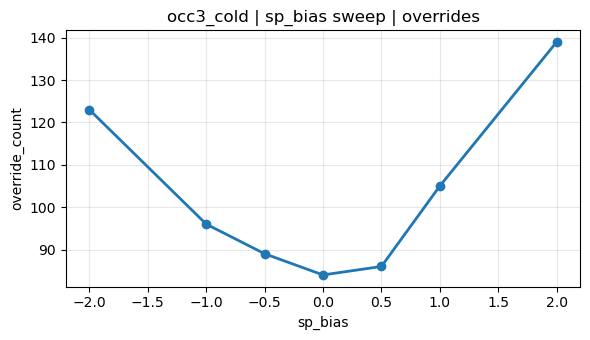

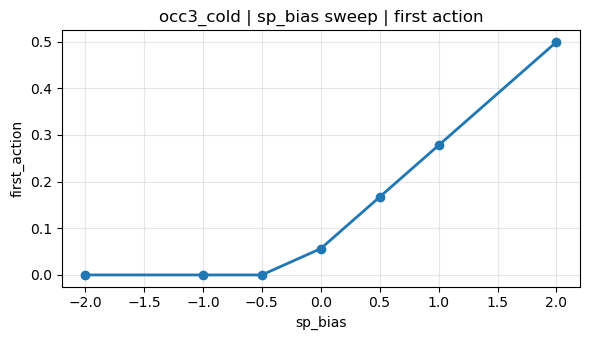

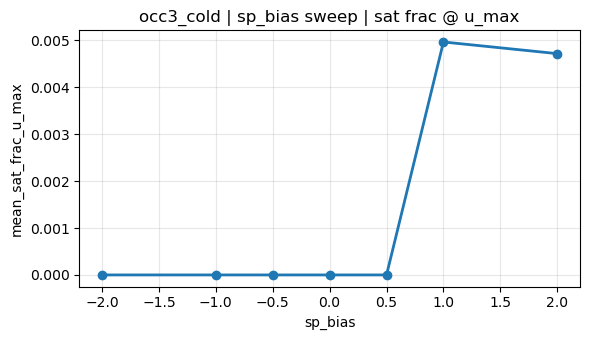

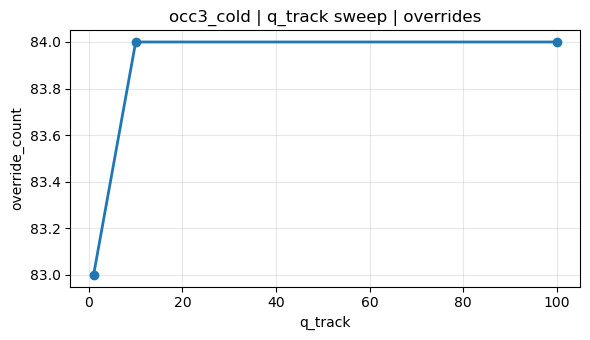

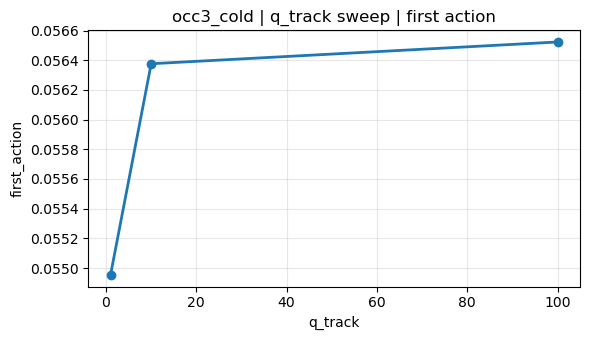

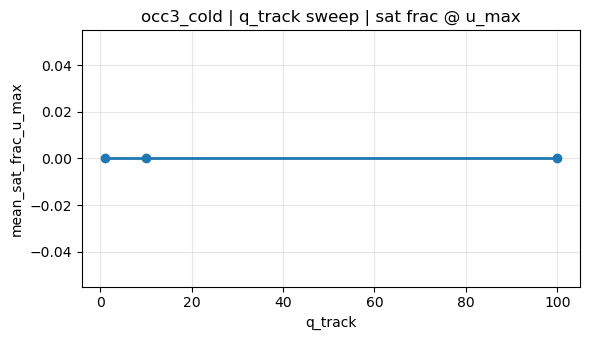

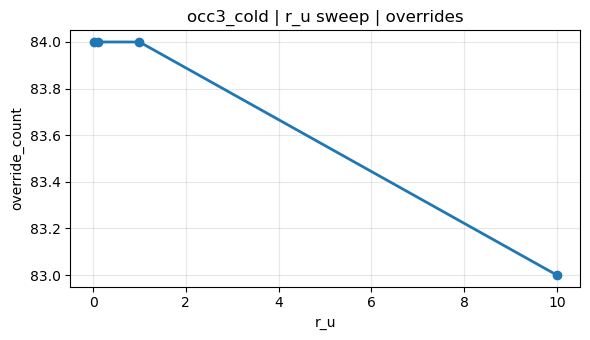

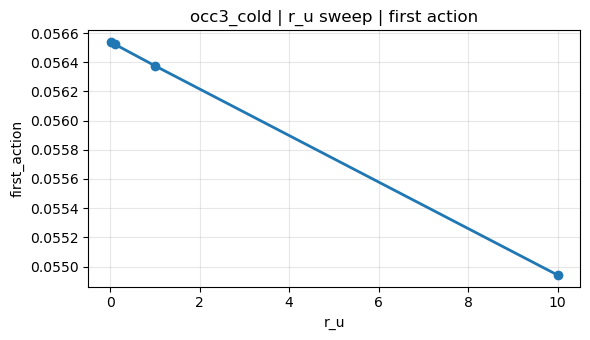

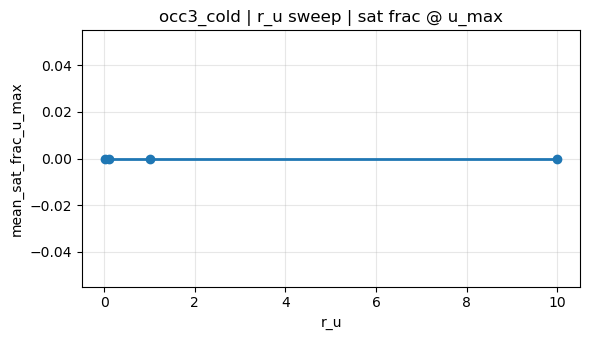

Bias wiring log for sp_bias=+2.0


,time_step,scheduled_sp_raw,effective_sp_observed,learned_bias,qp_target_before_clamp,qp_target_after_clamp,first_action,sat_frac_u_min,sat_frac_u_max,Q_cond_est
0,0,17.222221,17.222221,1.999998,19.222219,19.222219,0.498989,0.0,0.000000,9.998201
1,1,17.222221,17.222221,1.999998,19.222219,19.222219,0.587226,0.0,0.000000,9.998201
2,2,17.222221,18.722221,1.999998,20.722219,20.722219,0.789288,0.0,0.000000,9.998201
3,3,17.222221,18.722221,1.999998,20.722219,20.722219,0.901251,0.0,0.000000,9.998201
4,4,17.486111,18.722221,1.999998,20.722219,20.722219,0.998982,0.0,0.000000,9.998201
5,5,18.888889,20.388889,1.999998,22.388887,22.388887,1.000000,0.0,0.666667,9.998201
6,6,18.888889,20.388889,1.999998,22.388887,22.388887,1.000000,0.0,0.000000,9.998201
7,7,18.273148,20.388889,1.999998,22.388887,22.388887,1.000000,0.0,0.000000,9.998201
8,8,18.888889,18.888889,1.999998,20.888887,20.888887,1.000000,0.0,0.000000,9.998201
9,9,21.111111,21.111111,1.999998,23.111109,23.111109,1.000000,0.0,0.000000,9.998201


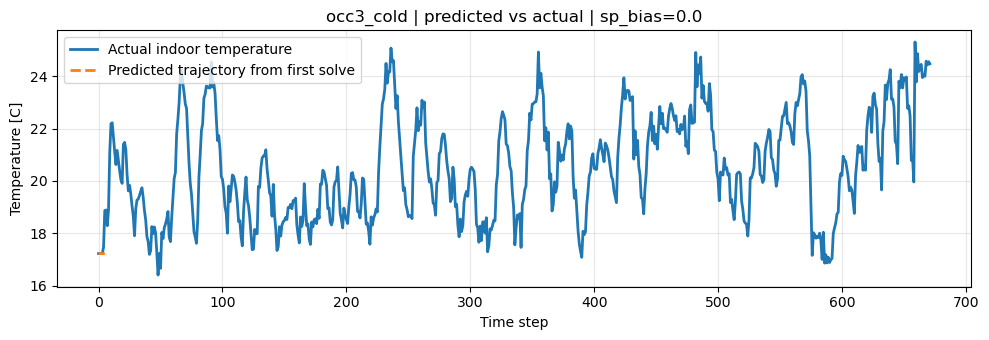

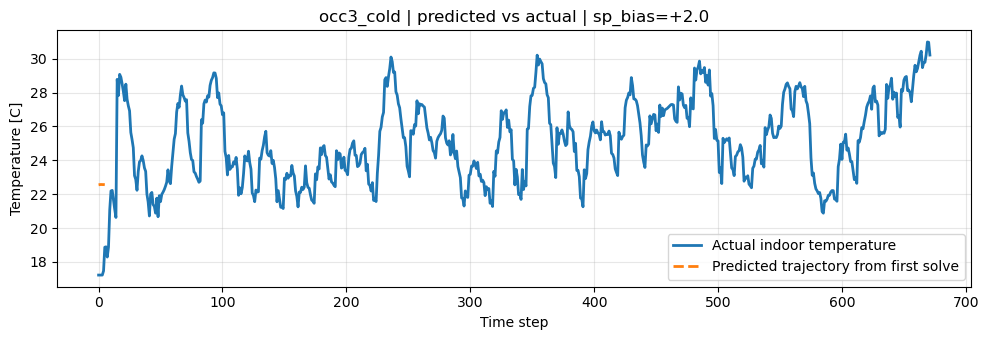

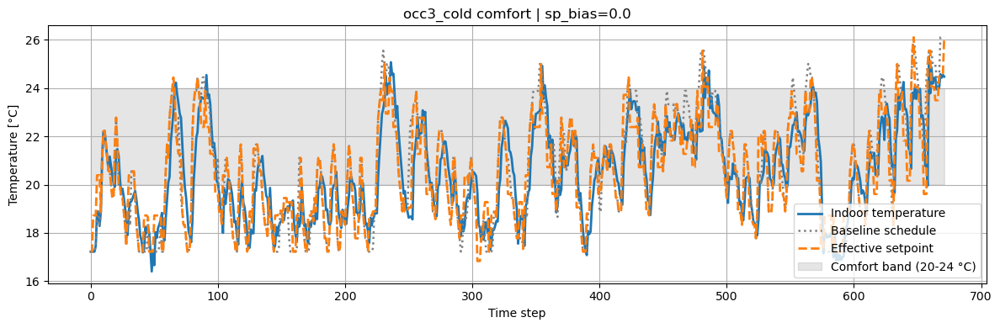

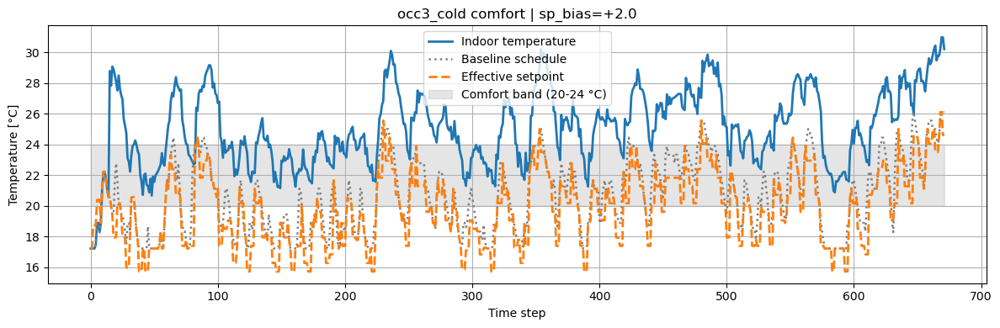

In [68]:
# =========================
# RUN GNU-RL DIAGNOSTIC SWEEPS
# =========================

print(f'Diagnostic occupant: {DIAG_OCCUPANT_LABEL}')
print(f'Diagnostic window: {DIAG_SIM_START}-{DIAG_SIM_END}')

sp_bias_sweep_df, sp_bias_sweep_runs = run_cost_sensitivity_sweep(
    'sp_bias',
    SP_BIAS_SWEEP,
    occupant_label=DIAG_OCCUPANT_LABEL,
)
q_track_sweep_df, q_track_sweep_runs = run_cost_sensitivity_sweep(
    'q_track',
    Q_TRACK_SWEEP,
    occupant_label=DIAG_OCCUPANT_LABEL,
)
r_u_sweep_df, r_u_sweep_runs = run_cost_sensitivity_sweep(
    'r_u',
    R_U_SWEEP,
    occupant_label=DIAG_OCCUPANT_LABEL,
)

print('sp_bias sweep')
display(sp_bias_sweep_df)
print('q_track sweep')
display(q_track_sweep_df)
print('r_u sweep')
display(r_u_sweep_df)

plot_sensitivity_metric(sp_bias_sweep_df, 'override_count', title=f'{DIAG_OCCUPANT_LABEL} | sp_bias sweep | overrides')
plot_sensitivity_metric(sp_bias_sweep_df, 'first_action', title=f'{DIAG_OCCUPANT_LABEL} | sp_bias sweep | first action')
plot_sensitivity_metric(sp_bias_sweep_df, 'mean_sat_frac_u_max', title=f'{DIAG_OCCUPANT_LABEL} | sp_bias sweep | sat frac @ u_max')

plot_sensitivity_metric(q_track_sweep_df, 'override_count', title=f'{DIAG_OCCUPANT_LABEL} | q_track sweep | overrides')
plot_sensitivity_metric(q_track_sweep_df, 'first_action', title=f'{DIAG_OCCUPANT_LABEL} | q_track sweep | first action')
plot_sensitivity_metric(q_track_sweep_df, 'mean_sat_frac_u_max', title=f'{DIAG_OCCUPANT_LABEL} | q_track sweep | sat frac @ u_max')

plot_sensitivity_metric(r_u_sweep_df, 'override_count', title=f'{DIAG_OCCUPANT_LABEL} | r_u sweep | overrides')
plot_sensitivity_metric(r_u_sweep_df, 'first_action', title=f'{DIAG_OCCUPANT_LABEL} | r_u sweep | first action')
plot_sensitivity_metric(r_u_sweep_df, 'mean_sat_frac_u_max', title=f'{DIAG_OCCUPANT_LABEL} | r_u sweep | sat frac @ u_max')

BIAS_WIRING_VALUE = 2.0
bias_wiring_log = sp_bias_sweep_runs[BIAS_WIRING_VALUE]['step_logs'][[
    'time_step',
    'scheduled_sp_raw',
    'effective_sp_observed',
    'learned_bias',
    'qp_target_before_clamp',
    'qp_target_after_clamp',
    'first_action',
    'sat_frac_u_min',
    'sat_frac_u_max',
    'Q_cond_est',
]].copy()

print(f'Bias wiring log for sp_bias={BIAS_WIRING_VALUE:+.1f}')
display(bias_wiring_log.head(30))
plot_diag_temperature(sp_bias_sweep_runs[0.0], title=f'{DIAG_OCCUPANT_LABEL} | predicted vs actual | sp_bias=0.0')
plot_diag_temperature(sp_bias_sweep_runs[BIAS_WIRING_VALUE], title=f'{DIAG_OCCUPANT_LABEL} | predicted vs actual | sp_bias={BIAS_WIRING_VALUE:+.1f}')
plot_comfort(sp_bias_sweep_runs[0.0]['env'], title=f'{DIAG_OCCUPANT_LABEL} comfort | sp_bias=0.0')
plot_comfort(sp_bias_sweep_runs[BIAS_WIRING_VALUE]['env'], title=f'{DIAG_OCCUPANT_LABEL} comfort | sp_bias={BIAS_WIRING_VALUE:+.1f}')


## Occupant Bias MLP With Frozen DiffMPC

Train the bias head offline on January PI occupant data, then compare on February against:
- plain frozen DiffMPC with `sp_bias = 0`
- best constant `sp_bias` tuned on January
- learned dynamic bias MLP


In [112]:
# =========================
# OCCUPANT BIAS MLP + FROZEN DIFFMPC HELPERS
# =========================
from copy import deepcopy
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Tuple
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

BIAS_MLP_CHECKPOINTS = {
    label: NOTEBOOK_DIR / f'occ_bias_mlp_{label}.pt'
    for label in OCCUPANT_JANUARY_SPECS.keys()
}
BIAS_CONSTANT_GRID = [-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0]
BIAS_EVAL_SEEDS = [GLOBAL_EXPERIMENT_SEED]


@dataclass
class BiasFeatureConfig:
    history_len: int = 6
    bias_max: float = 2.0
    hidden_dim: int = 64
    num_hidden_layers: int = 2
    dropout: float = 0.0


class OccupantBiasMLP(nn.Module):
    def __init__(
        self,
        in_dim: int,
        hidden_dim: int = 64,
        num_hidden_layers: int = 2,
        dropout: float = 0.0,
        bias_max: float = 2.0,
    ):
        super().__init__()

        layers = []
        dim_prev = in_dim
        for _ in range(num_hidden_layers):
            layers.append(nn.Linear(dim_prev, hidden_dim))
            layers.append(nn.ReLU())
            if dropout > 0.0:
                layers.append(nn.Dropout(dropout))
            dim_prev = hidden_dim

        layers.append(nn.Linear(dim_prev, 1))
        self.net = nn.Sequential(*layers)
        self.bias_max = float(bias_max)

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        return self.bias_max * torch.tanh(self.net(z))


class BiasFeatureBuffer:
    def __init__(self, history_len: int = 6):
        self.history_len = int(history_len)
        self.reset()

    def reset(self):
        self.hp_action_hist = []
        self.override_signal_hist = []
        self.discomfort_hist = []

    def _last_or_zero(self, values):
        return float(values[-1]) if len(values) > 0 else 0.0

    def _mean_or_zero(self, values):
        return float(np.mean(values)) if len(values) > 0 else 0.0

    def build_feature_vector(
        self,
        Tin: float,
        scheduled_sp_raw: float,
        Tout: float,
        Solar: float,
        time_step: int,
        steps_per_day: int = 24,
    ) -> np.ndarray:
        angle = 2.0 * np.pi * float(time_step % steps_per_day) / float(steps_per_day)
        hour_sin = float(np.sin(angle))
        hour_cos = float(np.cos(angle))

        z = np.array([
            float(Tin),
            float(scheduled_sp_raw),
            float(Tout),
            float(Solar),
            float(Tin - scheduled_sp_raw),
            self._last_or_zero(self.hp_action_hist),
            self._mean_or_zero(self.hp_action_hist),
            self._last_or_zero(self.override_signal_hist),
            self._mean_or_zero(self.override_signal_hist),
            self._mean_or_zero(self.discomfort_hist),
            hour_sin,
            hour_cos,
        ], dtype=np.float32)
        return z

    def update(self, hp_action: float, override_signal: float, discomfort_proxy: float):
        self.hp_action_hist.append(float(hp_action))
        self.override_signal_hist.append(float(override_signal))
        self.discomfort_hist.append(float(discomfort_proxy))

        if len(self.hp_action_hist) > self.history_len:
            self.hp_action_hist = self.hp_action_hist[-self.history_len:]
        if len(self.override_signal_hist) > self.history_len:
            self.override_signal_hist = self.override_signal_hist[-self.history_len:]
        if len(self.discomfort_hist) > self.history_len:
            self.discomfort_hist = self.discomfort_hist[-self.history_len:]


def set_all_seeds(seed: int):
    np.random.seed(int(seed))
    random.seed(int(seed))
    torch.manual_seed(int(seed))
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(int(seed))


class PersonalizedDiffMPCActor(nn.Module):
    def __init__(
        self,
        mpc_actor: nn.Module,
        bias_net: OccupantBiasMLP,
        x_mean: torch.Tensor,
        x_std: torch.Tensor,
        norm_d_fn,
        feature_mean: Optional[torch.Tensor] = None,
        feature_std: Optional[torch.Tensor] = None,
    ):
        super().__init__()
        self.mpc = mpc_actor
        self.bias_net = bias_net

        for p in self.mpc.parameters():
            p.requires_grad = False

        self.register_buffer('x_mean', torch.as_tensor(x_mean).float().reshape(1))
        self.register_buffer('x_std', torch.as_tensor(x_std).float().reshape(1))

        if feature_mean is not None:
            self.register_buffer('feature_mean', torch.as_tensor(feature_mean).float())
        else:
            self.feature_mean = None

        if feature_std is not None:
            self.register_buffer('feature_std', torch.as_tensor(feature_std).float())
        else:
            self.feature_std = None

        self.norm_d_fn = norm_d_fn

    def normalize_features(self, z: torch.Tensor) -> torch.Tensor:
        if self.feature_mean is None or self.feature_std is None:
            return z
        return (z - self.feature_mean) / torch.clamp(self.feature_std, min=1e-6)

    def forward(
        self,
        x_t_phys: torch.Tensor,
        t_sched_phys_seq: torch.Tensor,
        d_phys_seq: torch.Tensor,
        z: torch.Tensor,
        w_seq: Optional[torch.Tensor] = None,
    ) -> Dict[str, torch.Tensor]:
        z_norm = self.normalize_features(z)
        b_sp = self.bias_net(z_norm)

        if t_sched_phys_seq.ndim == 2:
            t_sched_phys_seq = t_sched_phys_seq.unsqueeze(1)

        B, H, _ = d_phys_seq.shape
        if t_sched_phys_seq.shape[1] == 1:
            t_sched_phys_seq = t_sched_phys_seq.repeat(1, H, 1)

        t_ref_phys_seq = t_sched_phys_seq + b_sp.unsqueeze(1)
        x_t = (x_t_phys - self.x_mean) / self.x_std

        d_flat = d_phys_seq.reshape(-1, d_phys_seq.shape[-1])
        d_norm_flat = self.norm_d_fn(d_flat)
        d_seq = d_norm_flat.reshape(B, H, -1)

        sp_seq = (t_ref_phys_seq - self.x_mean) / self.x_std

        if w_seq is None:
            w_seq = torch.zeros((B, H, 1), dtype=x_t.dtype, device=x_t.device)

        u0, u_seq, x_seq = self.mpc(x_t, d_seq, sp_seq, w_seq)
        return {
            'bias': b_sp,
            't_ref_phys_seq': t_ref_phys_seq,
            'u0': u0,
            'u_seq': u_seq,
            'x_seq': x_seq,
        }


def load_bias_mlp_checkpoint(path: str, device: torch.device):
    ckpt = torch.load(path, map_location=device)
    config_dict = ckpt['config']
    feature_cols = ckpt['feature_cols']
    feature_mean = ckpt['feature_mean']
    feature_std = ckpt['feature_std']

    model = OccupantBiasMLP(
        in_dim=len(feature_cols),
        hidden_dim=config_dict['hidden_dim'],
        num_hidden_layers=config_dict['num_hidden_layers'],
        dropout=config_dict['dropout'],
        bias_max=config_dict['bias_max'],
    ).to(device)
    model.load_state_dict(ckpt['model_state_dict'])
    model.eval()
    return model, feature_cols, feature_mean, feature_std, ckpt


def load_frozen_diffmpc_for_occupant(label, horizon=None):
    horizon = OFFLINE_HORIZON if horizon is None else int(horizon)
    checkpoint_path = OCCUPANT_JANUARY_SPECS[label]['checkpoint_path']
    mpc = PaperDiffMPC(
        T=horizon,
        eta=DIFFMPC_ETA,
        rho_u=1.0,
        dt=1.0,
        u_min=DIFFMPC_U_MIN,
        u_max=DIFFMPC_U_MAX,
    ).to(device)
    mpc.load_state_dict(torch.load(checkpoint_path, map_location=device), strict=False)
    freeze_dynamics_parameters(mpc)
    mpc.eval()
    return mpc


def d_phys_forecast_from_obs(obs, horizon):
    o = np.asarray(obs, dtype=np.float32).reshape(-1)
    tout = [o[IDX_T_OUT], o[IDX_TOUT_P1], o[IDX_TOUT_P2], o[IDX_TOUT_P3]]
    sol = [o[IDX_SOLAR], o[IDX_SOL_P1], o[IDX_SOL_P2], o[IDX_SOL_P3]]
    tout_h = [tout[min(i, 3)] for i in range(horizon)]
    sol_h = [sol[min(i, 3)] for i in range(horizon)]
    return torch.tensor(np.stack([tout_h, sol_h], axis=1)[None, :, :], dtype=torch.float32, device=device)


def scheduled_sp_forecast_from_env(env, start_idx, horizon):
    bld = env.unwrapped.buildings[0]
    sched = np.asarray(
        bld.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control,
        dtype=np.float32,
    )
    start_idx = int(np.clip(start_idx, 0, len(sched) - 1))
    end = min(start_idx + horizon, len(sched))
    seq = sched[start_idx:end]
    if len(seq) < horizon:
        seq = np.concatenate([seq, np.full(horizon - len(seq), seq[-1], dtype=np.float32)])
    return torch.tensor(seq.reshape(1, horizon, 1), dtype=torch.float32, device=device)


class PersonalizedDiffMPCPolicyRaw:
    def __init__(
        self,
        env,
        mpc,
        bundle,
        history_len: int = 6,
        fixed_bias: float = 0.0,
        bias_net: Optional[OccupantBiasMLP] = None,
        feature_mean: Optional[np.ndarray] = None,
        feature_std: Optional[np.ndarray] = None,
    ):
        self.env = env
        self.mpc = mpc
        self.bundle = bundle
        self.fixed_bias = float(fixed_bias)
        self.bias_net = bias_net
        self.feature_buffer = BiasFeatureBuffer(history_len=history_len)
        self.gamma = 0.2
        self.x_mean = bundle['x_mean']
        self.x_std = bundle['x_std']
        self.norm_d = bundle['norm_d']

        self.personalized_actor = None
        if self.bias_net is not None:
            self.personalized_actor = PersonalizedDiffMPCActor(
                mpc_actor=self.mpc,
                bias_net=self.bias_net,
                x_mean=self.x_mean,
                x_std=self.x_std,
                norm_d_fn=self.norm_d,
                feature_mean=feature_mean,
                feature_std=feature_std,
            ).to(device)
            self.personalized_actor.eval()

        self.reset()

    def reset(self):
        self.w = 0.0
        self.prev_x = None
        self.prev_u = None
        self.prev_Tout = None
        self.prev_Isol = None
        self.last_action = 0.0
        self.last_bias = 0.0
        self.last_t_ref = None
        self.last_scheduled_sp = None
        self.bias_trace = []
        self.reference_trace = []
        self.scheduled_trace = []
        self.feature_buffer.reset()

    @torch.no_grad()
    def predict(self, obs):
        o = np.asarray(obs, dtype=np.float32).reshape(-1)
        Tin = float(o[IDX_T_IN])
        Tout = float(o[IDX_T_OUT])
        Solar = float(o[IDX_SOLAR])

        bld = self.env.unwrapped.buildings[0]
        t_idx = int(bld.time_step)
        scheduled_sp_raw = float(
            bld.energy_simulation.indoor_dry_bulb_temperature_heating_set_point_without_control[t_idx]
        )
        t_sched_phys_seq = scheduled_sp_forecast_from_env(self.env, t_idx, self.mpc.T)

        x = (Tin - self.x_mean.item()) / self.x_std.item()

        if self.prev_x is not None:
            C = float(self.mpc._pos(self.mpc.C_raw).item())
            Rm = float(self.mpc._pos(self.mpc.Rm_raw).item())
            Rout = float(self.mpc._pos(self.mpc.Rout_raw).item())
            Aeff = float(self.mpc._pos(self.mpc.Aeff_raw).item())
            Pnom = float(self.mpc._pos(self.mpc.Pnom_raw).item())

            Ac = -(1.0 / (Rm * C) + 1.0 / (Rout * C))
            A = np.exp(Ac * self.mpc.dt)
            phi = (A - 1.0) / Ac if abs(Ac) > 1e-8 else self.mpc.dt

            cop = float(self.mpc.cop_a.item() + self.mpc.cop_b.item() * self.prev_Tout)
            cop = float(np.clip(cop, self.mpc.cop_min, self.mpc.cop_max))

            Bu = phi * (cop * Pnom / C)
            Bd0 = phi * (1.0 / (Rm * C))
            Bd1 = phi * (1.0 / (Rout * C))
            Bd2 = phi * (Aeff / C)

            x_pred = (
                A * self.prev_x
                + Bu * self.prev_u
                + Bd0 * float(self.mpc.Tm.item())
                + Bd1 * self.prev_Tout
                + Bd2 * self.prev_Isol
                + self.w
            )
            self.w += self.gamma * (x - x_pred)

        z_np = self.feature_buffer.build_feature_vector(
            Tin=Tin,
            scheduled_sp_raw=scheduled_sp_raw,
            Tout=Tout,
            Solar=Solar,
            time_step=t_idx,
            steps_per_day=24,
        )
        z_t = torch.tensor(z_np[None, :], dtype=torch.float32, device=device)
        x_t_phys = torch.tensor([[Tin]], dtype=torch.float32, device=device)
        d_phys_seq = d_phys_forecast_from_obs(o, self.mpc.T)
        w_seq = torch.full((1, self.mpc.T, 1), float(self.w), dtype=torch.float32, device=device)

        if self.personalized_actor is not None:
            out = self.personalized_actor(
                x_t_phys=x_t_phys,
                t_sched_phys_seq=t_sched_phys_seq,
                d_phys_seq=d_phys_seq,
                z=z_t,
                w_seq=w_seq,
            )
            u0 = float(out['u0'].item())
            b_hat = float(out['bias'].item())
            t_ref = float(out['t_ref_phys_seq'][0, 0, 0].item())
        else:
            b_hat = float(np.clip(self.fixed_bias, -self.mpc.sp_bias_max, self.mpc.sp_bias_max))
            t_ref_phys_seq = t_sched_phys_seq + b_hat
            x_t = (x_t_phys - self.x_mean) / self.x_std
            d_flat = d_phys_seq.reshape(-1, d_phys_seq.shape[-1])
            d_seq = self.norm_d(d_flat).reshape(1, self.mpc.T, -1)
            sp_seq = (t_ref_phys_seq - self.x_mean) / self.x_std
            u0_t, _, _ = self.mpc(x_t, d_seq, sp_seq, w_seq)
            u0 = float(u0_t.item())
            t_ref = float(t_ref_phys_seq[0, 0, 0].item())

        self.last_action = u0
        self.last_bias = b_hat
        self.last_t_ref = t_ref
        self.last_scheduled_sp = scheduled_sp_raw
        self.prev_x = x
        self.prev_u = u0
        self.prev_Tout = Tout
        self.prev_Isol = Solar
        self.bias_trace.append(b_hat)
        self.reference_trace.append(t_ref)
        self.scheduled_trace.append(scheduled_sp_raw)

        return [np.array([u0], dtype=np.float32)]

    def post_step(self):
        bld = self.env.unwrapped.buildings[0]
        # Use the just-finished step, not the already-advanced step.
        t_idx = max(int(bld.time_step) - 1, 0)
        feedback_signal = float(bld.energy_simulation.occupant_feedback_signal[t_idx])
        Tin_now = float(bld.energy_simulation.indoor_dry_bulb_temperature[t_idx])
        T_eff_now = float(bld.energy_simulation.indoor_dry_bulb_temperature_heating_set_point[t_idx])
        discomfort_proxy = abs(Tin_now - T_eff_now)
        self.feature_buffer.update(
            hp_action=self.last_action,
            override_signal=feedback_signal,
            discomfort_proxy=discomfort_proxy,
        )


def rollout_personalized_diffmpc(policy, env, seed: Optional[int] = None):
    if seed is not None:
        set_all_seeds(seed)

    try:
        obs, _ = env.reset(seed=seed)
    except TypeError:
        obs, _ = env.reset()

    policy.reset()
    terminated = truncated = False
    reward_sum = 0.0

    while not (terminated or truncated):
        action = policy.predict(obs)
        obs, reward, terminated, truncated, _ = env.step(action)
        reward_sum += float(np.asarray(reward, dtype=np.float32).reshape(-1)[0])
        policy.post_step()

    env.learned_bias_trace = np.asarray(policy.bias_trace, dtype=np.float32)
    env.reference_setpoint_trace = np.asarray(policy.reference_trace, dtype=np.float32)
    env.scheduled_setpoint_trace = np.asarray(policy.scheduled_trace, dtype=np.float32)
    env.effective_setpoints = np.asarray(policy.reference_trace, dtype=np.float32)
    env.baseline_setpoints = np.asarray(policy.scheduled_trace, dtype=np.float32)
    return reward_sum


def evaluate_fixed_bias_case(label, occupant, bundle, bias_value, sim_start, sim_end, seed: int = 0):
    set_all_seeds(seed)
    env = make_env_raw(sim_start=sim_start, sim_end=sim_end, reward_function=OccupantFeedbackReward)
    env = OccupantWrapper(env, deepcopy(occupant))
    mpc = load_frozen_diffmpc_for_occupant(label, horizon=OFFLINE_HORIZON)
    policy = PersonalizedDiffMPCPolicyRaw(
        env=env,
        mpc=mpc,
        bundle=bundle,
        history_len=6,
        fixed_bias=bias_value,
        bias_net=None,
    )
    reward_sum = rollout_personalized_diffmpc(policy, env, seed=seed)
    district_kpis = env.unwrapped.evaluate().copy()
    district_kpis = district_kpis[district_kpis['level'] == 'district'].copy()
    return {
        'seed': int(seed),
        'reward': float(reward_sum),
        'override_count': int(getattr(env, 'override_count', 0)),
        'district_kpis': district_kpis,
        'env': env,
        'bias_value': float(bias_value),
    }


def evaluate_learned_bias_case(label, occupant, bundle, sim_start, sim_end, seed: int = 0):
    set_all_seeds(seed)
    ckpt_path = BIAS_MLP_CHECKPOINTS[label]
    if not ckpt_path.exists():
        raise FileNotFoundError(f'Missing bias MLP checkpoint for {label}: {ckpt_path}')

    bias_model, feature_cols, feature_mean, feature_std, ckpt = load_bias_mlp_checkpoint(ckpt_path, device=device)
    env = make_env_raw(sim_start=sim_start, sim_end=sim_end, reward_function=OccupantFeedbackReward)
    env = OccupantWrapper(env, deepcopy(occupant))
    mpc = load_frozen_diffmpc_for_occupant(label, horizon=OFFLINE_HORIZON)
    history_len = int(ckpt['config'].get('history_len', 6)) if 'history_len' in ckpt['config'] else 6
    policy = PersonalizedDiffMPCPolicyRaw(
        env=env,
        mpc=mpc,
        bundle=bundle,
        history_len=history_len,
        fixed_bias=0.0,
        bias_net=bias_model,
        feature_mean=feature_mean,
        feature_std=feature_std,
    )
    reward_sum = rollout_personalized_diffmpc(policy, env, seed=seed)
    district_kpis = env.unwrapped.evaluate().copy()
    district_kpis = district_kpis[district_kpis['level'] == 'district'].copy()
    return {
        'seed': int(seed),
        'reward': float(reward_sum),
        'override_count': int(getattr(env, 'override_count', 0)),
        'district_kpis': district_kpis,
        'env': env,
        'checkpoint': ckpt,
    }


def aggregate_seeded_runs(runs):
    reward_vals = np.array([run['reward'] for run in runs], dtype=np.float32)
    override_vals = np.array([run['override_count'] for run in runs], dtype=np.float32)

    cost_names = sorted({
        name
        for run in runs
        for name in run['district_kpis']['cost_function'].tolist()
    })
    kpi_rows = []
    for cost_name in cost_names:
        vals = []
        for run in runs:
            rows = run['district_kpis'][run['district_kpis']['cost_function'] == cost_name]['value']
            if len(rows) > 0:
                vals.append(float(rows.iloc[0]))
        if len(vals) > 0:
            kpi_rows.append({
                'level': 'district',
                'cost_function': cost_name,
                'value': float(np.mean(vals)),
            })

    return {
        'runs': runs,
        'seed_list': [int(run['seed']) for run in runs],
        'reward_mean': float(np.mean(reward_vals)),
        'reward_std': float(np.std(reward_vals)),
        'override_count_mean': float(np.mean(override_vals)),
        'override_count_std': float(np.std(override_vals)),
        'district_kpis': pd.DataFrame(kpi_rows),
        'env': runs[0]['env'],
    }


def evaluate_policy_over_seeds(run_fn, seeds=None):
    seeds = BIAS_EVAL_SEEDS if seeds is None else list(seeds)
    runs = [run_fn(int(seed)) for seed in seeds]
    return aggregate_seeded_runs(runs)


def find_best_constant_bias_on_january(label, occupant, bundle, bias_grid=None, seeds=None):
    bias_grid = BIAS_CONSTANT_GRID if bias_grid is None else list(bias_grid)
    seeds = BIAS_EVAL_SEEDS if seeds is None else list(seeds)
    rows = []
    runs = {}

    for bias_value in bias_grid:
        agg = evaluate_policy_over_seeds(
            lambda seed: evaluate_fixed_bias_case(
                label=label,
                occupant=deepcopy(occupant),
                bundle=bundle,
                bias_value=bias_value,
                sim_start=JAN_START,
                sim_end=JAN_END,
                seed=seed,
            ),
            seeds=seeds,
        )
        rows.append({
            'bias_value': float(bias_value),
            'override_count_mean': float(agg['override_count_mean']),
            'override_count_std': float(agg['override_count_std']),
            'reward_mean': float(agg['reward_mean']),
            'reward_std': float(agg['reward_std']),
            'electricity_consumption_total': summarize_district_kpis_local(label, agg['district_kpis'], agg['reward_mean'], agg['override_count_mean'])['electricity_consumption_total'],
            'discomfort_proportion': summarize_district_kpis_local(label, agg['district_kpis'], agg['reward_mean'], agg['override_count_mean'])['discomfort_proportion'],
        })
        runs[float(bias_value)] = agg

    sweep_df = pd.DataFrame(rows).sort_values(
        ['override_count_mean', 'reward_mean'],
        ascending=[True, False],
    ).reset_index(drop=True)
    best_bias = float(sweep_df.iloc[0]['bias_value'])
    return best_bias, sweep_df, runs



🔥 Bias MLP transfer: occ1_tolerant


/home/kostas/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=2.19041e-11): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

...


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/tmp/ipykernel_6000/3454922378.py:205: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(path, map_location=device)
/home/kostas/school/Y2/Zoltan/annex96_commo


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

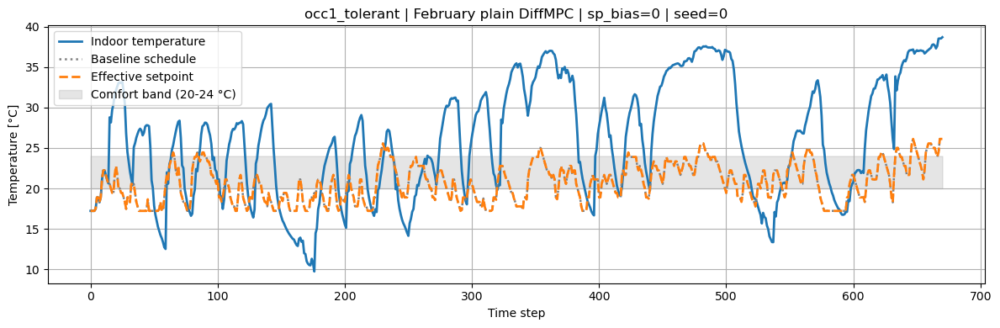

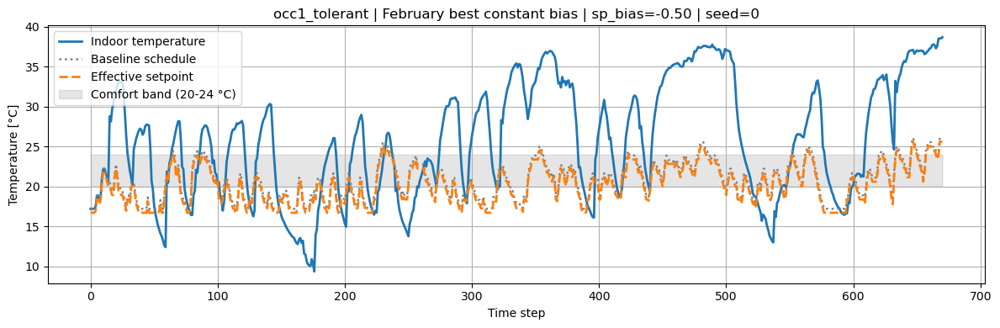

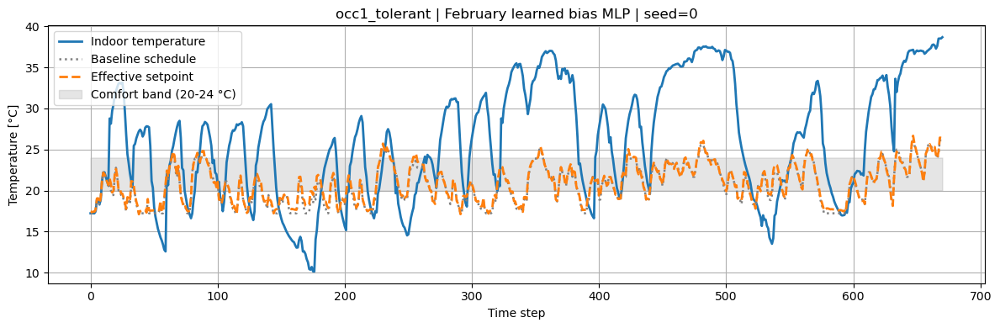


🔥 Bias MLP transfer: occ2_sensitive


/home/kostas/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=2.19037e-11): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

...


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/tmp/ipykernel_6000/3454922378.py:205: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(path, map_location=device)
/home/kostas/school/Y2/Zoltan/annex96_commo


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

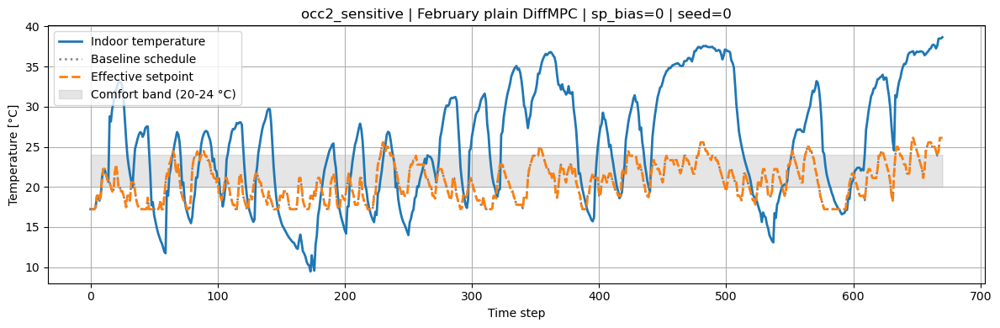

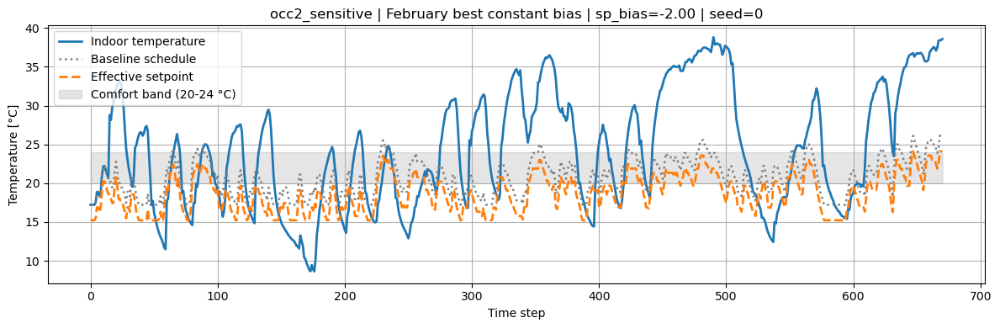

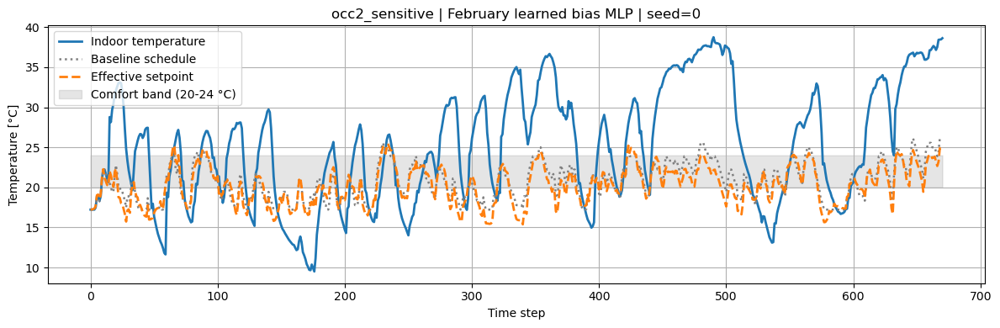


🔥 Bias MLP transfer: occ3_cold


/home/kostas/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=2.19029e-11): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

...


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/tmp/ipykernel_6000/3454922378.py:205: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(path, map_location=device)
/home/kostas/school/Y2/Zoltan/annex96_commo


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

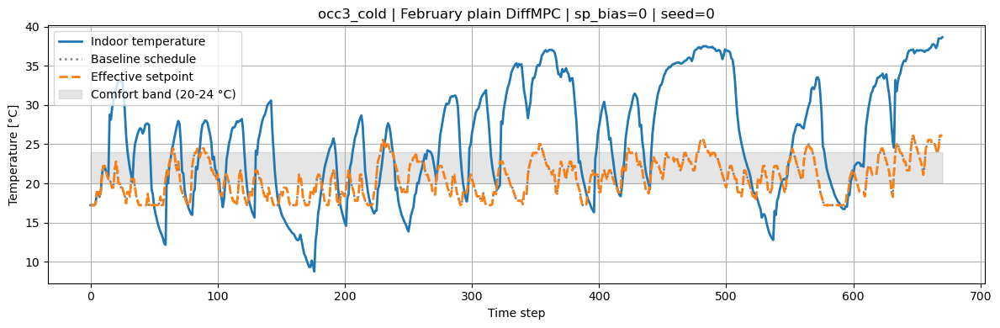

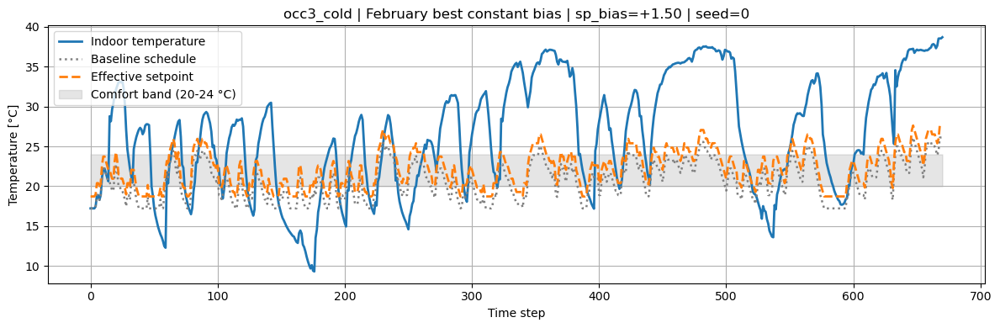

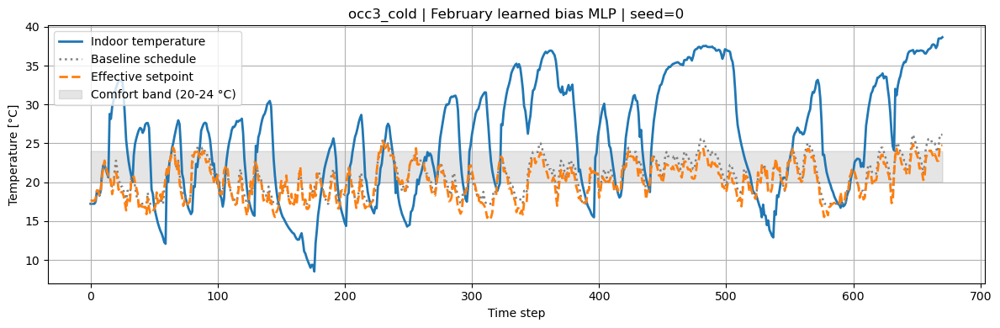


🔥 Bias MLP transfer: occ4_hot


/home/kostas/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:216: LinAlgWarning: Ill-conditioned matrix (rcond=2.18902e-11): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

...


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/home/kostas/school/Y2/Zoltan/annex96_common_exercise_1/citylearn/dynamics.py:118: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_state_dict(torch.load(self.filepat


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

/tmp/ipykernel_6000/3454922378.py:205: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(path, map_location=device)
/home/kostas/school/Y2/Zoltan/annex96_commo


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an inaccurate and potentially incorrect solution.

Some residual is large.
Your problem may be infeasible or difficult.

You can try using the CVXPY solver to see if your problem is feasible
and you can use the verbose option to check the convergence status of
our solver while increasing the number of iterations.

Advanced users:
You can also try to enable iterative refinement in the solver:
https://github.com/locuslab/qpth/issues/6
--------


--------
qpth warning: Returning an i

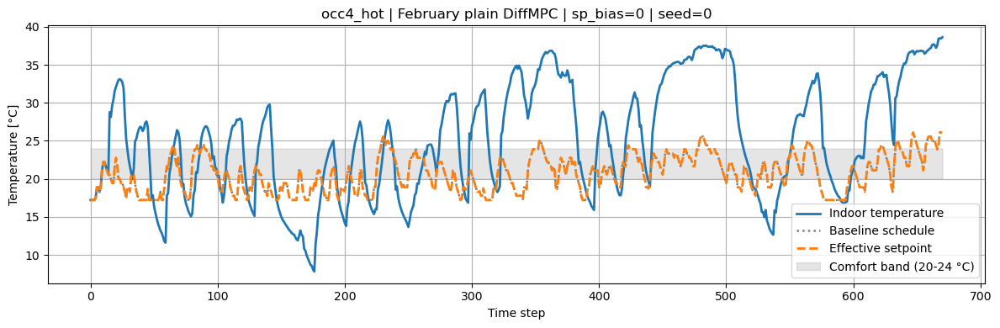

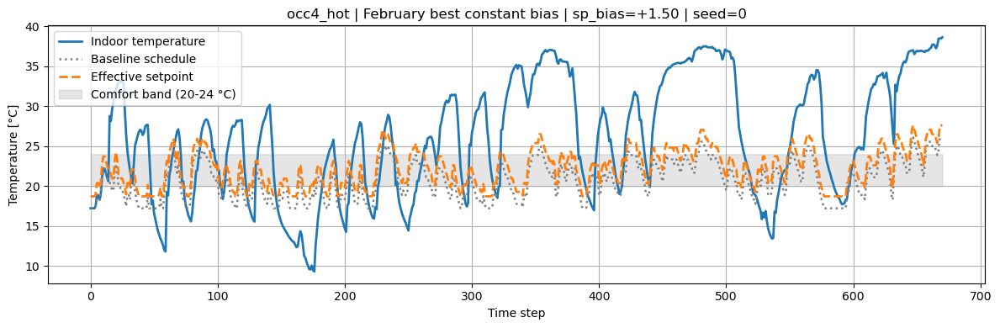

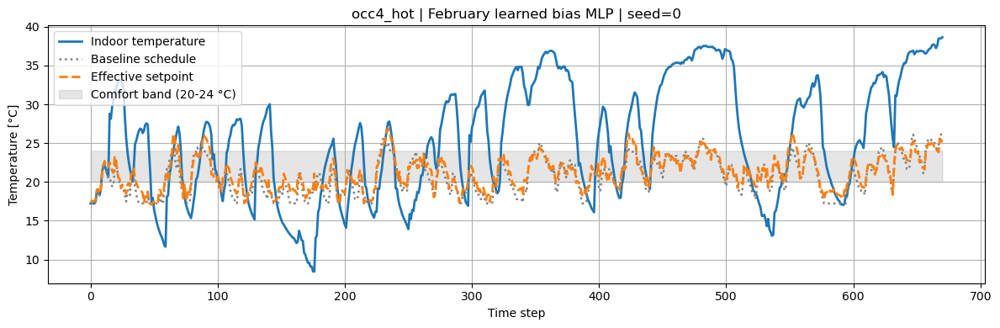

,occupant,eval_seeds,best_constant_bias_jan,feb_plain_overrides_mean,feb_plain_overrides_std,feb_const_overrides_mean,feb_const_overrides_std,feb_mlp_overrides_mean,feb_mlp_overrides_std,feb_mlp_delta_vs_plain,feb_mlp_delta_vs_const,feb_plain_reward_mean,feb_const_reward_mean,feb_mlp_reward_mean,feb_mlp_electricity_consumption_total,feb_mlp_discomfort_proportion,feb_mlp_discomfort_cold_proportion,feb_mlp_discomfort_hot_proportion,feb_mlp_daily_peak_average
0,occ1_tolerant,0,-0.5,109.0,0.0,107.0,0.0,109.0,0.0,0.0,2.0,-410.491699,-399.398102,-410.586243,1.489825,0.806107,0.131298,0.674809,1.322016
1,occ2_sensitive,0,-2.0,134.0,0.0,136.0,0.0,136.0,0.0,2.0,0.0,-494.738281,-495.558807,-497.631744,1.417303,0.780153,0.163359,0.616794,1.309790
2,occ3_cold,0,1.5,131.0,0.0,132.0,0.0,131.0,0.0,0.0,-1.0,-485.462921,-490.882446,-482.883423,1.453418,0.800000,0.166412,0.633588,1.316594
3,occ4_hot,0,1.5,135.0,0.0,129.0,0.0,130.0,0.0,-5.0,1.0,-494.681274,-480.084351,-479.697144,1.468779,0.819847,0.195420,0.624427,1.325701


In [113]:
# =========================
# RUN OCCUPANT BIAS MLP FEBRUARY TRANSFER EXPERIMENTS
# =========================
BIAS_TRANSFER_RESULTS = {}
BIAS_TRANSFER_SUMMARY_ROWS = []

for label, occupant in OCCUPANT_EXPERIMENTS.items():
    print()
    print("=" * 80)
    print(f"🔥 Bias MLP transfer: {label}")
    print("=" * 80)
    bundle = load_offline_bundle(OCCUPANT_JANUARY_SPECS[label]['dataset_path'])

    best_const_bias, january_const_sweep_df, january_const_runs = find_best_constant_bias_on_january(
        label=label,
        occupant=deepcopy(occupant),
        bundle=bundle,
        bias_grid=BIAS_CONSTANT_GRID,
        seeds=BIAS_EVAL_SEEDS,
    )
    print(f'{label} | best constant January bias = {best_const_bias:+.3f}')
    display(january_const_sweep_df)

    feb_plain = evaluate_policy_over_seeds(
        lambda seed: evaluate_fixed_bias_case(
            label=label,
            occupant=deepcopy(occupant),
            bundle=bundle,
            bias_value=0.0,
            sim_start=FEB_START,
            sim_end=FEB_END,
            seed=seed,
        ),
        seeds=BIAS_EVAL_SEEDS,
    )
    feb_const = evaluate_policy_over_seeds(
        lambda seed: evaluate_fixed_bias_case(
            label=label,
            occupant=deepcopy(occupant),
            bundle=bundle,
            bias_value=best_const_bias,
            sim_start=FEB_START,
            sim_end=FEB_END,
            seed=seed,
        ),
        seeds=BIAS_EVAL_SEEDS,
    )
    feb_mlp = evaluate_policy_over_seeds(
        lambda seed: evaluate_learned_bias_case(
            label=label,
            occupant=deepcopy(occupant),
            bundle=bundle,
            sim_start=FEB_START,
            sim_end=FEB_END,
            seed=seed,
        ),
        seeds=BIAS_EVAL_SEEDS,
    )

    print(
        f"{label} | February overrides mean±std | "
        f"plain={feb_plain['override_count_mean']:.2f}±{feb_plain['override_count_std']:.2f} | "
        f"const={feb_const['override_count_mean']:.2f}±{feb_const['override_count_std']:.2f} | "
        f"mlp={feb_mlp['override_count_mean']:.2f}±{feb_mlp['override_count_std']:.2f}"
    )
    plot_comfort(feb_plain['env'], title=f'{label} | February plain DiffMPC | sp_bias=0 | seed={feb_plain["seed_list"][0]}')
    plot_comfort(feb_const['env'], title=f'{label} | February best constant bias | sp_bias={best_const_bias:+.2f} | seed={feb_const["seed_list"][0]}')
    plot_comfort(feb_mlp['env'], title=f'{label} | February learned bias MLP | seed={feb_mlp["seed_list"][0]}')

    BIAS_TRANSFER_RESULTS[label] = {
        'best_constant_bias': best_const_bias,
        'january_constant_sweep': january_const_sweep_df,
        'january_constant_runs': january_const_runs,
        'feb_plain': feb_plain,
        'feb_const': feb_const,
        'feb_mlp': feb_mlp,
    }

    kpi_plain = summarize_district_kpis_local(label, feb_plain['district_kpis'], feb_plain['reward_mean'], feb_plain['override_count_mean'])
    kpi_const = summarize_district_kpis_local(label, feb_const['district_kpis'], feb_const['reward_mean'], feb_const['override_count_mean'])
    kpi_mlp = summarize_district_kpis_local(label, feb_mlp['district_kpis'], feb_mlp['reward_mean'], feb_mlp['override_count_mean'])

    BIAS_TRANSFER_SUMMARY_ROWS.append({
        'occupant': label,
        'eval_seeds': ','.join(str(s) for s in BIAS_EVAL_SEEDS),
        'best_constant_bias_jan': float(best_const_bias),
        'feb_plain_overrides_mean': float(feb_plain['override_count_mean']),
        'feb_plain_overrides_std': float(feb_plain['override_count_std']),
        'feb_const_overrides_mean': float(feb_const['override_count_mean']),
        'feb_const_overrides_std': float(feb_const['override_count_std']),
        'feb_mlp_overrides_mean': float(feb_mlp['override_count_mean']),
        'feb_mlp_overrides_std': float(feb_mlp['override_count_std']),
        'feb_mlp_delta_vs_plain': float(feb_mlp['override_count_mean'] - feb_plain['override_count_mean']),
        'feb_mlp_delta_vs_const': float(feb_mlp['override_count_mean'] - feb_const['override_count_mean']),
        'feb_plain_reward_mean': float(feb_plain['reward_mean']),
        'feb_const_reward_mean': float(feb_const['reward_mean']),
        'feb_mlp_reward_mean': float(feb_mlp['reward_mean']),
        'feb_mlp_electricity_consumption_total': kpi_mlp['electricity_consumption_total'],
        'feb_mlp_discomfort_proportion': kpi_mlp['discomfort_proportion'],
        'feb_mlp_discomfort_cold_proportion': kpi_mlp['discomfort_cold_proportion'],
        'feb_mlp_discomfort_hot_proportion': kpi_mlp['discomfort_hot_proportion'],
        'feb_mlp_daily_peak_average': kpi_mlp['daily_peak_average'],
    })

BIAS_TRANSFER_SUMMARY = pd.DataFrame(BIAS_TRANSFER_SUMMARY_ROWS)
display(BIAS_TRANSFER_SUMMARY)
